# **PONTIFICIA UNIVERSIDAD JAVERIANA**
### Taller Census Income — Procesamiento de Alto Volumen de Datos

**Fecha:** 23 de noviembre de 2026<br>
**Autor:** Federico Aragón Ochoa<br>
**Tema:** PySpark con Modelos de Machine Learning<br>
**Dataset:** Census Income (Adult) — UCI Machine Learning Repository<br>

**Descripción:**<br>
Se utiliza PySpark para cargar, limpiar, transformar y analizar el conjunto de datos Census Income (Adult), que contiene información demográfica, educativa y laboral de diferentes personas. Se realizan análisis estadísticos, visualizaciones y modelos de Machine Learning mediante la biblioteca MLlib, con el propósito de identificar patrones y predecir si los ingresos anuales de una persona superan los 50.000 dólares. El desarrollo del taller sigue la metodología CRISP-DM, incluyendo el conocimiento y preparación de los datos, el entrenamiento de modelos, la evaluación de resultados y la selección del modelo con mejor desempeño.<br>

**Objetivo general:**<br>
Implementar y evaluar al menos cinco modelos de Machine Learning utilizando la biblioteca MLlib de PySpark, con el propósito de predecir si los ingresos anuales de una persona superan los 50.000 dólares, basándose en las características del conjunto de datos Census Income (Adult).<br>

**Objetivos específicos:**
* Hacer uso del entorno IDE Python cuaderno: servidor personal.
* Utilizar el dataset Census Income (Adult) de UCI Machine Learning Repository.
* Desplegar la metodología CRISP-DM para el análisis y predicción de ingresos.
* Explorar las diferentes bibliotecas disponibles en PySpark.
* Identificar la forma de instalación de nuevas bibliotecas sobre el kernel por defecto.
* Realizar el conocimiento, limpieza, transformación y preparación de los datos.
* Analizar las características demográficas, educativas y laborales relacionadas con los niveles de ingresos.
* Implementar al menos cinco modelos de clasificación utilizando MLlib.
* Evaluar los modelos mediante métricas de clasificación, matrices de confusión y curvas ROC.
* Comparar los resultados para identificar el modelo con mejor desempeño predictivo.
* Documentar cada etapa del desarrollo del taller.
* Realizar el análisis de resultados y formular conclusiones.

**Modelos de Machine Learning a implementar:**
1. Regresión logística (Logistic Regression).
2. Random Forest.
3. Gradient Boosted Trees (GBT).
4. Support Vector Machine (SVM).
5. Naive Bayes.
6. Multilayer Perceptron (MLP).
7. Árbol de decisión (Decision Tree).

**Variable objetivo:**<br>
Clasificación binaria de los ingresos anuales:
* 0: Ingresos menores o iguales a 50.000 dólares (≤50K).
* 1: Ingresos superiores a 50.000 dólares (>50K).


### **1. Cargar librerias e inicar sesión de Spark**

In [1]:
# Muestra las variables de entorno del sistema donde se esta ejecutando
!env

SHELL=/bin/bash
JUPYTERHUB_SERVICE_URL=http://127.0.0.1:43399/jupyter/user/usuario102/
JUPYTERHUB_API_TOKEN=ee9e0ef650564ac984178fc528f84ad5
JAVA_HOME=/usr/lib/jvm/java-8-openjdk-amd64
JUPYTERHUB_BASE_URL=/jupyter/
JUPYTERHUB_PUBLIC_URL=
PWD=/home/usuario102
JPY_SESSION_NAME=/home/usuario102/AragonSalario_1055(2).ipynb
JUPYTERHUB_SERVER_NAME=
JUPYTERHUB_DEFAULT_URL=/lab
HOME=/home/usuario102
LANG=en_US.UTF-8
JPY_API_TOKEN=ee9e0ef650564ac984178fc528f84ad5
FORCE_COLOR=1
JUPYTERHUB_SERVICE_PREFIX=/jupyter/user/usuario102/
PYDEVD_USE_FRAME_EVAL=NO
JUPYTERHUB_OAUTH_CALLBACK_URL=/jupyter/user/usuario102/oauth_callback
CLICOLOR=1
CLICOLOR_FORCE=1
JUPYTERHUB_SINGLEUSER_APP=jupyter_server.serverapp.ServerApp
JUPYTERHUB_OAUTH_CLIENT_ALLOWED_SCOPES=[]
JPY_PARENT_PID=1659707
TERM=xterm-color
HADOOP_HOME=/mnt/sda1/Cluster/Hadoop
USER=usuario102
GIT_PAGER=cat
JUPYTERHUB_OAUTH_ACCESS_SCOPES=["access:servers!server=usuario102/", "access:servers!user=usuario102"]
JUPYTERHUB_COOKIE_HOST_PREFIX_ENABLED=0

#### Bibliotecas utilizadas
Se presenta la utilidad de las bibliotecas y herramientas importadas para el desarrollo del taller:

- **NumPy:** Realizar operaciones matemáticas y trabajar con arreglos numéricos.
- **Pandas:** Organizar, manipular y analizar datos en tablas.
- **Findspark:** Configurar la ruta de Apache Spark para utilizarlo desde Python.
- **SparkContext y SparkConf:** Configurar y administrar la ejecución de Spark.
- **SparkSession y SQLContext:** Crear sesiones de Spark y consultar datos estructurados.
- **Functions (F):** Aplicar funciones y transformaciones a los datos.
- **DecisionTreeClassifier:** Crear modelos de clasificación mediante árboles de decisión.
- **RandomForestClassifier:** Clasificar datos utilizando varios árboles de decisión.
- **NaiveBayes:** Crear modelos de clasificación basados en probabilidades.
- **MulticlassClassificationEvaluator:** Evaluar el rendimiento de los modelos de clasificación.
- **StandardScaler:** Estandarizar las variables numéricas.
- **StringIndexer:** Convertir categorías de texto en valores numéricos.
- **VectorAssembler y VectorIndexer:** Agrupar variables en vectores e identificar características categóricas.
- **OneHotEncoder:** Convertir variables categóricas en columnas numéricas.
- **Pipeline:** Organizar varias etapas de transformación y modelado.
- **DenseVector:** Representar conjuntos de valores numéricos en un vector.
- **Scikit-learn:** Dividir los datos en conjuntos de entrenamiento y prueba.
- **Garbage Collector (gc):** Liberar memoria de objetos que ya no se utilizan.
- **Seaborn:** Crear gráficos estadísticos para explorar los datos.
- **Matplotlib:** Generar y personalizar gráficos.


In [2]:
#Generic Libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

#Apache spark
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')

#Apache Spark Libraries
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession, SQLContext
from pyspark.sql import functions as F

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

#Garbage
import gc

#Bibliotecas adicionales
import seaborn as sns
import matplotlib.pyplot as plt


#### Configuración de Spark
Se configura e inicia una sesión de Apache Spark para procesar los datos del taller mediante PySpark.

- **SparkConf:** Establece la configuración de Spark y asigna el puerto 37002 para acceder a su interfaz web
- **setAppName:** Define TallerAragonOchoa como nombre de la aplicación.
- **SparkSession:** Crea o reutiliza una sesión de Spark para trabajar con los datos.
- **SQLContext:** Permite realizar consultas y operaciones sobre datos estructurados.
- **SparkContext:** Proporciona acceso al contexto de ejecución de Spark.
- **sparkAragon:** Muestra la información de la sesión creada para verificar su inicialización.


In [3]:
# Sesion Spark
configura = SparkConf().set("spark.ui.port", "37002")
configura.setAppName("TallerAragonOchoa")

# Crear la sesion
sparkAragon = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkAragon, sparkSession=sparkAragon)

sparkContextoAragon = sparkAragon.sparkContext.getOrCreate()

print("Sesion spark del 23 de noviembre")
sparkAragon

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesion spark del 23 de noviembre


### **2. Subir los del dataset en Hadoop HDFS**

Se creó una carpeta personal en Hadoop HDFS y se cargó el archivo adult.data y adult.test desde el entorno de Jupyter Notebook. Finalmente, se verificó que el archivo quedara almacenado correctamente para su posterior procesamiento

In [4]:
## Se crea la carpeta de mi persona para hacer eñ cambio de los formatos y subir el dataset en csv
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1055/Aragon/Salarios

In [5]:
# Se revisa que la carpeta este creada
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Aragon

Found 4 items
-rw-r--r--   2 usuario02 supergroup    2513627 2026-11-16 21:45 /Formatos1055/Aragon/AragonOchoaDataSet.csv
drwxr-xr-x   - usuario02 supergroup          0 2026-11-23 08:42 /Formatos1055/Aragon/Salarios
drwxr-xr-x   - usuario02 supergroup          0 2026-11-23 08:00 /Formatos1055/Aragon/orc1055
drwxr-xr-x   - usuario02 supergroup          0 2026-11-23 08:00 /Formatos1055/Aragon/parquet1055


In [6]:
## Meter el dataset csv que he descargado en mi cuenta jupyter
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put adult.data /Formatos1055/Aragon/Salarios
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put adult.test /Formatos1055/Aragon/Salarios

put: `adult.data': No such file or directory
put: `adult.test': No such file or directory


In [7]:
# Revisar que el archivo este en la carpeta
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Aragon/Salarios

Found 2 items
-rw-r--r--   2 usuario02 supergroup    3974305 2026-11-23 08:42 /Formatos1055/Aragon/Salarios/adult.data
-rw-r--r--   2 usuario02 supergroup    2003153 2026-11-23 08:42 /Formatos1055/Aragon/Salarios/adult.test


### **3. Cargar datos desde Hadoop**

Hadoop HDFS permite almacenar grandes volúmenes de datos de forma distribuida, en este taller, descargaremos el dataset Stroke desde HDFS para analizarlo mediante PySpark.

Beneficios en el mundo real:
- **Escalabilidad:** Permite trabajar con grandes cantidades de datos
- **Almacenamiento distribuido:** Guarda la información en diferentes equipos
- **Acceso centralizado:** Facilita que distintos usuarios y aplicaciones accedan a los datos
- **Tolerancia a fallos:** Reduce el riesgo de pérdida de información mediante la replicación de datos
- **Integración con Spark:** Permite procesar grandes conjuntos de datos de manera distribuida
- **Aplicación empresarial:** Facilita el análisis de información en sectores como salud, banca y comercio


In [8]:
# Rutas de los archivos en HDFS
rutaData = "hdfs://10.195.34.34:9000/Formatos1055/Aragon/Salarios/adult.data"
rutaTest = "hdfs://10.195.34.34:9000/Formatos1055/Aragon/Salarios/adult.test"

# Cargar los datasets
dfData = sparkAragon.read.csv(
    rutaData,
    header=False,
    inferSchema=True
)

dfTest = sparkAragon.read.csv(
    rutaTest,
    header=False,
    inferSchema=True,
    comment="|"
)

# Verificar la carga
print("Registros adult.data:", dfData.count())
print("Registros adult.test:", dfTest.count())

Registros adult.data: 32561
Registros adult.test: 16281


In [9]:
dfData.show(5)

+---+-----------------+--------+----------+----+-------------------+------------------+--------------+------+-------+------+----+----+--------------+------+
|_c0|              _c1|     _c2|       _c3| _c4|                _c5|               _c6|           _c7|   _c8|    _c9|  _c10|_c11|_c12|          _c13|  _c14|
+---+-----------------+--------+----------+----+-------------------+------------------+--------------+------+-------+------+----+----+--------------+------+
| 39|        State-gov| 77516.0| Bachelors|13.0|      Never-married|      Adm-clerical| Not-in-family| White|   Male|2174.0| 0.0|40.0| United-States| <=50K|
| 50| Self-emp-not-inc| 83311.0| Bachelors|13.0| Married-civ-spouse|   Exec-managerial|       Husband| White|   Male|   0.0| 0.0|13.0| United-States| <=50K|
| 38|          Private|215646.0|   HS-grad| 9.0|           Divorced| Handlers-cleaners| Not-in-family| White|   Male|   0.0| 0.0|40.0| United-States| <=50K|
| 53|          Private|234721.0|      11th| 7.0| Married-c

In [10]:
dfTest.show(5)

+---+----------+--------+-------------+----+-------------------+------------------+----------+------+-------+------+----+----+--------------+-------+
|_c0|       _c1|     _c2|          _c3| _c4|                _c5|               _c6|       _c7|   _c8|    _c9|  _c10|_c11|_c12|          _c13|   _c14|
+---+----------+--------+-------------+----+-------------------+------------------+----------+------+-------+------+----+----+--------------+-------+
| 25|   Private|226802.0|         11th| 7.0|      Never-married| Machine-op-inspct| Own-child| Black|   Male|   0.0| 0.0|40.0| United-States| <=50K.|
| 38|   Private| 89814.0|      HS-grad| 9.0| Married-civ-spouse|   Farming-fishing|   Husband| White|   Male|   0.0| 0.0|50.0| United-States| <=50K.|
| 28| Local-gov|336951.0|   Assoc-acdm|12.0| Married-civ-spouse|   Protective-serv|   Husband| White|   Male|   0.0| 0.0|40.0| United-States|  >50K.|
| 44|   Private|160323.0| Some-college|10.0| Married-civ-spouse| Machine-op-inspct|   Husband| Black

### **4. Diágnostico y Tratamiento de Datos**

* Cambio de nombres de columnas (features)
* Tipos y coherencia de datos
* Identificación y tratamiento de datos nulos/atipicos
* Estadística de los datos
* Tratamiento de columnas categóricas

#### **4.1 Nombres de las colunas**
se modifican por versiones más fáciles de manejar, luego se crea una copia llamada df01, donde se asignan los nuevos nombres sin modificar el DataFrame original

In [11]:
# Nuevos nombres de las columnas
columnas = [
    "Edad",
    "TipoTrabajo",
    "PesoCensal",
    "Educacion",
    "NivelEducativo",
    "EstadoCivil",
    "Ocupacion",
    "Relacion",
    "Raza",
    "Sexo",
    "GananciaCapital",
    "PerdidaCapital",
    "HorasSemana",
    "PaisOrigen",
    "Ingresos"
]


In [12]:
# Crear nuevos DataFrames con las columnas renombradas
dfData00 = dfData.toDF(*columnas)
dfTest00 = dfTest.toDF(*columnas)

In [13]:
# Verificar los resultados
print("Dataset Data:")
dfData00.show(5)


Dataset Data:
+----+-----------------+----------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|Edad|      TipoTrabajo|PesoCensal| Educacion|NivelEducativo|        EstadoCivil|         Ocupacion|      Relacion|  Raza|   Sexo|GananciaCapital|PerdidaCapital|HorasSemana|    PaisOrigen|Ingresos|
+----+-----------------+----------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|  39|        State-gov|   77516.0| Bachelors|          13.0|      Never-married|      Adm-clerical| Not-in-family| White|   Male|         2174.0|           0.0|       40.0| United-States|   <=50K|
|  50| Self-emp-not-inc|   83311.0| Bachelors|          13.0| Married-civ-spouse|   Exec-managerial|       Husband| White|   Male|            0.0|           0.0|       13.0| United-States|   <=5

In [14]:
# Verificar los resultados
print("Dataset Test:")
dfTest00.show(5)

Dataset Test:
+----+-----------+----------+-------------+--------------+-------------------+------------------+----------+------+-------+---------------+--------------+-----------+--------------+--------+
|Edad|TipoTrabajo|PesoCensal|    Educacion|NivelEducativo|        EstadoCivil|         Ocupacion|  Relacion|  Raza|   Sexo|GananciaCapital|PerdidaCapital|HorasSemana|    PaisOrigen|Ingresos|
+----+-----------+----------+-------------+--------------+-------------------+------------------+----------+------+-------+---------------+--------------+-----------+--------------+--------+
|  25|    Private|  226802.0|         11th|           7.0|      Never-married| Machine-op-inspct| Own-child| Black|   Male|            0.0|           0.0|       40.0| United-States|  <=50K.|
|  38|    Private|   89814.0|      HS-grad|           9.0| Married-civ-spouse|   Farming-fishing|   Husband| White|   Male|            0.0|           0.0|       50.0| United-States|  <=50K.|
|  28|  Local-gov|  336951.0|  

#### **4.2. Concatenación de los datasets**


Se concatenan los dos DataFrames en un único DataFrame llamado df00, con el objetivo de realizar la exploración, identificación de inconsistencias y limpieza de los datos de manera conjunta, aplicando los mismos criterios a todos los registros.

Esta unión es únicamente para facilitar el preprocesamiento. Antes de entrenar los modelos de clasificación, se realizará una partición aleatoria del 80 % para entrenamiento y 20 % para prueba, evitando fugas de información al ajustar las transformaciones estadísticas únicamente con los datos de entrenamiento.

In [15]:
# Concatenar los datasets
df00 = dfData00.unionByName(dfTest00)

In [16]:
# Verificar dimensiones
print("Total de registros:", df00.count())
print("Total de columnas:", len(df00.columns))

df00.show(5)

Total de registros: 48842
Total de columnas: 15
+----+-----------------+----------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|Edad|      TipoTrabajo|PesoCensal| Educacion|NivelEducativo|        EstadoCivil|         Ocupacion|      Relacion|  Raza|   Sexo|GananciaCapital|PerdidaCapital|HorasSemana|    PaisOrigen|Ingresos|
+----+-----------------+----------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|  39|        State-gov|   77516.0| Bachelors|          13.0|      Never-married|      Adm-clerical| Not-in-family| White|   Male|         2174.0|           0.0|       40.0| United-States|   <=50K|
|  50| Self-emp-not-inc|   83311.0| Bachelors|          13.0| Married-civ-spouse|   Exec-managerial|       Husband| White|   Male|            0.0|           0.0

#### **4.3. Identificación de variables y análisis de redundancia**

Se identifican las 15 variables del dataset, sus tipos de datos y sus valores distintos, con el fin de comprender su estructura y determinar cuáles son categóricas o numéricas.

Adicionalmente, se revisan posibles variables redundantes, es decir, aquellas que contienen información similar y cuya inclusión conjunta podría resultar innecesaria para los modelos de clasificación.

In [17]:
# Identificar variables y tipos de datos
df00.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- PesoCensal: double (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- NivelEducativo: double (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: double (nullable = true)
 |-- PerdidaCapital: double (nullable = true)
 |-- HorasSemana: double (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingresos: string (nullable = true)



In [18]:
# Número de valores distintos por variable

df00.select([
    F.countDistinct(F.col(c)).alias(c)
    for c in df00.columns
]).show(vertical=True)

[Stage 18:=============================>                            (1 + 1) / 2]

-RECORD 0----------------
 Edad            | 74    
 TipoTrabajo     | 9     
 PesoCensal      | 28523 
 Educacion       | 16    
 NivelEducativo  | 16    
 EstadoCivil     | 7     
 Ocupacion       | 15    
 Relacion        | 6     
 Raza            | 5     
 Sexo            | 2     
 GananciaCapital | 123   
 PerdidaCapital  | 99    
 HorasSemana     | 96    
 PaisOrigen      | 42    
 Ingresos        | 4     



##### **4.3.1. Educación**

Se identificó que Educacion y NivelEducativo representan la misma información mediante categorías y valores numéricos, respectivamente. Al comprobar su correspondencia uno a uno, se decide eliminar Educacion y conservar NivelEducativo para evitar redundancia especialmente a la hora de entrenar los modelos.

Los nombres de los niveles educativos se almacenarán en una lista para utilizarlos posteriormente como etiquetas en las gráficas.

In [19]:
# Verificar correspondencia entre las variables educativas
df00.groupBy("Educacion").agg(
    F.countDistinct("NivelEducativo").alias("ValoresNumericos")
).orderBy("Educacion").show(20, truncate=False)

# Verificar correspondencia en sentido contrario
df00.groupBy("NivelEducativo").agg(
    F.countDistinct("Educacion").alias("CategoriasEducacion")
).orderBy("NivelEducativo").show(20, truncate=False)

+-------------+----------------+
|Educacion    |ValoresNumericos|
+-------------+----------------+
| 10th        |1               |
| 11th        |1               |
| 12th        |1               |
| 1st-4th     |1               |
| 5th-6th     |1               |
| 7th-8th     |1               |
| 9th         |1               |
| Assoc-acdm  |1               |
| Assoc-voc   |1               |
| Bachelors   |1               |
| Doctorate   |1               |
| HS-grad     |1               |
| Masters     |1               |
| Preschool   |1               |
| Prof-school |1               |
| Some-college|1               |
+-------------+----------------+

+--------------+-------------------+
|NivelEducativo|CategoriasEducacion|
+--------------+-------------------+
|1.0           |1                  |
|2.0           |1                  |
|3.0           |1                  |
|4.0           |1                  |
|5.0           |1                  |
|6.0           |1                  |
|7.0  

In [20]:
# Tabla de equivalencias entre Educación y NivelEducativo
df00.select(
    "NivelEducativo",
    "Educacion"
).distinct().orderBy("NivelEducativo").show(20, truncate=False)

+--------------+-------------+
|NivelEducativo|Educacion    |
+--------------+-------------+
|1.0           | Preschool   |
|2.0           | 1st-4th     |
|3.0           | 5th-6th     |
|4.0           | 7th-8th     |
|5.0           | 9th         |
|6.0           | 10th        |
|7.0           | 11th        |
|8.0           | 12th        |
|9.0           | HS-grad     |
|10.0          | Some-college|
|11.0          | Assoc-voc   |
|12.0          | Assoc-acdm  |
|13.0          | Bachelors   |
|14.0          | Masters     |
|15.0          | Prof-school |
|16.0          | Doctorate   |
+--------------+-------------+



In [21]:
# Guardar los nombres de los niveles educativos en orden
nivelesEducativos = [
    fila["Educacion"]
    for fila in df00.select("NivelEducativo", "Educacion")
                    .distinct()
                    .orderBy("NivelEducativo")
                    .collect()
]

nivelesEducativos

[' Preschool',
 ' 1st-4th',
 ' 5th-6th',
 ' 7th-8th',
 ' 9th',
 ' 10th',
 ' 11th',
 ' 12th',
 ' HS-grad',
 ' Some-college',
 ' Assoc-voc',
 ' Assoc-acdm',
 ' Bachelors',
 ' Masters',
 ' Prof-school',
 ' Doctorate']

In [22]:
# Crear nuevo DataFrame sin la variable redundante
df01 = df00.drop("Educacion")

In [23]:
# Verificar resultados
df01.show(5)
print("Columnas restantes:", len(df01.columns))

+----+-----------------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|Edad|      TipoTrabajo|PesoCensal|NivelEducativo|        EstadoCivil|         Ocupacion|      Relacion|  Raza|   Sexo|GananciaCapital|PerdidaCapital|HorasSemana|    PaisOrigen|Ingresos|
+----+-----------------+----------+--------------+-------------------+------------------+--------------+------+-------+---------------+--------------+-----------+--------------+--------+
|  39|        State-gov|   77516.0|          13.0|      Never-married|      Adm-clerical| Not-in-family| White|   Male|         2174.0|           0.0|       40.0| United-States|   <=50K|
|  50| Self-emp-not-inc|   83311.0|          13.0| Married-civ-spouse|   Exec-managerial|       Husband| White|   Male|            0.0|           0.0|       13.0| United-States|   <=50K|
|  38|          Private|  215646.0|           9.0|           Divo

#### **4.4 Consistencia de variables**

Se revisa que los valores de las variables sean consistentes, identificando diferencias de formato, categorías incorrectas y posibles inconsistencias.

In [24]:
df01.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- PesoCensal: double (nullable = true)
 |-- NivelEducativo: double (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: double (nullable = true)
 |-- PerdidaCapital: double (nullable = true)
 |-- HorasSemana: double (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingresos: string (nullable = true)



In [25]:
df01 = df01.withColumn("Edad", df01.Edad.cast("int"))
df01 = df01.withColumn("TipoTrabajo", df01.TipoTrabajo.cast("string"))
df01 = df01.withColumn("PesoCensal", df01.PesoCensal.cast("double"))
df01 = df01.withColumn("NivelEducativo", df01.NivelEducativo.cast("int"))
df01 = df01.withColumn("EstadoCivil", df01.EstadoCivil.cast("string"))
df01 = df01.withColumn("Ocupacion", df01.Ocupacion.cast("string"))
df01 = df01.withColumn("Relacion", df01.Relacion.cast("string"))
df01 = df01.withColumn("Raza", df01.Raza.cast("string"))
df01 = df01.withColumn("Sexo", df01.Sexo.cast("string"))
df01 = df01.withColumn("GananciaCapital", df01.GananciaCapital.cast("double"))
df01 = df01.withColumn("PerdidaCapital", df01.PerdidaCapital.cast("double"))
df01 = df01.withColumn("HorasSemana", df01.HorasSemana.cast("double"))
df01 = df01.withColumn("PaisOrigen", df01.PaisOrigen.cast("string"))
df01 = df01.withColumn("Ingresos", df01.Ingresos.cast("string"))

df01.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- PesoCensal: double (nullable = true)
 |-- NivelEducativo: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: double (nullable = true)
 |-- PerdidaCapital: double (nullable = true)
 |-- HorasSemana: double (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingresos: string (nullable = true)



##### **4.4.1 Ingresos**


In [26]:
# Revisar categorías de Ingresos
df01.groupBy("Ingresos").count().show(truncate=False)

+--------+-----+
|Ingresos|count|
+--------+-----+
| >50K.  |3846 |
| <=50K. |12435|
| >50K   |7841 |
| <=50K  |24720|
+--------+-----+



In [27]:
# Unificar categorías de ingresos
df02 = df01.withColumn(
    "Ingresos",
    F.regexp_replace(F.trim(F.col("Ingresos")), r"\.$", "")
)

In [28]:
# Verificar las categorías corregidas
df02.groupBy("Ingresos").count().show(truncate=False)

+--------+-----+
|Ingresos|count|
+--------+-----+
|<=50K   |37155|
|>50K    |11687|
+--------+-----+



In [29]:
df03 = df02.withColumn(
    "Ingresos",
    F.when(F.col("Ingresos").isin(">50K"), 1).otherwise(0)
)

In [30]:
# Verificar
df03.groupBy("Ingresos").count().show()

+--------+-----+
|Ingresos|count|
+--------+-----+
|       1|11687|
|       0|37155|
+--------+-----+



##### **4.4.2. País de origen**

Se revisaron las categorías de PaisOrigen y se pasan los nombres a español

Se identificaron 857 registros con el valor ?, los cuales se clasificaron como Desconocido. Adicionalmente, se incorporaron los 115 registros de South a esta categoría, debido a que no es posible identificar con certeza su país de origen y asignarlos a Estados Unidos implicaría realizar una suposición.

Después de estas modificaciones, Desconocido agrupa 972 registros (1,99 % del total), convirtiéndose en la segunda categoría más frecuente después de Estados Unidos (89,74 %).

Se decide conservar Desconocido como una categoría independiente, ya que representa una proporción pequeña del dataset y eliminar estos registros supondría una pérdida innecesaria de información.

In [31]:
# Revisar países de origen y cantidad de registros
df03.groupBy("PaisOrigen") \
    .count() \
    .orderBy("count", ascending=False) \
    .show(50, truncate=False)

+---------------------------+-----+
|PaisOrigen                 |count|
+---------------------------+-----+
| United-States             |43832|
| Mexico                    |951  |
| ?                         |857  |
| Philippines               |295  |
| Germany                   |206  |
| Puerto-Rico               |184  |
| Canada                    |182  |
| El-Salvador               |155  |
| India                     |151  |
| Cuba                      |138  |
| England                   |127  |
| China                     |122  |
| South                     |115  |
| Jamaica                   |106  |
| Italy                     |105  |
| Dominican-Republic        |103  |
| Japan                     |92   |
| Guatemala                 |88   |
| Poland                    |87   |
| Vietnam                   |86   |
| Columbia                  |85   |
| Haiti                     |75   |
| Portugal                  |67   |
| Taiwan                    |65   |
| Iran                      

In [32]:
# Diccionario de países en español
paises = {
    "United-States": "Estados Unidos",
    "Mexico": "México",
    "?": "Desconocido",
    "Philippines": "Filipinas",
    "Germany": "Alemania",
    "Puerto-Rico": "Puerto Rico",
    "Canada": "Canadá",
    "El-Salvador": "El Salvador",
    "India": "India",
    "Cuba": "Cuba",
    "England": "Inglaterra",
    "China": "China",
    "South": "Sur (sin especificar)",
    "Jamaica": "Jamaica",
    "Italy": "Italia",
    "Dominican-Republic": "República Dominicana",
    "Japan": "Japón",
    "Guatemala": "Guatemala",
    "Poland": "Polonia",
    "Vietnam": "Vietnam",
    "Columbia": "Colombia",
    "Haiti": "Haití",
    "Portugal": "Portugal",
    "Taiwan": "Taiwán",
    "Iran": "Irán",
    "Nicaragua": "Nicaragua",
    "Greece": "Grecia",
    "Peru": "Perú",
    "Ecuador": "Ecuador",
    "France": "Francia",
    "Ireland": "Irlanda",
    "Hong": "Hong Kong",
    "Thailand": "Tailandia",
    "Cambodia": "Camboya",
    "Trinadad&Tobago": "Trinidad y Tobago",
    "Laos": "Laos",
    "Yugoslavia": "Yugoslavia",
    "Outlying-US(Guam-USVI-etc)": "Territorios de Estados Unidos",
    "Scotland": "Escocia",
    "Honduras": "Honduras",
    "Hungary": "Hungría",
    "Holand-Netherlands": "Países Bajos"
}


In [33]:
# Eliminar espacios y traducir los países
df04 = df03.withColumn(
    "PaisOrigen",
    F.trim(F.col("PaisOrigen"))
).replace(paises, subset=["PaisOrigen"])

# Verificar resultados
df04.groupBy("PaisOrigen").count().orderBy("count", ascending=False).show(50, truncate=False)

+-----------------------------+-----+
|PaisOrigen                   |count|
+-----------------------------+-----+
|Estados Unidos               |43832|
|México                       |951  |
|Desconocido                  |857  |
|Filipinas                    |295  |
|Alemania                     |206  |
|Puerto Rico                  |184  |
|Canadá                       |182  |
|El Salvador                  |155  |
|India                        |151  |
|Cuba                         |138  |
|Inglaterra                   |127  |
|China                        |122  |
|Sur (sin especificar)        |115  |
|Jamaica                      |106  |
|Italia                       |105  |
|República Dominicana         |103  |
|Japón                        |92   |
|Guatemala                    |88   |
|Polonia                      |87   |
|Vietnam                      |86   |
|Colombia                     |85   |
|Haití                        |75   |
|Portugal                     |67   |
|Taiwán     

In [34]:
df04 = df04.replace(
    {"Sur (sin especificar)": "Desconocido"},
    subset=["PaisOrigen"]
)

# Verificar cantidad y porcentaje de registros desconocidos
total = df04.count()

df04.filter(F.col("PaisOrigen") == "Desconocido").agg(
    F.count("*").alias("Cantidad"),
    F.round(F.count("*") / total * 100, 2).alias("Porcentaje (%)")
).show()

+--------+--------------+
|Cantidad|Porcentaje (%)|
+--------+--------------+
|     972|          1.99|
+--------+--------------+



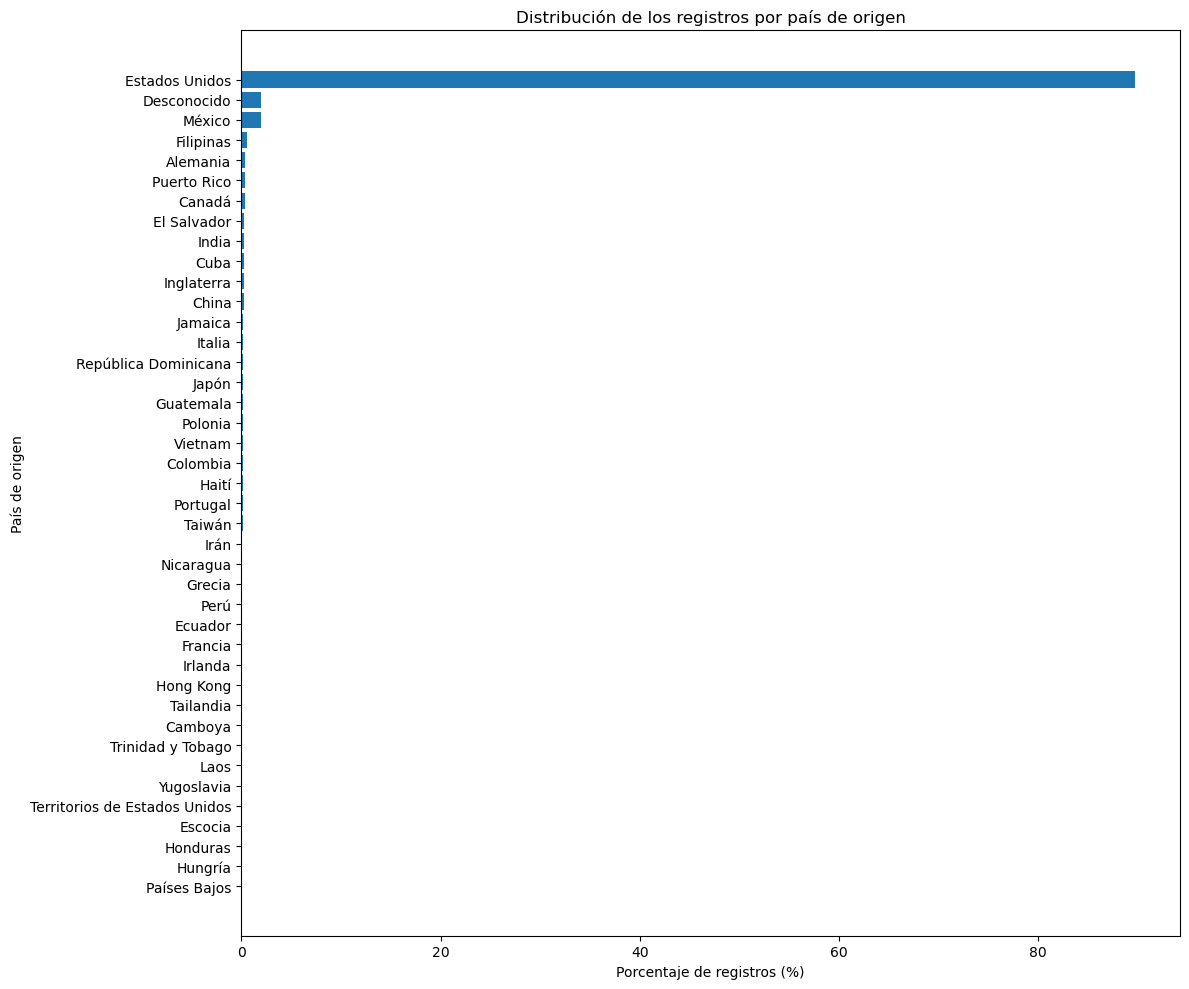

In [35]:
import matplotlib.pyplot as plt

# Calcular porcentajes por país
total = df04.count()

paisesGrafico = (
    df04.groupBy("PaisOrigen")
    .count()
    .withColumn("Porcentaje", F.round(F.col("count") / total * 100, 2))
    .orderBy(F.desc("count"))
    .toPandas()
)

# Gráfico de barras horizontales
plt.figure(figsize=(12, 10))
plt.barh(paisesGrafico["PaisOrigen"], paisesGrafico["Porcentaje"])

plt.xlabel("Porcentaje de registros (%)")
plt.ylabel("País de origen")
plt.title("Distribución de los registros por país de origen")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##### **4.4.3. Horas trabajadas a la semana**

Se revisaron los valores de la variable HorasSemana, encontrando registros entre 1 y 99 horas semanales. Todos los valores se encuentran dentro del rango válido de 0 a 168 horas que tiene una semana, por lo que no se identificaron valores imposibles. En consecuencia, no es necesario realizar modificaciones en esta variable.


In [36]:
df04.groupBy("HorasSemana").count().orderBy("HorasSemana").show(200)

+-----------+-----+
|HorasSemana|count|
+-----------+-----+
|        1.0|   27|
|        2.0|   53|
|        3.0|   59|
|        4.0|   84|
|        5.0|   95|
|        6.0|   92|
|        7.0|   45|
|        8.0|  218|
|        9.0|   27|
|       10.0|  425|
|       11.0|   20|
|       12.0|  247|
|       13.0|   28|
|       14.0|   55|
|       15.0|  623|
|       16.0|  303|
|       17.0|   42|
|       18.0|  129|
|       19.0|   19|
|       20.0| 1862|
|       21.0|   46|
|       22.0|   62|
|       23.0|   40|
|       24.0|  354|
|       25.0|  958|
|       26.0|   40|
|       27.0|   43|
|       28.0|  140|
|       29.0|   15|
|       30.0| 1700|
|       31.0|   12|
|       32.0|  423|
|       33.0|   61|
|       34.0|   48|
|       35.0| 1937|
|       36.0|  336|
|       37.0|  242|
|       38.0|  714|
|       39.0|   63|
|       40.0|22803|
|       41.0|   59|
|       42.0|  338|
|       43.0|  227|
|       44.0|  310|
|       45.0| 2717|
|       46.0|  129|
|       47.0|   82|


##### **4.4.4. PerdidaCapital**
Se revisó la variable PerdidaCapital, identificando 99 valores diferentes, con un mínimo de 0 y un máximo de 4356. No se encontraron valores negativos y el rango observado es coherente con la naturaleza de la variable. Por lo tanto, no se identificaron inconsistencias evidentes y se decide conservar la variable sin modificaciones

In [37]:
df04.select(
    F.countDistinct("PerdidaCapital").alias("ValoresDiferentes"),
    F.min("PerdidaCapital").alias("Minimo"),
    F.max("PerdidaCapital").alias("Maximo")
).show()

+-----------------+------+------+
|ValoresDiferentes|Minimo|Maximo|
+-----------------+------+------+
|               99|   0.0|4356.0|
+-----------------+------+------+



##### **4.4.5. GananciaCapital**
Se revisó la variable GananciaCapital, identificando 123 valores diferentes, con un mínimo de 0 y un máximo de 99999. No se encontraron valores negativos y el rango observado es coherente con la naturaleza de la variable. Por lo tanto, no se identificaron inconsistencias evidentes y se decide conservar la variable sin modificaciones

In [38]:
df04.select(
    F.countDistinct("GananciaCapital").alias("ValoresDiferentes"),
    F.min("GananciaCapital").alias("Minimo"),
    F.max("GananciaCapital").alias("Maximo")
).show()

+-----------------+------+-------+
|ValoresDiferentes|Minimo| Maximo|
+-----------------+------+-------+
|              123|   0.0|99999.0|
+-----------------+------+-------+



##### **4.4.6. Sexo**
Se revisaron las categorías de la variable Sexo y no se identificaron inconsistencias. Se tradujeron las categorías Male y Female a Hombre y Mujer

In [39]:
df04.groupBy("Sexo").count().show()

+-------+-----+
|   Sexo|count|
+-------+-----+
|   Male|32650|
| Female|16192|
+-------+-----+



In [40]:
df05 = df04.withColumn("Sexo", F.trim(F.col("Sexo")))

df05 = df05.replace(
    {"Male": "Hombre", "Female": "Mujer"},
    subset=["Sexo"]
)

df05.groupBy("Sexo").count().show()

+------+-----+
|  Sexo|count|
+------+-----+
|Hombre|32650|
| Mujer|16192|
+------+-----+



##### **4.4.7. Raza**
Se revisaron las cinco categorías de la variable Raza y no se identificaron inconsistencias. Se eliminaron los espacios innecesarios y se tradujeron las categorías al español

In [41]:
df05.groupBy("Raza").count().orderBy(F.desc("count")).show()

+-------------------+-----+
|               Raza|count|
+-------------------+-----+
|              White|41762|
|              Black| 4685|
| Asian-Pac-Islander| 1519|
| Amer-Indian-Eskimo|  470|
|              Other|  406|
+-------------------+-----+



In [42]:
df06 = df05.withColumn("Raza", F.trim(F.col("Raza")))

df06 = df06.replace({
    "White": "Blanco",
    "Black": "Negro",
    "Asian-Pac-Islander": "Asiático o isleño del Pacífico",
    "Amer-Indian-Eskimo": "Indígena americano o esquimal",
    "Other": "Otro"
}, subset=["Raza"])

df06.groupBy("Raza").count().show()

+--------------------+-----+
|                Raza|count|
+--------------------+-----+
|                Otro|  406|
|              Blanco|41762|
|               Negro| 4685|
|Asiático o isleño...| 1519|
|Indígena american...|  470|
+--------------------+-----+



##### **4.4.8. Relacion**

Se revisaron las seis categorías de la variable Relacion y no se identificaron inconsistencias. Se tradujeron las categorías al español 

Es importante aclarar que esta variable representa la relación de la persona con una figura de referencia dentro del hogar, y no todas sus relaciones familiares. Por ejemplo, una persona puede ser simultáneamente esposo, hijo y padre, pero en el censo se clasifica según su posición dentro del hogar registrado.

Por esta razón, la variable no debe confundirse con EstadoCivil, ya que ambas representan aspectos diferentes. Mientras EstadoCivil describe la situación conyugal de la persona, Relacion refleja su posición familiar dentro del hogar.


In [43]:
df06.groupBy("Relacion").count().orderBy(F.desc("count")).show()


+---------------+-----+
|       Relacion|count|
+---------------+-----+
|        Husband|19716|
|  Not-in-family|12583|
|      Own-child| 7581|
|      Unmarried| 5125|
|           Wife| 2331|
| Other-relative| 1506|
+---------------+-----+



In [44]:
df07 = df06.withColumn("Relacion", F.trim(F.col("Relacion")))

df07 = df07.replace({
    "Husband": "Esposo",
    "Not-in-family": "No pertenece al núcleo familiar",
    "Own-child": "Hijo",
    "Unmarried": "Sin pareja",
    "Wife": "Esposa",
    "Other-relative": "Otro familiar"
}, subset=["Relacion"])

df07.groupBy("Relacion").count().show()

+--------------------+-----+
|            Relacion|count|
+--------------------+-----+
|                Hijo| 7581|
|No pertenece al n...|12583|
|       Otro familiar| 1506|
|              Esposo|19716|
|              Esposa| 2331|
|          Sin pareja| 5125|
+--------------------+-----+



##### **4.4.9. Ocupación**
Se revisaron las 15 categorías de la variable Ocupacion y se tradujeron sus nombres al español

Se identificaron 2809 registros con el valor ?, equivalentes aproximadamente al 5,75 % del conjunto de datos. Estos registros se clasificaron como Desconocido, ya que no es posible determinar su ocupación.



In [45]:
df07.groupBy("Ocupacion").count().orderBy(F.desc("count")).show(50, truncate=False)

+------------------+-----+
|Ocupacion         |count|
+------------------+-----+
| Prof-specialty   |6172 |
| Craft-repair     |6112 |
| Exec-managerial  |6086 |
| Adm-clerical     |5611 |
| Sales            |5504 |
| Other-service    |4923 |
| Machine-op-inspct|3022 |
| ?                |2809 |
| Transport-moving |2355 |
| Handlers-cleaners|2072 |
| Farming-fishing  |1490 |
| Tech-support     |1446 |
| Protective-serv  |983  |
| Priv-house-serv  |242  |
| Armed-Forces     |15   |
+------------------+-----+



In [46]:
df08 = df07.withColumn("Ocupacion", F.trim(F.col("Ocupacion")))

df08 = df08.replace({
    "Prof-specialty": "Profesionales especializados",
    "Craft-repair": "Oficios y reparaciones",
    "Exec-managerial": "Directivos y gerentes",
    "Adm-clerical": "Administrativos y oficinistas",
    "Sales": "Ventas",
    "Other-service": "Otros servicios",
    "Machine-op-inspct": "Operadores de maquinaria e inspectores",
    "?": "Desconocido",
    "Transport-moving": "Transporte y movilización",
    "Handlers-cleaners": "Manipuladores y personal de limpieza",
    "Farming-fishing": "Agricultura y pesca",
    "Tech-support": "Soporte técnico",
    "Protective-serv": "Servicios de protección",
    "Priv-house-serv": "Servicio doméstico",
    "Armed-Forces": "Fuerzas Armadas"
}, subset=["Ocupacion"])

df08.groupBy("Ocupacion").count().orderBy(F.desc("count")).show(50, truncate=False)

+--------------------------------------+-----+
|Ocupacion                             |count|
+--------------------------------------+-----+
|Profesionales especializados          |6172 |
|Oficios y reparaciones                |6112 |
|Directivos y gerentes                 |6086 |
|Administrativos y oficinistas         |5611 |
|Ventas                                |5504 |
|Otros servicios                       |4923 |
|Operadores de maquinaria e inspectores|3022 |
|Desconocido                           |2809 |
|Transporte y movilización             |2355 |
|Manipuladores y personal de limpieza  |2072 |
|Agricultura y pesca                   |1490 |
|Soporte técnico                       |1446 |
|Servicios de protección               |983  |
|Servicio doméstico                    |242  |
|Fuerzas Armadas                       |15   |
+--------------------------------------+-----+



##### **4.4.10. Estado Civil**
Se revisaron las siete categorías de la variable EstadoCivil y no se identificaron valores desconocidos ni inconsistencias evidentes. Se tradujeron las categorías al español.



In [47]:
df08.groupBy("EstadoCivil").count().orderBy(F.desc("count")).show(50, truncate=False)

+----------------------+-----+
|EstadoCivil           |count|
+----------------------+-----+
| Married-civ-spouse   |22379|
| Never-married        |16117|
| Divorced             |6633 |
| Separated            |1530 |
| Widowed              |1518 |
| Married-spouse-absent|628  |
| Married-AF-spouse    |37   |
+----------------------+-----+



In [48]:
df09 = df08.withColumn("EstadoCivil", F.trim(F.col("EstadoCivil")))

df09 = df09.replace({
    "Married-civ-spouse": "Casado con cónyuge civil",
    "Never-married": "Nunca casado",
    "Divorced": "Divorciado",
    "Separated": "Separado",
    "Widowed": "Viudo",
    "Married-spouse-absent": "Casado con cónyuge ausente",
    "Married-AF-spouse": "Casado con cónyuge militar"
}, subset=["EstadoCivil"])

df09.groupBy("EstadoCivil").count().orderBy(F.desc("count")).show(50, truncate=False)

+--------------------------+-----+
|EstadoCivil               |count|
+--------------------------+-----+
|Casado con cónyuge civil  |22379|
|Nunca casado              |16117|
|Divorciado                |6633 |
|Separado                  |1530 |
|Viudo                     |1518 |
|Casado con cónyuge ausente|628  |
|Casado con cónyuge militar|37   |
+--------------------------+-----+



##### **4.4.11. PesoCensal**
La variable PesoCensal indica cuántas personas de la población representa aproximadamente cada registro. Se identificaron 28.523 valores diferentes, entre 12.285 y 1.490.400, sin valores negativos ni iguales a cero.

Se conservará esta variable como factor de ponderación y no como predictora de ingresos. Esto permitirá que los registros con mayor representatividad poblacional tengan mayor influencia durante el entrenamiento, sin necesidad de duplicarlos.

Posteriormente, se compararán modelos con y sin ponderación para evaluar su efecto en el desempeño predictivo.


In [49]:
df09.select(
    F.countDistinct("PesoCensal").alias("ValoresDiferentes"),
    F.min("PesoCensal").alias("Minimo"),
    F.max("PesoCensal").alias("Maximo"),
    F.sum(F.when(F.col("PesoCensal") <= 0, 1).otherwise(0)).alias("ValoresNoPositivos")
).show()

+-----------------+-------+---------+------------------+
|ValoresDiferentes| Minimo|   Maximo|ValoresNoPositivos|
+-----------------+-------+---------+------------------+
|            28523|12285.0|1490400.0|                 0|
+-----------------+-------+---------+------------------+



##### **4.4.12. TipoTrabajo**

Se revisaron las nueve categorías de TipoTrabajo y se tradujeron al español

Se identificaron 2.799 registros con el valor ?, equivalentes al 5,73 % del conjunto de datos, los cuales se clasificaron como Desconocido.


In [50]:
df09.groupBy("TipoTrabajo").count().orderBy(F.desc("count")).show(50, truncate=False)

+-----------------+-----+
|TipoTrabajo      |count|
+-----------------+-----+
| Private         |33906|
| Self-emp-not-inc|3862 |
| Local-gov       |3136 |
| ?               |2799 |
| State-gov       |1981 |
| Self-emp-inc    |1695 |
| Federal-gov     |1432 |
| Without-pay     |21   |
| Never-worked    |10   |
+-----------------+-----+



In [51]:
df10 = df09.withColumn("TipoTrabajo", F.trim(F.col("TipoTrabajo")))

df10 = df10.replace({
    "Private": "Sector privado",
    "Self-emp-not-inc": "Independiente no constituido",
    "Local-gov": "Gobierno local",
    "?": "Desconocido",
    "State-gov": "Gobierno estatal",
    "Self-emp-inc": "Independiente constituido",
    "Federal-gov": "Gobierno federal",
    "Without-pay": "Sin remuneración",
    "Never-worked": "Nunca ha trabajado"
}, subset=["TipoTrabajo"])

df10.groupBy("TipoTrabajo").count().orderBy(F.desc("count")).show(50, truncate=False)

+----------------------------+-----+
|TipoTrabajo                 |count|
+----------------------------+-----+
|Sector privado              |33906|
|Independiente no constituido|3862 |
|Gobierno local              |3136 |
|Desconocido                 |2799 |
|Gobierno estatal            |1981 |
|Independiente constituido   |1695 |
|Gobierno federal            |1432 |
|Sin remuneración            |21   |
|Nunca ha trabajado          |10   |
+----------------------------+-----+



##### **4.4.13. Edad**

Se revisó la variable Edad, identificando 74 valores diferentes, con un mínimo de 17 años y un máximo de 90 años. No se encontraron edades negativas, iguales a cero ni valores fuera de un rango humanamente posible. Por lo tanto, no se identificaron inconsistencias y se conserva la variable sin modificaciones.


In [52]:
df10.select(
    F.countDistinct("Edad").alias("ValoresDiferentes"),
    F.min("Edad").alias("Minimo"),
    F.max("Edad").alias("Maximo"),
    F.sum(F.when(F.col("Edad") <= 0, 1).otherwise(0)).alias("ValoresInvalidos")
).show()

+-----------------+------+------+----------------+
|ValoresDiferentes|Minimo|Maximo|ValoresInvalidos|
+-----------------+------+------+----------------+
|               74|    17|    90|               0|
+-----------------+------+------+----------------+



#### **4.5 Revision de nulos**


In [53]:
# Se crea una tabla para la identificación de datos nulos
df10Aux = df10[
    'Edad',
    'TipoTrabajo',
    'PesoCensal',
    'NivelEducativo',
    'EstadoCivil',
    'Ocupacion',
    'Relacion',
    'Raza',
    'Sexo',
    'GananciaCapital',
    'PerdidaCapital',
    'HorasSemana',
    'PaisOrigen',
    'Ingresos'
]

df10Aux.select([
    F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c)
    for c in df10Aux.columns
]).show()

+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|Edad|TipoTrabajo|PesoCensal|NivelEducativo|EstadoCivil|Ocupacion|Relacion|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingresos|
+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|   0|          0|         0|             0|          0|        0|       0|   0|   0|              0|             0|          0|         0|       0|
+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+



##### **4.5.1. Tratamiento de valores desconocidos**

Se identificaron 2.799 registros con valores desconocidos en TipoTrabajo, 2.809 en Ocupacion y 972 en PaisOrigen. Después de analizar su comportamiento y las relaciones con otras variables, se decidió conservar la categoría "Desconocido" en lugar de realizar imputaciones.

Esta decisión considera que, en la realidad, existen grupos poblacionales cuyas condiciones laborales o de nacionalidad no siempre pueden clasificarse dentro de las categorías establecidas. Por ejemplo, algunas personas pueden desempeñar actividades económicas informales, mientras que otras pueden carecer de documentación que permita identificar su nacionalidad o país de origen. Aunque no es posible confirmar que estas sean las causas de los valores desconocidos en el conjunto de datos, representan situaciones reales que justifican no asignar categorías sin evidencia suficiente.

Adicionalmente, el análisis exploratorio no proporcionó indicios suficientemente sólidos para realizar una imputación confiable. Se encontró que los 2.799 registros con TipoTrabajo desconocido también presentan Ocupacion desconocida, lo que dificulta recuperar esta información mediante relaciones entre ambas variables. Asimismo, las características de edad, horas trabajadas e ingresos no permitieron identificar una categoría laboral específica a la cual asignar estos registros.

Por lo tanto, se conservaron todos los registros y se mantuvo "Desconocido" como una categoría independiente. Esta decisión evita introducir información artificial, respeta la diversidad de situaciones que pueden existir en la población y permite que los modelos posteriores evalúen si la ausencia de información tiene valor predictivo.

In [54]:
# Se cuenta la cantidad de valores desconocidos por variable
df10Aux.select([
    F.sum(
        F.when(F.trim(F.col(c).cast("string")).isin("Desconocido", "?"), 1).otherwise(0)
    ).alias(c)
    for c in df10Aux.columns
]).show()

+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|Edad|TipoTrabajo|PesoCensal|NivelEducativo|EstadoCivil|Ocupacion|Relacion|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingresos|
+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|   0|       2799|         0|             0|          0|     2809|       0|   0|   0|              0|             0|          0|       972|       0|
+----+-----------+----------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+



In [55]:
df10.filter(
    (F.col("TipoTrabajo") == "Desconocido") &
    (F.col("Ocupacion") == "Desconocido")
).count()

2799

In [56]:
df10.groupBy(
    F.col("TipoTrabajo") == "Desconocido"
).agg(
    F.round(F.avg("Edad"), 2).alias("EdadPromedio"),
    F.min("Edad").alias("EdadMinima"),
    F.max("Edad").alias("EdadMaxima"),
    F.round(F.avg("HorasSemana"), 2).alias("HorasPromedio")
).show()

+---------------------------+------------+----------+----------+-------------+
|(TipoTrabajo = Desconocido)|EdadPromedio|EdadMinima|EdadMaxima|HorasPromedio|
+---------------------------+------------+----------+----------+-------------+
|                       true|       40.14|        17|        90|        31.81|
|                      false|       38.55|        17|        90|        40.95|
+---------------------------+------------+----------+----------+-------------+



In [57]:
df10.groupBy("TipoTrabajo", "Ingresos").count().filter(
    F.col("TipoTrabajo") == "Desconocido"
).show()

+-----------+--------+-----+
|TipoTrabajo|Ingresos|count|
+-----------+--------+-----+
|Desconocido|       1|  265|
|Desconocido|       0| 2534|
+-----------+--------+-----+



In [58]:
df10.groupBy(
    (F.col("TipoTrabajo") == "Desconocido").alias("TrabajoDesconocido")
).agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).show()

+------------------+-----+-----------------------+
|TrabajoDesconocido|Total|PorcentajeIngresosAltos|
+------------------+-----+-----------------------+
|              true| 2799|                   9.47|
|             false|46043|                  24.81|
+------------------+-----+-----------------------+



In [59]:
df10.groupBy(
    (F.col("TipoTrabajo") == "Desconocido").alias("TrabajoDesconocido")
).agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).show()

+------------------+-----+-----------------------+
|TrabajoDesconocido|Total|PorcentajeIngresosAltos|
+------------------+-----+-----------------------+
|              true| 2799|                   9.47|
|             false|46043|                  24.81|
+------------------+-----+-----------------------+



In [60]:
df10.filter(
    F.col("TipoTrabajo") == "Desconocido"
).groupBy("HorasSemana").count().orderBy("HorasSemana").show(200)

+-----------+-----+
|HorasSemana|count|
+-----------+-----+
|        1.0|   14|
|        2.0|   29|
|        3.0|   24|
|        4.0|   35|
|        5.0|   34|
|        6.0|   33|
|        7.0|   11|
|        8.0|   64|
|        9.0|    3|
|       10.0|   82|
|       11.0|    4|
|       12.0|   40|
|       13.0|    4|
|       14.0|   14|
|       15.0|   99|
|       16.0|   46|
|       17.0|    2|
|       18.0|   16|
|       20.0|  238|
|       21.0|    4|
|       22.0|    6|
|       23.0|    6|
|       24.0|   44|
|       25.0|  126|
|       26.0|    1|
|       27.0|    3|
|       28.0|   15|
|       29.0|    2|
|       30.0|  204|
|       32.0|   49|
|       33.0|    1|
|       34.0|    1|
|       35.0|  135|
|       36.0|   22|
|       37.0|    5|
|       38.0|   22|
|       39.0|    1|
|       40.0| 1033|
|       41.0|    3|
|       42.0|    9|
|       43.0|    6|
|       44.0|    5|
|       45.0|   65|
|       46.0|    1|
|       48.0|   22|
|       49.0|    2|
|       50.0|   81|


In [61]:
df10.filter(
    (F.col("Ocupacion") == "Desconocido") &
    (F.col("TipoTrabajo") != "Desconocido")
).groupBy("TipoTrabajo").count().show()

+------------------+-----+
|       TipoTrabajo|count|
+------------------+-----+
|Nunca ha trabajado|   10|
+------------------+-----+



In [62]:
df10.filter(
    F.col("TipoTrabajo") == "Nunca ha trabajado"
).select("Edad", "HorasSemana", "Ocupacion", "Ingresos").show(20)

+----+-----------+-----------+--------+
|Edad|HorasSemana|  Ocupacion|Ingresos|
+----+-----------+-----------+--------+
|  18|       40.0|Desconocido|       0|
|  23|       35.0|Desconocido|       0|
|  17|       30.0|Desconocido|       0|
|  18|       10.0|Desconocido|       0|
|  20|       40.0|Desconocido|       0|
|  30|       40.0|Desconocido|       0|
|  18|        4.0|Desconocido|       0|
|  17|       20.0|Desconocido|       0|
|  20|       35.0|Desconocido|       0|
|  18|       35.0|Desconocido|       0|
+----+-----------+-----------+--------+



In [63]:
df10.filter(
    F.col("TipoTrabajo") == "Nunca ha trabajado"
).select(
    "Edad", "NivelEducativo", "EstadoCivil",
    "Relacion", "HorasSemana", "Ingresos"
).show(20, truncate=False)

+----+--------------+--------------------------+-------------------------------+-----------+--------+
|Edad|NivelEducativo|EstadoCivil               |Relacion                       |HorasSemana|Ingresos|
+----+--------------+--------------------------+-------------------------------+-----------+--------+
|18  |6             |Nunca casado              |Hijo                           |40.0       |0       |
|23  |4             |Divorciado                |No pertenece al núcleo familiar|35.0       |0       |
|17  |6             |Nunca casado              |Hijo                           |30.0       |0       |
|18  |7             |Nunca casado              |Hijo                           |10.0       |0       |
|20  |10            |Nunca casado              |Hijo                           |40.0       |0       |
|30  |9             |Casado con cónyuge civil  |Esposa                         |40.0       |0       |
|18  |10            |Nunca casado              |Hijo                           |4.

In [64]:
df10.filter(
    F.col("TipoTrabajo") != "Desconocido"
).groupBy("TipoTrabajo").count().orderBy(
    F.desc("count")
).show(truncate=False)

+----------------------------+-----+
|TipoTrabajo                 |count|
+----------------------------+-----+
|Sector privado              |33906|
|Independiente no constituido|3862 |
|Gobierno local              |3136 |
|Gobierno estatal            |1981 |
|Independiente constituido   |1695 |
|Gobierno federal            |1432 |
|Sin remuneración            |21   |
|Nunca ha trabajado          |10   |
+----------------------------+-----+



In [65]:
df10.filter(
    F.col("TipoTrabajo") != "Desconocido"
).groupBy("TipoTrabajo").agg(
    F.count("*").alias("Total"),
    F.round(F.avg("HorasSemana"), 2).alias("HorasPromedio"),
    F.round(F.avg("Edad"), 2).alias("EdadPromedio"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)


+----------------------------+-----+-------------+------------+-----------------------+
|TipoTrabajo                 |Total|HorasPromedio|EdadPromedio|PorcentajeIngresosAltos|
+----------------------------+-----+-------------+------------+-----------------------+
|Sector privado              |33906|40.27        |36.9        |21.79                  |
|Independiente no constituido|3862 |44.4         |45.33       |27.89                  |
|Gobierno local              |3136 |40.85        |41.68       |29.56                  |
|Gobierno estatal            |1981 |39.09        |39.51       |26.75                  |
|Independiente constituido   |1695 |48.57        |45.8        |55.34                  |
|Gobierno federal            |1432 |41.51        |42.58       |39.18                  |
|Sin remuneración            |21   |33.95        |47.29       |9.52                   |
|Nunca ha trabajado          |10   |28.9         |19.9        |0.0                    |
+----------------------------+--

### **5. Análisis Exploratorio de Datos**

#### **5.1. Estadísticas descriptivas de las variables numéricas**
**Edad:** La población presenta una edad promedio de 38,64 años, con una desviación estándar de 13,71. El rango entre 17 y 90 años evidencia una amplia diversidad generacional, que podría reflejar diferencias en experiencia laboral, estabilidad económica y capacidad de generar ingresos.

**PesoCensal:** Presenta un promedio de 189.664,13 y un máximo de 1.490.400. Esta variable representa el peso estadístico de cada observación dentro de la población censal, no una característica personal. Por ello, se considerará para posibles análisis ponderados, pero no como predictor directo de los ingresos.

**NivelEducativo:** Tiene un promedio de 10,08 y valores entre 1 y 16. Aunque se encuentra codificada numéricamente, representa niveles educativos ordenados. Se espera que tenga una relación importante con los ingresos, dado que la formación académica puede influir en las oportunidades laborales y salariales.

**GananciaCapital:** Presenta un promedio de 1.079,07, una desviación estándar de 7.452,02 y un máximo de 99.999. La elevada dispersión sugiere una distribución asimétrica, posiblemente con numerosos registros en cero y pocos individuos con ganancias elevadas. Esto podría reflejar diferencias importantes en los ingresos provenientes de inversiones o activos.

**PerdidaCapital:** Registra un promedio de 87,50, una desviación estándar de 403,00 y un máximo de 4.356. Al igual que GananciaCapital, presenta una dispersión considerable respecto a su media, lo que sugiere que las pérdidas de capital no se distribuyen uniformemente entre la población.

**HorasSemana:** El promedio es de 40,42 horas, cercano a una jornada laboral convencional de tiempo completo. Sin embargo, existen registros desde 1 hasta 99 horas semanales. El máximo equivale a 14,14 horas diarias trabajando los siete días de la semana, o 19,8 horas diarias durante cinco días. Aunque es una jornada excepcionalmente extensa, no necesariamente representa un error y podría relacionarse con múltiples empleos o condiciones laborales particulares.

En conjunto, los resultados muestran una población heterogénea en edad, educación y dedicación laboral. Las variables económicas presentan indicios de distribuciones asimétricas y posibles valores extremos. Por lo tanto, será necesario complementar este análisis con histogramas y diagramas de caja para comprender mejor sus distribuciones antes de decidir si requieren algún tratamiento.

In [66]:
variablesNumericas = [
    "Edad",
    "PesoCensal",
    "NivelEducativo",
    "GananciaCapital",
    "PerdidaCapital",
    "HorasSemana"
]

df10.select(variablesNumericas).describe().show(truncate=False)

26/11/24 21:29:16 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+------------------+-----------------+------------------+
|summary|Edad              |PesoCensal        |NivelEducativo    |GananciaCapital   |PerdidaCapital   |HorasSemana       |
+-------+------------------+------------------+------------------+------------------+-----------------+------------------+
|count  |48842             |48842             |48842             |48842             |48842            |48842             |
|mean   |38.64358543876172 |189664.13459727284|10.078088530363212|1079.0676262233324|87.50231358257237|40.422382375824085|
|stddev |13.710509934443563|105604.02542315733|2.570972755592263 |7452.019057655401 |403.0045521243599|12.3914440242523  |
|min    |17                |12285.0           |1                 |0.0               |0.0              |1.0               |
|max    |90                |1490400.0         |16                |99999.0           |4356.0           |99.0              |
+-------+-------

#### **5.2. Distribución de las variables numéricas**
**Edad:** La distribución presenta asimetría positiva, con una mayor concentración de personas entre los 20 y 50 años. A medida que aumenta la edad, disminuye la frecuencia de registros, especialmente después de los 60 años.

**NivelEducativo:** Se observan concentraciones importantes en los niveles 9, 10 y 13. La distribución no es uniforme, lo que indica que determinados niveles educativos predominan en la población. Al tratarse de una variable ordinal, sus barras representan categorías y no una distribución continua.

**GananciaCapital:** Presenta una distribución extremadamente asimétrica hacia la derecha. La gran mayoría de los registros se concentra en cero, mientras que unos pocos presentan ganancias elevadas, alcanzando hasta 99.999. Estos valores podrían influir considerablemente en los modelos predictivos.

**PerdidaCapital:** Su comportamiento es similar al de GananciaCapital, con una concentración predominante en cero y pocos registros con pérdidas positivas. Esto sugiere que las pérdidas de capital son poco frecuentes dentro de la población analizada.

**HorasSemana:** Existe una concentración muy marcada alrededor de las 40 horas semanales, correspondiente a una jornada laboral habitual de tiempo completo. También se observan personas con jornadas reducidas y otras que superan las 60 horas semanales. Los valores cercanos a 99 horas son poco frecuentes

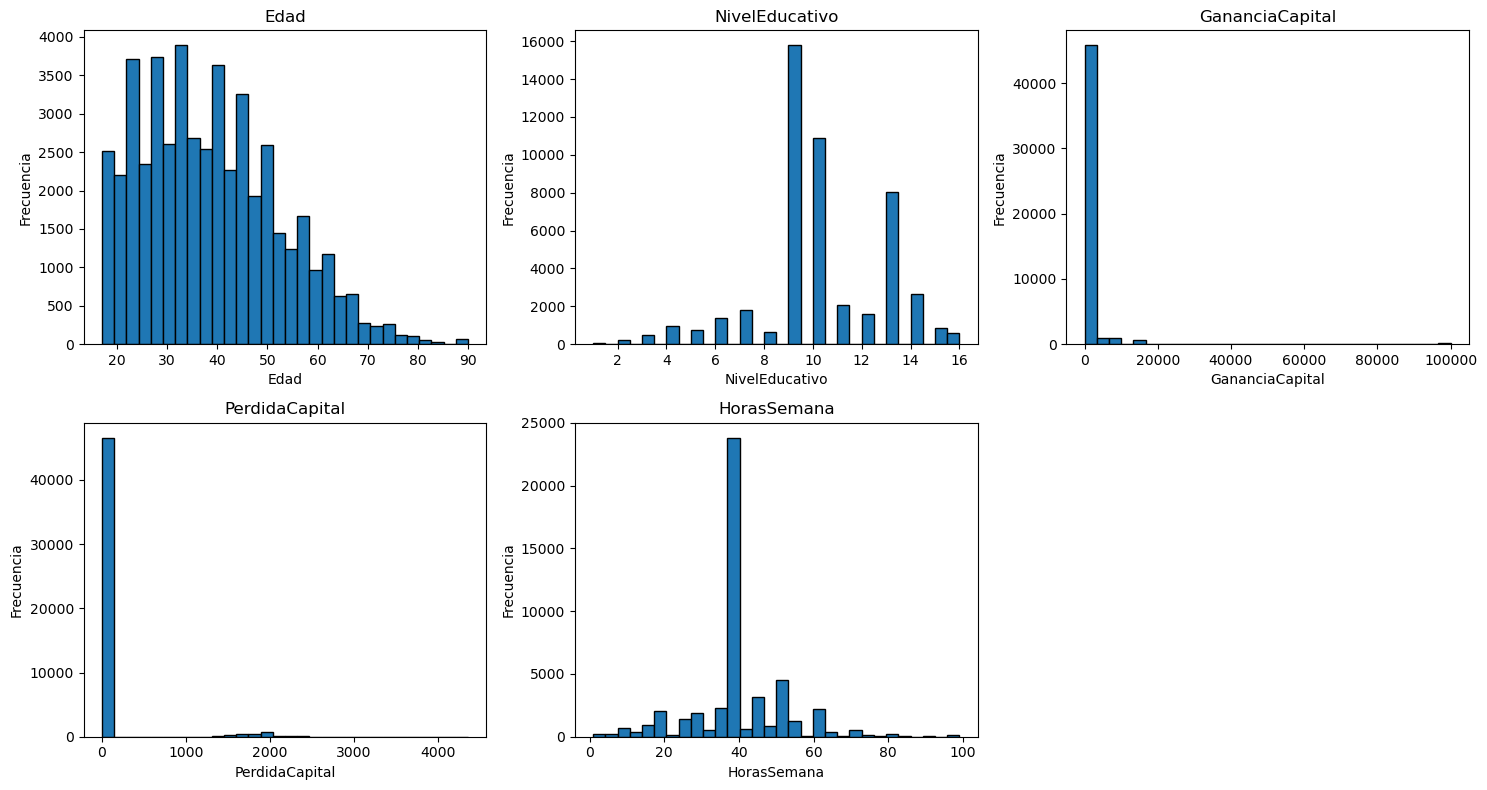

In [67]:
import matplotlib.pyplot as plt

variables = [
    "Edad", "NivelEducativo", "GananciaCapital",
    "PerdidaCapital", "HorasSemana"
]

datos = df10.select(variables).toPandas()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, variable in zip(axes.flat, variables):
    ax.hist(datos[variable], bins=30, edgecolor="black")
    ax.set_title(variable)
    ax.set_xlabel(variable)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(variables):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### **5.3. Análisis de valores atípicos**

**Edad:** La mediana se encuentra alrededor de los 37 años y se identifican valores atípicos a partir de aproximadamente 78 años. 

**NivelEducativo:** La mediana es 10 y se identifican valores atípicos en los niveles educativos más bajos, entre 1 y 4. Sin embargo, estos valores corresponden a niveles válidos de educación. 

**GananciaCapital:** Presenta numerosos valores atípicos positivos, destacándose el máximo de 99.999. La concentración de observaciones en cero provoca que prácticamente cualquier ganancia positiva se identifique como atípica. 

**PerdidaCapital:** Presenta un comportamiento similar, con una gran concentración en cero y valores positivos que alcanzan 4.356. Los valores atípicos pueden representar pérdidas económicas reales

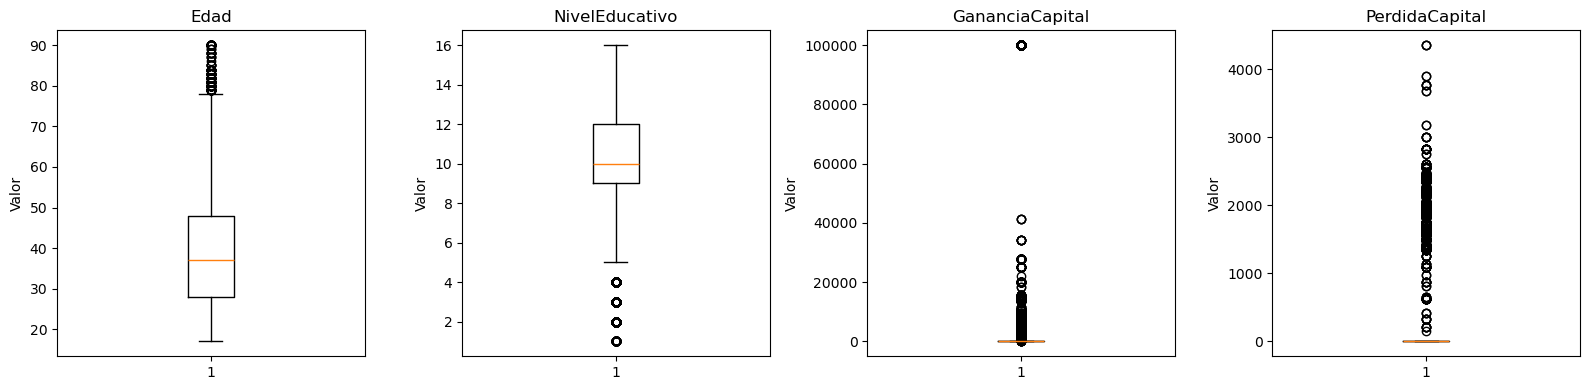

In [68]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

variables = [
    "Edad", "NivelEducativo", "GananciaCapital",
    "PerdidaCapital", "HorasSemana"
]

for ax, variable in zip(axes, variables):
    ax.boxplot(datos[variable])
    ax.set_title(variable)
    ax.set_ylabel("Valor")

plt.tight_layout()
plt.show()

#### **5.4. Relación entre las variables numéricas y los ingresos**

**Edad:** Las personas con ingresos superiores a 50K presentan una mediana cercana a los 43 años, mientras que en el grupo de ingresos bajos es aproximadamente 34 años. Esto sugiere que una mayor edad, posiblemente relacionada con la experiencia laboral, está asociada con ingresos más elevados.

**NivelEducativo:** Se observa una diferencia importante entre ambos grupos. Las personas con ingresos bajos presentan una mediana de 9, mientras que aquellas con ingresos altos alcanzan una mediana de 12. Esto sugiere una asociación positiva entre el nivel educativo y los ingresos.

**GananciaCapital:** Ambos grupos presentan una fuerte concentración en cero. Sin embargo, en el grupo de ingresos altos se observan valores extremos que alcanzan 99.999. Esto sugiere que las ganancias de capital podrían aportar información para distinguir los niveles de ingresos, aunque los diagramas de caja no permiten establecer claramente su magnitud.

**PerdidaCapital:** La mayoría de las personas presenta valores iguales a cero, independientemente de sus ingresos. Se identifican valores extremos en ambos grupos, por lo que su relación con los ingresos no resulta evidente únicamente mediante esta visualización.

**HorasSemana:** Las personas con ingresos bajos presentan una mediana cercana a 40 horas semanales, mientras que en el grupo de ingresos altos se aproxima a 45 horas. Además, este último grupo presenta una mayor concentración de jornadas entre 40 y 50 horas, lo que sugiere una asociación entre la dedicación laboral y los ingresos.

En general, Edad, NivelEducativo y HorasSemana muestran diferencias visibles entre los grupos, por lo que podrían ser variables relevantes para la clasificación de ingresos. Las variables de capital requieren un análisis adicional debido a su elevada concentración en cero.

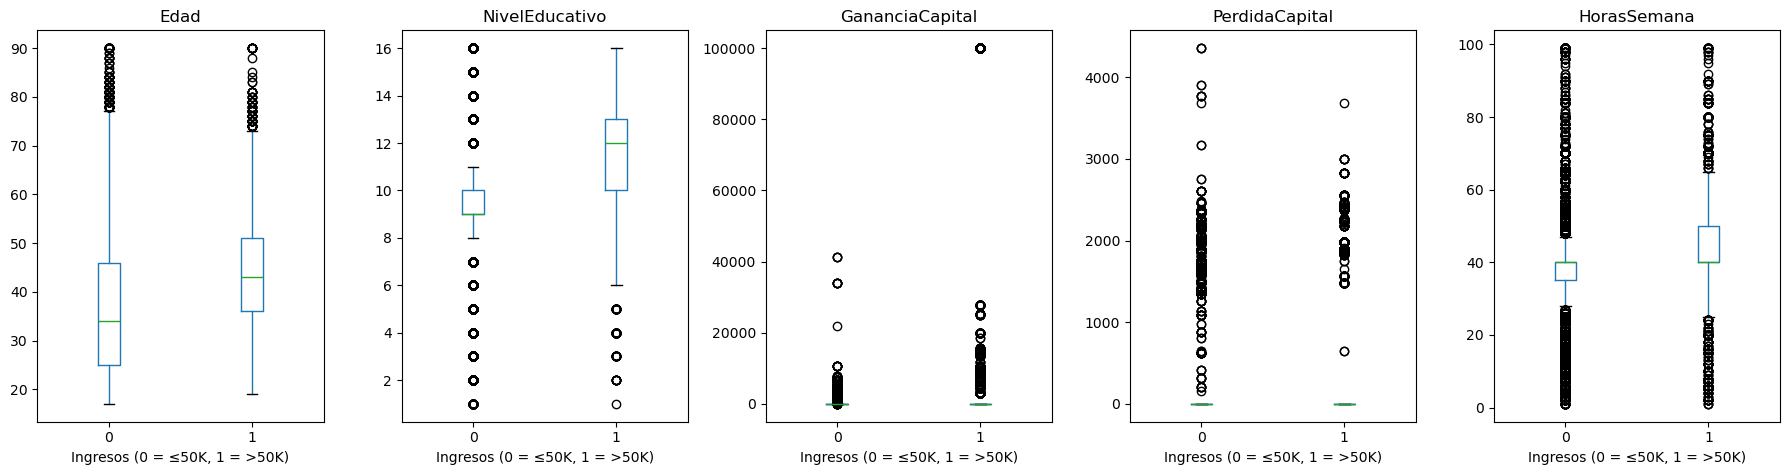

In [69]:
import matplotlib.pyplot as plt

variables = [
    "Edad", "NivelEducativo", "GananciaCapital",
    "PerdidaCapital", "HorasSemana"
]

datosIngresos = df10.select(variables + ["Ingresos"]).toPandas()

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, variable in zip(axes, variables):
    datosIngresos.boxplot(
        column=variable,
        by="Ingresos",
        ax=ax,
        grid=False
    )
    ax.set_title(variable)
    ax.set_xlabel("Ingresos (0 = ≤50K, 1 = >50K)")

plt.suptitle("")
plt.tight_layout()
plt.show()

#### **5.5. Comparación de medias y medianas según los ingresos**

Se calcularon las medias y medianas de las variables numéricas para identificar diferencias entre los grupos de ingresos.

**Edad:** Las personas con ingresos altos tienen una edad promedio de 44,28 años, frente a 36,87 años en el grupo de ingresos bajos. La diferencia de 7,41 años refuerza la posible relación entre experiencia laboral e ingresos.

**NivelEducativo:** El grupo de ingresos altos presenta una media de 11,6 y una mediana de 12, mientras que el grupo de ingresos bajos registra 9,6 y 9, respectivamente. Esto evidencia una asociación positiva entre el nivel educativo y los ingresos.

**GananciaCapital:** La media es de 4.042,24 para ingresos altos y 147,01 para ingresos bajos, aproximadamente 27,5 veces mayor. Sin embargo, ambas medianas son cero, lo que indica que al menos la mitad de los registros de cada grupo no presenta ganancias de capital. La diferencia entre medias está influida por los valores elevados.

**PerdidaCapital:** El grupo de ingresos altos presenta una media de 193,53, frente a 54,15 en el grupo de ingresos bajos. Aunque existe una diferencia considerable, ambas medianas son cero, lo que evidencia una concentración importante de observaciones sin pérdidas de capital.

**HorasSemana:** Las personas con ingresos altos trabajan en promedio 45,45 horas semanales, frente a 38,84 horas en el grupo de ingresos bajos, una diferencia de 6,61 horas. Sin embargo, ambas medianas son de 40 horas, lo que indica que la jornada laboral típica es similar y que las diferencias aparecen principalmente en la distribución de las horas adicionales o reducidas.

En conclusión, Edad y NivelEducativo presentan diferencias consistentes entre los grupos, mientras que GananciaCapital y PerdidaCapital muestran distribuciones muy asimétricas. HorasSemana también presenta diferencias, aunque estas son más evidentes en las medias que en las medianas. Estos resultados sugieren asociaciones relevantes, pero no permiten establecer relaciones causales.

In [70]:
variables = [
    "Edad", "NivelEducativo", "GananciaCapital",
    "PerdidaCapital", "HorasSemana"
]

df10.groupBy("Ingresos").agg(
    *[
        F.round(F.avg(v), 2).alias(f"Media_{v}")
        for v in variables
    ],
    *[
        F.expr(f"percentile_approx({v}, 0.5)").alias(f"Mediana_{v}")
        for v in variables
    ]
).show(truncate=False)

+--------+----------+--------------------+---------------------+--------------------+-----------------+------------+----------------------+-----------------------+----------------------+-------------------+
|Ingresos|Media_Edad|Media_NivelEducativo|Media_GananciaCapital|Media_PerdidaCapital|Media_HorasSemana|Mediana_Edad|Mediana_NivelEducativo|Mediana_GananciaCapital|Mediana_PerdidaCapital|Mediana_HorasSemana|
+--------+----------+--------------------+---------------------+--------------------+-----------------+------------+----------------------+-----------------------+----------------------+-------------------+
|1       |44.28     |11.6                |4042.24              |193.53              |45.45            |43          |12                    |0.0                    |0.0                   |40.0               |
|0       |36.87     |9.6                 |147.01               |54.15               |38.84            |34          |9                     |0.0                    |0.0      

#### **5.6. Distribución de la variable objetivo**

La variable Ingresos presenta una distribución desbalanceada entre sus dos categorías:

- **Ingresos bajos (0):** 37.155 registros, equivalentes al 76,07 %.
- **Ingresos altos (1):** 11.687 registros, equivalentes al 23,93 %.

Esto significa que por cada persona con ingresos superiores a 50K existen aproximadamente 3,18 personas con ingresos inferiores o iguales a 50K.


In [71]:
total = df10.count()

df10.groupBy("Ingresos").agg(
    F.count("*").alias("Frecuencia"),
    F.round(F.count("*") / total * 100, 2).alias("Porcentaje")
).orderBy("Ingresos").show()

+--------+----------+----------+
|Ingresos|Frecuencia|Porcentaje|
+--------+----------+----------+
|       0|     37155|     76.07|
|       1|     11687|     23.93|
+--------+----------+----------+



#### **5.7. Relación entre el tipo de trabajo y los ingresos**

**Sector privado:** Es la categoría predominante, con 33.906 registros (69,42 % del total). Sin embargo, solamente el 21,79 % presenta ingresos altos, por debajo del promedio general de 23,93 %.

**Independiente constituido:** Presenta el mayor porcentaje de ingresos altos (55,34 %), más del doble del promedio general. Esto sugiere que las personas con actividades independientes formalmente constituidas tienen una mayor presencia en el grupo de ingresos elevados.

**Gobierno federal:** Registra un 39,18 % de ingresos altos, seguido del Gobierno local (29,56 %) y el Gobierno estatal (26,75 %). Las tres categorías superan el porcentaje general, aunque existen diferencias entre los niveles de gobierno.

**Independiente no constituido:** Presenta un 27,89 % de ingresos altos, considerablemente inferior al 55,34 % de los independientes constituidos. Esta diferencia podría relacionarse con las características y la escala de sus actividades económicas, aunque no es posible establecer una causa con estos datos.

**Desconocido:** Representa 2.799 registros y presenta solamente un 9,47 % de ingresos altos. Esto refuerza la importancia de conservar esta categoría, ya que muestra un comportamiento diferente al de los demás grupos laborales.

**Sin remuneración y Nunca ha trabajado:** Presentan porcentajes de ingresos altos del 9,52 % y 0 %, respectivamente. Sin embargo, sus tamaños reducidos (21 y 10 registros) impiden obtener conclusiones sólidas sobre estas categorías.

En general, el tipo de trabajo parece estar asociado con el nivel de ingresos. Destacan los independientes constituidos y los trabajadores del Gobierno federal, mientras que el sector privado concentra la mayor cantidad de personas, pero no la mayor proporción de ingresos altos. Estas diferencias sugieren que TipoTrabajo podría ser una variable relevante para los modelos predictivos.

In [72]:
df10.groupBy("TipoTrabajo").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+----------------------------+-----+-----------------------+
|TipoTrabajo                 |Total|PorcentajeIngresosAltos|
+----------------------------+-----+-----------------------+
|Sector privado              |33906|21.79                  |
|Independiente no constituido|3862 |27.89                  |
|Gobierno local              |3136 |29.56                  |
|Desconocido                 |2799 |9.47                   |
|Gobierno estatal            |1981 |26.75                  |
|Independiente constituido   |1695 |55.34                  |
|Gobierno federal            |1432 |39.18                  |
|Sin remuneración            |21   |9.52                   |
|Nunca ha trabajado          |10   |0.0                    |
+----------------------------+-----+-----------------------+



#### **5.8. Relación entre la ocupación y los ingresos**

**Directivos y gerentes:** Presentan el mayor porcentaje de ingresos altos (47,78 %), aproximadamente el doble del promedio general. Esto podría relacionarse con las responsabilidades, experiencia y competencias requeridas para desempeñar cargos de dirección.

**Profesionales especializados:** Registran un 45,11 % de ingresos altos y constituyen la ocupación más frecuente, con 6.172 personas. Esto sugiere que la especialización profesional está asociada con mejores niveles de ingresos.

**Soporte técnico y servicios de protección:** Presentan porcentajes de ingresos altos del 29,05 % y 31,33 %, respectivamente, ambos superiores al promedio general.

**Oficios y reparaciones, ventas y transporte:** Registran porcentajes de 22,63 %, 26,80 % y 20,42 %, respectivamente. Estas ocupaciones presentan una situación relativamente cercana al promedio general, aunque con diferencias entre ellas.

**Administrativos y oficinistas:** A pesar de contar con 5.611 registros, solamente el 13,69 % presenta ingresos altos. Esto evidencia que una ocupación frecuente no necesariamente está asociada con mayores ingresos.

**Otros servicios, limpieza y servicio doméstico:** Presentan algunos de los porcentajes más bajos, con 4,14 %, 6,66 % y 1,24 %, respectivamente. Estas diferencias podrían reflejar desigualdades en la remuneración entre actividades económicas.

**Desconocido:** Los 2.809 registros presentan un 9,43 % de ingresos altos, reforzando la decisión de conservar esta categoría por su comportamiento particular.

**Fuerzas Armadas:** Presenta un 33,33 % de ingresos altos, pero solamente cuenta con 15 registros, por lo que este resultado debe interpretarse con precaución.


In [73]:
df10.groupBy("Ocupacion").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+--------------------------------------+-----+-----------------------+
|Ocupacion                             |Total|PorcentajeIngresosAltos|
+--------------------------------------+-----+-----------------------+
|Profesionales especializados          |6172 |45.11                  |
|Oficios y reparaciones                |6112 |22.63                  |
|Directivos y gerentes                 |6086 |47.78                  |
|Administrativos y oficinistas         |5611 |13.69                  |
|Ventas                                |5504 |26.8                   |
|Otros servicios                       |4923 |4.14                   |
|Operadores de maquinaria e inspectores|3022 |12.31                  |
|Desconocido                           |2809 |9.43                   |
|Transporte y movilización             |2355 |20.42                  |
|Manipuladores y personal de limpieza  |2072 |6.66                   |
|Agricultura y pesca                   |1490 |11.61                  |
|Sopor

#### **5.9. Relación entre el estado civil y los ingresos**

**Casado con cónyuge civil:** Es la categoría más frecuente, con 22.379 registros. El 44,61 % presenta ingresos altos, casi el doble del promedio general. Esta diferencia podría relacionarse con factores como la edad, la estabilidad laboral y la experiencia profesional, aunque no implica que el matrimonio genere mayores ingresos.

**Nunca casado:** Representa 16.117 personas, pero solamente el 4,55 % tiene ingresos altos. Este resultado podría estar relacionado con una mayor presencia de personas jóvenes que todavía se encuentran en etapas iniciales de su trayectoria laboral.

**Divorciado:** Presenta un 10,12 % de ingresos altos, considerablemente inferior al porcentaje observado entre las personas casadas con cónyuge civil.

**Separado, viudo y casado con cónyuge ausente:** Registran porcentajes de ingresos altos del 6,47 %, 8,43 % y 9,24 %, respectivamente. Estas categorías presentan comportamientos relativamente similares y se encuentran por debajo del promedio general.

**Casado con cónyuge militar:** Presenta un 37,84 % de ingresos altos. Sin embargo, cuenta únicamente con 37 registros

En conclusión, el estado civil muestra diferencias importantes entre los grupos de ingresos. La mayor proporción de ingresos altos se concentra en las personas casadas con cónyuge civil, mientras que quienes nunca se han casado presentan una proporción considerablemente menor. No obstante, estas diferencias podrían estar influenciadas por otras variables, especialmente la edad y el nivel educativo, por lo que no deben interpretarse como relaciones causales.

In [74]:
df10.groupBy("EstadoCivil").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+--------------------------+-----+-----------------------+
|EstadoCivil               |Total|PorcentajeIngresosAltos|
+--------------------------+-----+-----------------------+
|Casado con cónyuge civil  |22379|44.61                  |
|Nunca casado              |16117|4.55                   |
|Divorciado                |6633 |10.12                  |
|Separado                  |1530 |6.47                   |
|Viudo                     |1518 |8.43                   |
|Casado con cónyuge ausente|628  |9.24                   |
|Casado con cónyuge militar|37   |37.84                  |
+--------------------------+-----+-----------------------+



#### **5.10. Relación entre la posición en el hogar y los ingresos**

**Esposo:** Es la categoría más frecuente, con 19.716 registros. El 44,87 % presenta ingresos altos, casi el doble del promedio general. Esto podría relacionarse con una mayor presencia de adultos con trayectorias laborales consolidadas.

**Esposa:** Presenta el mayor porcentaje de ingresos altos (46,89 %), ligeramente superior al de Esposo. Sin embargo, cuenta con 2.331 registros, considerablemente menos que la categoría Esposo

**No pertenece al núcleo familiar:** Registra 12.583 personas, de las cuales el 10,14 % presenta ingresos altos. Esta categoría muestra una proporción considerablemente inferior al promedio general.

**Hijo:** Presenta solamente un 1,46 % de ingresos altos entre 7.581 registros, el porcentaje más bajo del análisis. Esto podría relacionarse con la presencia de personas jóvenes que todavía estudian o se encuentran en etapas iniciales de su vida laboral.

**Sin pareja:** Registra un 6,03 % de ingresos altos entre 5.125 personas. Esta categoría corresponde a una clasificación de relación dentro del hogar y no debe confundirse directamente con el estado civil.

**Otro familiar:** Presenta un 3,45 % de ingresos altos, lo que indica una baja participación en el grupo de mayores ingresos.

En conclusión, la posición dentro del hogar muestra una asociación importante con los ingresos. Las categorías Esposo y Esposa presentan porcentajes considerablemente superiores al promedio general, mientras que Hijo registra el porcentaje más bajo. Estas diferencias podrían estar relacionadas con la edad, la situación laboral y otras características socioeconómicas, por lo que no representan relaciones causales.

In [75]:
df10.groupBy("Relacion").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+-------------------------------+-----+-----------------------+
|Relacion                       |Total|PorcentajeIngresosAltos|
+-------------------------------+-----+-----------------------+
|Esposo                         |19716|44.87                  |
|No pertenece al núcleo familiar|12583|10.14                  |
|Hijo                           |7581 |1.46                   |
|Sin pareja                     |5125 |6.03                   |
|Esposa                         |2331 |46.89                  |
|Otro familiar                  |1506 |3.45                   |
+-------------------------------+-----+-----------------------+



#### **5.11. Relación entre el sexo y los ingresos**

Se analizó la proporción de personas con ingresos superiores a 50K según su sexo, identificando diferencias importantes entre ambos grupos.

**Hombres:** Representan 32.650 registros (66,85 % de la población). El 30,38 % presenta ingresos altos, superando el promedio general de 23,93 %.

**Mujeres:** Representan 16.192 registros (33,15 % de la población). Solamente el 10,93 % presenta ingresos altos, considerablemente por debajo del promedio general.

**Brecha de ingresos:** La diferencia es de 19,45 puntos porcentuales. Además, la proporción de hombres con ingresos superiores a 50K es aproximadamente 2,78 veces la de las mujeres.

Estos resultados evidencian una desigualdad importante en la distribución de los niveles de ingresos entre hombres y mujeres. Esta diferencia podría estar relacionada con factores como la ocupación, las horas trabajadas, el nivel educativo y las desigualdades históricas del mercado laboral.


In [76]:
df10.groupBy("Sexo").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+------+-----+-----------------------+
|Sexo  |Total|PorcentajeIngresosAltos|
+------+-----+-----------------------+
|Hombre|32650|30.38                  |
|Mujer |16192|10.93                  |
+------+-----+-----------------------+



#### **5.12. Relación entre la raza y los ingresos**

**Blanco:** Es el grupo predominante, con 41.762 registros (85,50 % de la población). El 25,40 % presenta ingresos altos, ligeramente por encima del promedio general.

**Asiático o isleño del Pacífico:** Presenta el mayor porcentaje de ingresos altos (26,93 %), aunque solamente cuenta con 1.519 registros. Su proporción es relativamente cercana a la del grupo Blanco.

**Negro:** Representa 4.685 registros, de los cuales el 12,08 % presenta ingresos altos. Esta proporción es menos de la mitad de la observada en el grupo Blanco, con una diferencia de 13,32 puntos porcentuales.

**Indígena americano o esquimal:** Presenta un 11,70 % de ingresos altos entre 470 registros, siendo la proporción más baja del análisis.

**Otro:** Registra 406 personas, con un 12,32 % de ingresos altos, también considerablemente inferior al promedio general.

En conjunto, los resultados muestran diferencias en la distribución de ingresos entre los grupos raciales. Estas podrían estar asociadas con desigualdades socioeconómicas, oportunidades educativas y condiciones del mercado laboral, pero los datos no permiten establecer sus causas.


In [77]:
df10.groupBy("Raza").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(truncate=False)

+------------------------------+-----+-----------------------+
|Raza                          |Total|PorcentajeIngresosAltos|
+------------------------------+-----+-----------------------+
|Blanco                        |41762|25.4                   |
|Negro                         |4685 |12.08                  |
|Asiático o isleño del Pacífico|1519 |26.93                  |
|Indígena americano o esquimal |470  |11.7                   |
|Otro                          |406  |12.32                  |
+------------------------------+-----+-----------------------+



#### **5.13. Relación entre el país de origen y los ingresos**

Inicialmente, la variable PaisOrigen presentaba 41 categorías, con una distribución altamente desbalanceada. Estados Unidos concentraba el 89,74 % de los registros, mientras que numerosos países tenían menos de 50 observaciones, dificultando la identificación de patrones confiables.

Aunque se encontraron diferencias en los ingresos entre países, como India (41,06 %) y México (4,94 %), el tamaño reducido de muchas categorías podía generar problemas de representatividad y sobreajuste en los modelos predictivos.

Por esta razón, se decidió agrupar la variable en tres categorías:

- **Estados Unidos:** 43.832 registros (89,74 %), con un 24,40 % de ingresos altos.
- **Otros países:** 4.038 registros (8,27 %), con un 18,65 % de ingresos altos.
- **Desconocido:** 972 registros (1,99 %), con un 24,69 % de ingresos altos.

Esta transformación permite reducir la cantidad de categorías y simplificar el procesamiento de los datos, aunque implica perder las diferencias individuales entre países. Se conservó Desconocido como categoría independiente, ya que no existe información suficiente para asignar estos registros a un país específico.

In [78]:
df10.groupBy("PaisOrigen").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(50, truncate=False)

+-----------------------------+-----+-----------------------+
|PaisOrigen                   |Total|PorcentajeIngresosAltos|
+-----------------------------+-----+-----------------------+
|Estados Unidos               |43832|24.4                   |
|Desconocido                  |972  |24.69                  |
|México                       |951  |4.94                   |
|Filipinas                    |295  |28.81                  |
|Alemania                     |206  |28.16                  |
|Puerto Rico                  |184  |10.87                  |
|Canadá                       |182  |34.62                  |
|El Salvador                  |155  |7.1                    |
|India                        |151  |41.06                  |
|Cuba                         |138  |24.64                  |
|Inglaterra                   |127  |37.01                  |
|China                        |122  |29.51                  |
|Jamaica                      |106  |14.15                  |
|Italia 

In [79]:
df11 = df10.withColumn(
    "PaisOrigen",
    F.when(F.col("PaisOrigen") == "Estados Unidos", "Estados Unidos")
     .when(F.col("PaisOrigen") == "Desconocido", "Desconocido")
     .otherwise("Otros países")
)

df11.groupBy("PaisOrigen").count().show()

+--------------+-----+
|    PaisOrigen|count|
+--------------+-----+
|  Otros países| 4038|
|   Desconocido|  972|
|Estados Unidos|43832|
+--------------+-----+



In [80]:
df11.groupBy("PaisOrigen").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy(F.desc("Total")).show(50, truncate=False)

+--------------+-----+-----------------------+
|PaisOrigen    |Total|PorcentajeIngresosAltos|
+--------------+-----+-----------------------+
|Estados Unidos|43832|24.4                   |
|Otros países  |4038 |18.65                  |
|Desconocido   |972  |24.69                  |
+--------------+-----+-----------------------+



#### **5.14. Análisis de asociación entre las variables**

Se construyó una matriz de asociación de 14 × 14, utilizando Pearson para variables numéricas, V de Cramér para variables categóricas y la razón de correlación para relaciones mixtas. Los valores representan la intensidad de la asociación entre 0 y 1, sin indicar causalidad ni dirección.

**Asociaciones más fuertes:** EstadoCivil y Relacion presentan los valores más elevados respecto a Ingresos (0,45), seguidas de Ocupacion (0,35) y NivelEducativo (0,33). Esto sugiere que las características familiares, laborales y educativas podrían ser relevantes para la clasificación.

**Asociaciones moderadas o menores:** Edad (0,23), HorasSemana (0,23), GananciaCapital (0,22), Sexo (0,21) y TipoTrabajo (0,18) también presentan asociaciones con los ingresos, aunque de menor intensidad.

**Asociaciones más débiles:** PaisOrigen (0,04) y PesoCensal (0,01) muestran una relación muy reducida con la variable objetivo. Esto sugiere una capacidad de asociación individual limitada, aunque no descarta su utilidad combinada con otras variables.

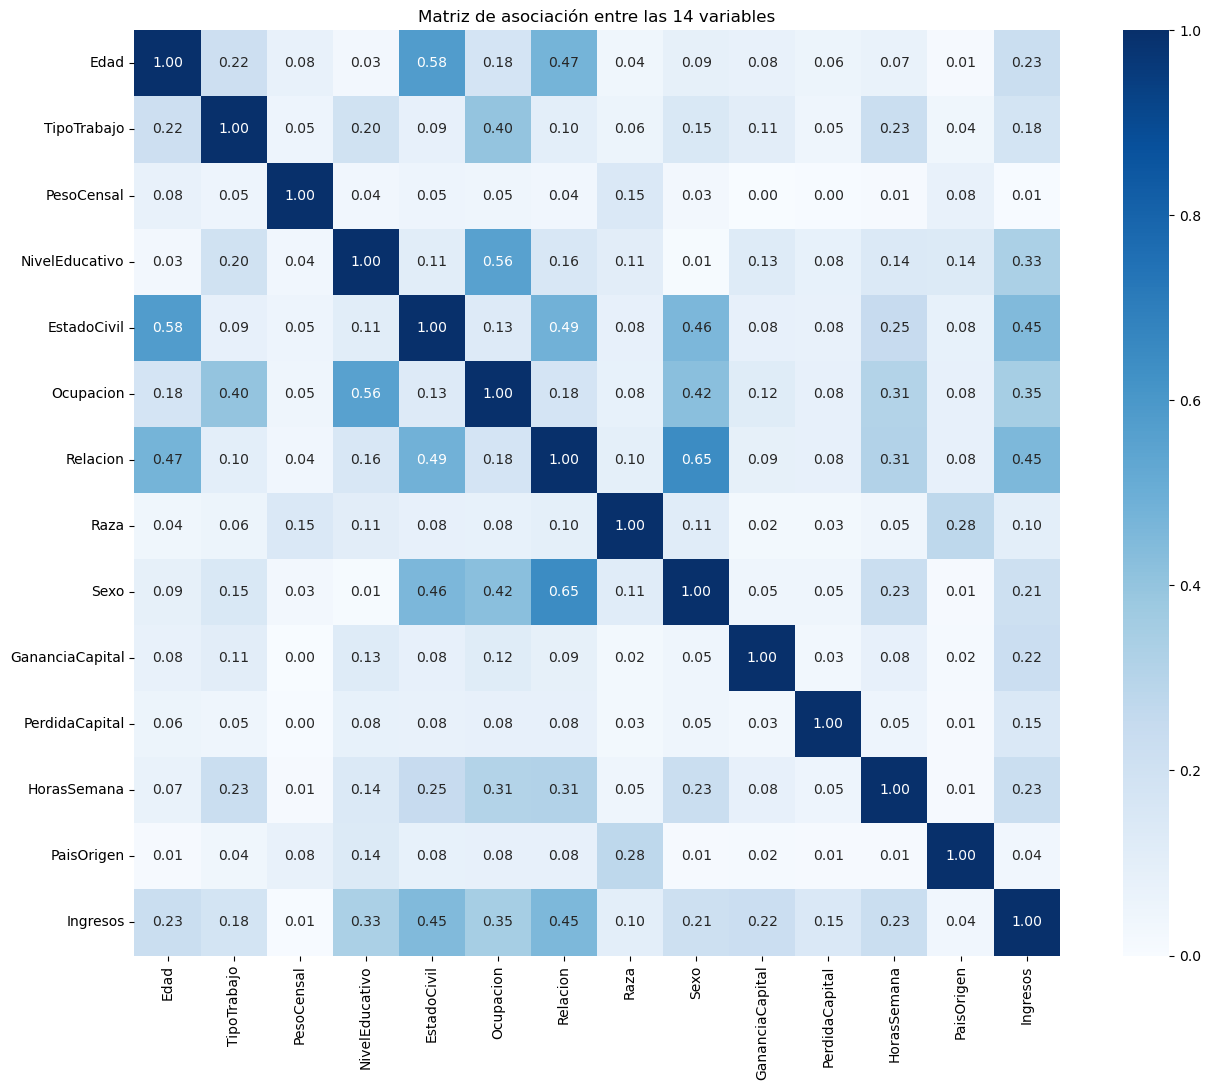

In [81]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

datos = df11.toPandas()

numericas = [
    "Edad", "PesoCensal", "NivelEducativo",
    "GananciaCapital", "PerdidaCapital",
    "HorasSemana", "Ingresos"
]

categoricas = [c for c in datos.columns if c not in numericas]

def asociacion(x, y, x_num, y_num):
    if x_num and y_num:
        return abs(x.corr(y))

    if not x_num and not y_num:
        tabla = pd.crosstab(x, y)
        chi2 = chi2_contingency(tabla, correction=False)[0]
        n = tabla.to_numpy().sum()
        k = min(tabla.shape) - 1
        return np.sqrt(chi2 / (n * k)) if k > 0 else 0

    if x_num:
        x, y = y, x

    grupos = y.groupby(x)
    media = y.mean()
    ss_entre = sum(len(g) * (g.mean() - media)**2
                   for _, g in grupos)
    ss_total = ((y - media)**2).sum()

    return np.sqrt(ss_entre / ss_total) if ss_total > 0 else 0

columnas = datos.columns.tolist()
matriz = pd.DataFrame(index=columnas, columns=columnas, dtype=float)

for a in columnas:
    for b in columnas:
        matriz.loc[a, b] = asociacion(
            datos[a], datos[b],
            a in numericas, b in numericas
        )

plt.figure(figsize=(14, 11))

sns.heatmap(
    matriz,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Matriz de asociación entre las 14 variables")
plt.tight_layout()
plt.show()

#### **5.15. Análisis de redundancia entre variables predictoras**

Se analizaron las asociaciones entre los predictores para identificar posibles relaciones redundantes que pudieran afectar el modelado.

**Relacion y Sexo (0,65):** Presentan la asociación más elevada, posiblemente porque categorías como Esposo y Esposa están estrechamente relacionadas con el sexo registrado.

**Edad y EstadoCivil (0,58):** Su asociación podría reflejar diferencias en la situación conyugal según las etapas de la vida.

**NivelEducativo y Ocupacion (0,56):** Sugiere una relación entre la formación académica y el tipo de actividad laboral desempeñada.

**EstadoCivil y Relacion (0,49):** Ambas variables contienen información sobre las características familiares, por lo que podrían presentar cierto grado de redundancia.

**TipoTrabajo y Ocupacion (0,40):** Presentan una asociación moderada, coherente con la relación entre la clasificación laboral y la actividad desempeñada.

En conclusión, ninguna asociación supera 0,70, por lo que no se identifican relaciones extremadamente fuertes entre los predictores. Se conservarán todas las variables

In [82]:
# Excluir la variable objetivo
matrizPredictores = matriz.drop(
    index="Ingresos",
    columns="Ingresos"
)

# Identificar las asociaciones más altas
import numpy as np

pares = matrizPredictores.where(
    np.triu(np.ones(matrizPredictores.shape), k=1).astype(bool)
)

pares.stack().sort_values(ascending=False).head(15)

Relacion        Sexo           0.646542
Edad            EstadoCivil    0.578483
NivelEducativo  Ocupacion      0.556812
EstadoCivil     Relacion       0.488160
Edad            Relacion       0.473784
EstadoCivil     Sexo           0.459453
Ocupacion       Sexo           0.424215
TipoTrabajo     Ocupacion      0.400050
Relacion        HorasSemana    0.312930
Ocupacion       HorasSemana    0.308739
Raza            PaisOrigen     0.276690
EstadoCivil     HorasSemana    0.249175
Sexo            HorasSemana    0.228560
TipoTrabajo     HorasSemana    0.227963
Edad            TipoTrabajo    0.215443
dtype: float64

#### **5.16. Relación entre los grupos de edad y los ingresos**

Se dividió la población en seis grupos de edad para analizar cómo cambia la proporción de personas con ingresos superiores a 50K a lo largo de la vida.

**17-24 años:** Solamente el 1,10 % presenta ingresos altos, posiblemente debido a que muchas personas se encuentran estudiando o iniciando su trayectoria laboral.

**25-34 años:** La proporción aumenta al 16,82 %, lo que podría reflejar una mayor incorporación al mercado laboral y acumulación de experiencia.

**35-44 años:** El porcentaje alcanza el 33,29 %, evidenciando un incremento importante respecto a los grupos más jóvenes.

**45-54 años:** Presenta la mayor proporción de ingresos altos (39,39 %), lo que podría relacionarse con una mayor experiencia, especialización y acceso a cargos mejor remunerados.

**55-64 y 65-90 años:** Los porcentajes disminuyen al 32,16 % y 20,46 %, respectivamente. Esto podría estar relacionado con cambios en la participación laboral, reducción de jornadas o procesos de retiro.

En conclusión, la relación entre edad e ingresos presenta un comportamiento no lineal: aumenta progresivamente hasta los 45-54 años y disminuye posteriormente

In [83]:
df11.withColumn(
    "GrupoEdad",
    F.when(F.col("Edad") < 25, "17-24")
     .when(F.col("Edad") < 35, "25-34")
     .when(F.col("Edad") < 45, "35-44")
     .when(F.col("Edad") < 55, "45-54")
     .when(F.col("Edad") < 65, "55-64")
     .otherwise("65-90")
).groupBy("GrupoEdad").agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).orderBy("GrupoEdad").show()

+---------+-----+-----------------------+
|GrupoEdad|Total|PorcentajeIngresosAltos|
+---------+-----+-----------------------+
|    17-24| 8432|                    1.1|
|    25-34|12577|                  16.82|
|    35-44|12193|                  33.29|
|    45-54| 8771|                  39.39|
|    55-64| 4782|                  32.16|
|    65-90| 2087|                  20.46|
+---------+-----+-----------------------+



### **6. Creación de una nueva variable: PerfilSocioLaboral**

Se creó la variable PerfilSocioLaboral para clasificar a las personas en tres categorías (Bajo, Medio y Alto), combinando Edad, NivelEducativo, Ocupacion, HorasSemana y GananciaCapital.

Se evaluaron tres versiones. La primera obtuvo porcentajes de ingresos altos de 10,38 %, 31,40 % y 62,43 % para los perfiles Bajo, Medio y Alto, respectivamente. La segunda incorporó un sistema de puntuación y obtuvo 5,56 %, 25,21 % y 58,16 %. Finalmente, la tercera ajustó los intervalos a Bajo (0-2 puntos), Medio (3-6) y Alto (7-8), alcanzando 5,56 %, 28,84 % y 69,18 %, respectivamente.

Se seleccionó la tercera versión por presentar la mayor separación entre los perfiles Alto y Bajo (63,62 puntos porcentuales). La variable se incorporó a df14 y su utilidad predictiva deberá evaluarse posteriormente con datos de validación.

In [84]:
condiciones = (
    F.when(F.col("Edad").between(35, 54), 1).otherwise(0) +
    F.when(F.col("NivelEducativo") >= 13, 1).otherwise(0) +
    F.when(F.col("HorasSemana") >= 40, 1).otherwise(0)
)

df12 = df11.withColumn(
    "PerfilProfesional",
    F.when(condiciones == 3, "Alto")
     .when(condiciones == 2, "Medio")
     .otherwise("Bajo")
)

df12.groupBy("PerfilProfesional").agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).orderBy("PerfilProfesional").show()

+-----------------+-----+-----------------------+
|PerfilProfesional|Total|PorcentajeIngresosAltos|
+-----------------+-----+-----------------------+
|             Alto| 5558|                  62.43|
|             Bajo|25561|                  10.38|
|            Medio|17723|                   31.4|
+-----------------+-----+-----------------------+



In [85]:
# 1. Construcción del puntaje socio-laboral

puntaje = (
    # Nivel educativo (0-2 puntos)
    F.when(F.col("NivelEducativo") >= 13, 2)
     .when(F.col("NivelEducativo") >= 10, 1)
     .otherwise(0)

    # Ocupación (0-2 puntos)
    + F.when(
        F.col("Ocupacion").isin(
            "Directivos y gerentes",
            "Profesionales especializados"
        ), 2
    ).when(
        F.col("Ocupacion").isin(
            "Soporte técnico",
            "Servicios protección"
        ), 1
    ).otherwise(0)

    # Edad (0-2 puntos)
    + F.when(F.col("Edad").between(35, 54), 2)
       .when(F.col("Edad").between(25, 34) |
             F.col("Edad").between(55, 64), 1)
       .otherwise(0)

    # Horas semanales (0-1 punto)
    + F.when(F.col("HorasSemana") >= 40, 1)
       .otherwise(0)

    # Ganancias de capital (0-1 punto)
    + F.when(F.col("GananciaCapital") > 0, 1)
       .otherwise(0)
)

# 2. Crear la nueva variable de tres categorías

df13 = df11.withColumn(
    "PuntajeSocioLaboral", puntaje
).withColumn(
    "PerfilSocioLaboral",
    F.when(F.col("PuntajeSocioLaboral") >= 6, "Alto")
     .when(F.col("PuntajeSocioLaboral") >= 3, "Medio")
     .otherwise("Bajo")
)

# 3. Evaluar su relación con los ingresos

df13.groupBy("PerfilSocioLaboral").agg(
    F.count("*").alias("Total"),
    F.round(
        F.avg("Ingresos") * 100, 2
    ).alias("PorcentajeIngresosAltos")
).orderBy("PerfilSocioLaboral").show()

+------------------+-----+-----------------------+
|PerfilSocioLaboral|Total|PorcentajeIngresosAltos|
+------------------+-----+-----------------------+
|              Alto| 8666|                  58.16|
|              Bajo|17711|                   5.56|
|             Medio|22465|                  25.21|
+------------------+-----+-----------------------+



In [86]:
df14 = (
    df11
    .withColumn(
        "PerfilSocioLaboral",
        F.when(puntaje >= 7, "Alto")
         .when(puntaje >= 3, "Medio")
         .otherwise("Bajo")
    )
)

df14.groupBy("PerfilSocioLaboral").agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).orderBy("PerfilSocioLaboral").show()

+------------------+-----+-----------------------+
|PerfilSocioLaboral|Total|PorcentajeIngresosAltos|
+------------------+-----+-----------------------+
|              Alto| 4277|                  69.18|
|              Bajo|17711|                   5.56|
|             Medio|26854|                  28.84|
+------------------+-----+-----------------------+



### **7. Graficas**

#### **7.1. Distribución de ingresos según el perfil sociolaboral**

La proporción de ingresos superiores a 50K aumenta del 5,6 % en el perfil Bajo al 28,8 % en el Medio y al 69,2 % en el Alto. La diferencia de 63,6 puntos porcentuales entre los extremos evidencia una clara separación entre categorías. Esto sugiere que PerfilSocioLaboral puede ser útil para la clasificación de ingresos.

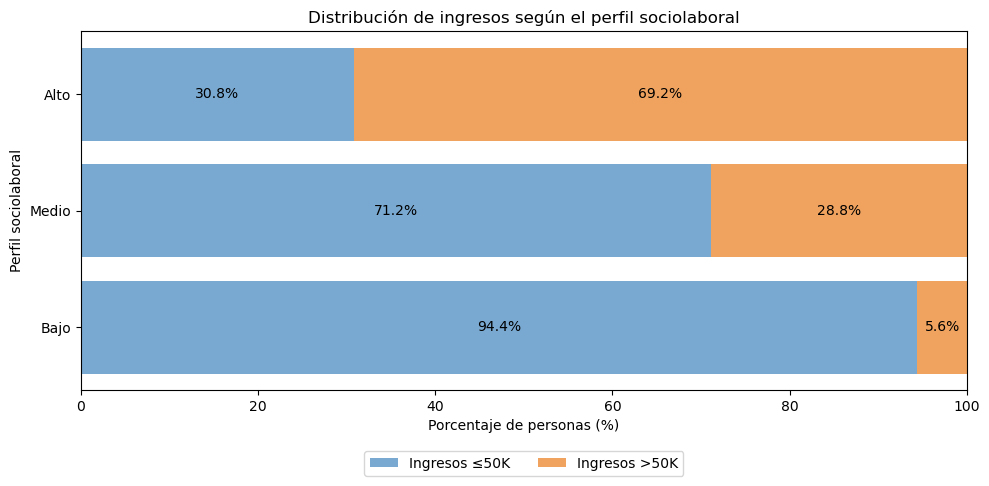

In [87]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Calcular proporciones por perfil
datos = (
    df14.groupBy("PerfilSocioLaboral")
    .agg(
        F.count("*").alias("Total"),
        (F.avg("Ingresos") * 100).alias("IngresosAltos")
    )
    .toPandas()
)

# Ordenar categorías
orden = ["Bajo", "Medio", "Alto"]
datos["PerfilSocioLaboral"] = datos["PerfilSocioLaboral"].astype(
    "category"
).cat.set_categories(orden, ordered=True)

datos = datos.sort_values("PerfilSocioLaboral")

datos["IngresosBajos"] = 100 - datos["IngresosAltos"]

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    datos["PerfilSocioLaboral"],
    datos["IngresosBajos"],
    color="#79A9D1",
    label="Ingresos ≤50K"
)

ax.barh(
    datos["PerfilSocioLaboral"],
    datos["IngresosAltos"],
    left=datos["IngresosBajos"],
    color="#F0A35E",
    label="Ingresos >50K"
)

# Porcentajes en las barras
for i, fila in enumerate(datos.itertuples()):
    ax.text(
        fila.IngresosBajos / 2, i,
        f"{fila.IngresosBajos:.1f}%",
        ha="center", va="center"
    )

    ax.text(
        fila.IngresosBajos + fila.IngresosAltos / 2, i,
        f"{fila.IngresosAltos:.1f}%",
        ha="center", va="center"
    )

ax.set_title("Distribución de ingresos según el perfil sociolaboral")
ax.set_xlabel("Porcentaje de personas (%)")
ax.set_ylabel("Perfil sociolaboral")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.show()

#### **7.2. Creación de la variable GrupoEducativo**

A partir de la gráfica anterior, se observó un comportamiento casi plano entre los niveles educativos 1 y 8, un crecimiento moderado entre 9 y 11, y un aumento mucho más pronunciado entre 12 y 16. Por esta razón, se creó la variable GrupoEducativo con tres categorías: Bajo (1-8), Medio (9-11) y Alto (12-16), con porcentajes de ingresos superiores a 50K de 5,71 %, 17,71 % y 45,46 %, respectivamente. Esta agrupación busca facilitar la identificación de patrones y podría mejorar el desempeño del modelo predictivo, lo cual deberá comprobarse posteriormente.

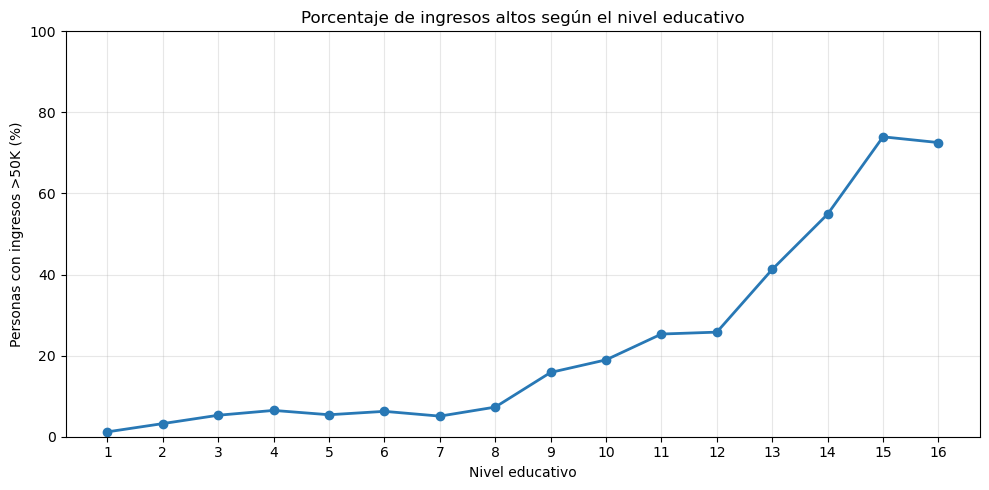

In [88]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Calcular ingresos altos por nivel educativo
datos = (
    df14.groupBy("NivelEducativo")
    .agg(
        F.count("*").alias("Total"),
        F.round(F.avg("Ingresos") * 100, 2).alias("IngresosAltos")
    )
    .orderBy("NivelEducativo")
    .toPandas()
)

# Crear gráfica
plt.figure(figsize=(10, 5))

plt.plot(
    datos["NivelEducativo"],
    datos["IngresosAltos"],
    marker="o",
    linewidth=2,
    color="#2878B5"
)

plt.title("Porcentaje de ingresos altos según el nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Personas con ingresos >50K (%)")
plt.xticks(range(1, 17))
plt.ylim(0, 100)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [89]:
from pyspark.sql import functions as F

df15 = df14.withColumn(
    "GrupoEducativo",
    F.when(F.col("NivelEducativo") <= 8, "Bajo")
     .when(F.col("NivelEducativo") <= 11, "Medio")
     .otherwise("Alto")
)

df15.groupBy("GrupoEducativo").agg(
    F.count("*").alias("Total"),
    F.round(F.avg("Ingresos") * 100, 2).alias("PorcentajeIngresosAltos")
).orderBy("GrupoEducativo").show()

+--------------+-----+-----------------------+
|GrupoEducativo|Total|PorcentajeIngresosAltos|
+--------------+-----+-----------------------+
|          Alto|13711|                  45.46|
|          Bajo| 6408|                   5.71|
|         Medio|28723|                  17.71|
+--------------+-----+-----------------------+



#### **7.3. Relación entre edad, nivel educativo e ingresos**

El mapa de calor muestra que la proporción de ingresos superiores a 50K aumenta con el nivel educativo en todos los grupos de edad. La combinación de 45-54 años y educación alta presenta el mayor porcentaje (62,3 %), seguida de 55-64 años (58,0 %) y 35-44 años (54,0 %). Esto evidencia que la edad y el nivel educativo presentan patrones conjuntos relevantes para la clasificación de ingresos.

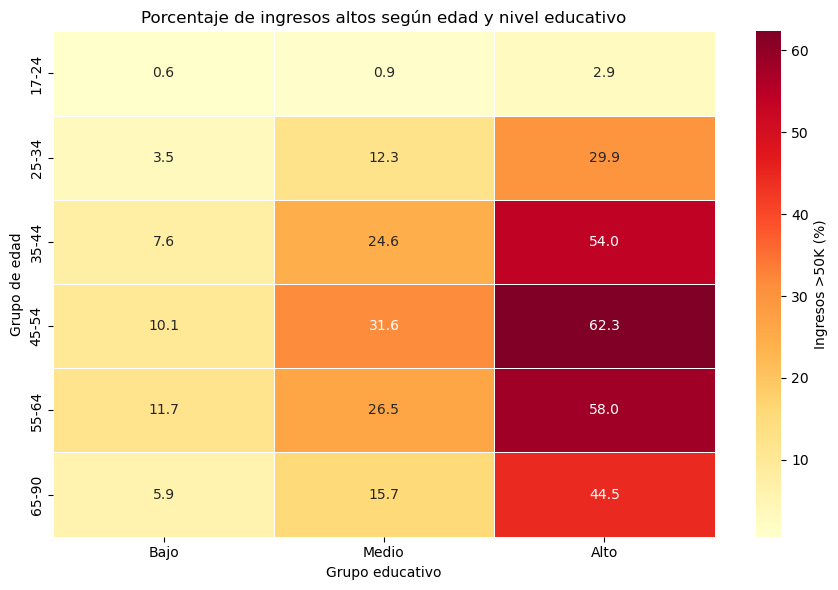

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

# Crear grupos de edad para la visualización
datos = (
    df15.withColumn(
        "GrupoEdad",
        F.when(F.col("Edad") < 25, "17-24")
         .when(F.col("Edad") < 35, "25-34")
         .when(F.col("Edad") < 45, "35-44")
         .when(F.col("Edad") < 55, "45-54")
         .when(F.col("Edad") < 65, "55-64")
         .otherwise("65-90")
    )
    .groupBy("GrupoEdad", "GrupoEducativo")
    .agg(
        F.count("*").alias("Total"),
        F.round(F.avg("Ingresos") * 100, 2).alias("Porcentaje")
    )
    .toPandas()
)

# Organizar los datos
ordenEdad = ["17-24", "25-34", "35-44", "45-54", "55-64", "65-90"]
ordenEducacion = ["Bajo", "Medio", "Alto"]

matrizCalor = datos.pivot(
    index="GrupoEdad",
    columns="GrupoEducativo",
    values="Porcentaje"
).reindex(index=ordenEdad, columns=ordenEducacion)

# Crear mapa de calor
plt.figure(figsize=(9, 6))

sns.heatmap(
    matrizCalor,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Ingresos >50K (%)"}
)

plt.title("Porcentaje de ingresos altos según edad y nivel educativo")
plt.xlabel("Grupo educativo")
plt.ylabel("Grupo de edad")

plt.tight_layout()
plt.show()

#### **7.4. Relación entre ocupación e ingresos**

Las ocupaciones con mayor proporción de ingresos superiores a 50K son Directivos y gerentes (47,8 %) y Profesionales especializados (45,1 %). En contraste, Servicio doméstico (1,2 %) y Otros servicios (4,1 %) presentan los porcentajes más bajos. Estas diferencias evidencian que el tipo de ocupación está asociado con los ingresos y puede ser una variable relevante para el modelo predictivo.

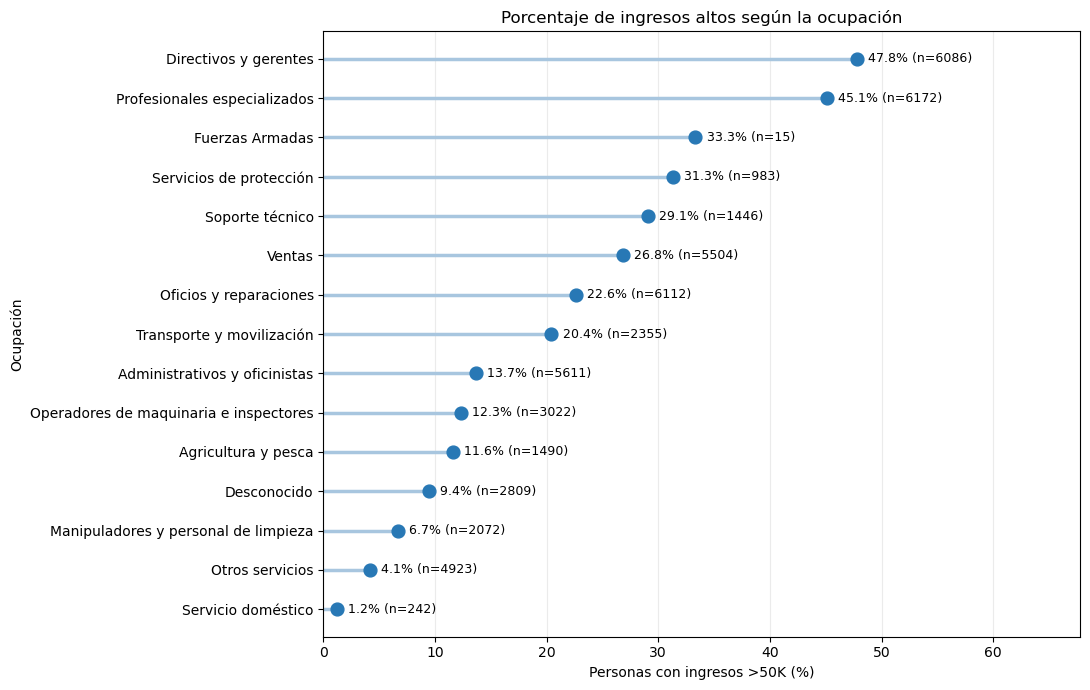

In [91]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Calcular ingresos altos por ocupación
datos = (
    df15.groupBy("Ocupacion")
    .agg(
        F.count("*").alias("Total"),
        F.round(F.avg("Ingresos") * 100, 2).alias("Porcentaje")
    )
    .orderBy("Porcentaje")
    .toPandas()
)

# Crear gráfico de piruletas
fig, ax = plt.subplots(figsize=(11, 7))

y = range(len(datos))

ax.hlines(
    y=y,
    xmin=0,
    xmax=datos["Porcentaje"],
    color="#A8C6DF",
    linewidth=2.5
)

ax.scatter(
    datos["Porcentaje"],
    y,
    color="#2878B5",
    s=85,
    zorder=3
)

# Mostrar porcentajes y cantidades
for i, fila in enumerate(datos.itertuples()):
    ax.text(
        fila.Porcentaje + 1,
        i,
        f"{fila.Porcentaje:.1f}% (n={fila.Total})",
        va="center",
        fontsize=9
    )

ax.set_yticks(list(y))
ax.set_yticklabels(datos["Ocupacion"])
ax.set_xlim(0, max(datos["Porcentaje"]) + 20)

ax.set_title("Porcentaje de ingresos altos según la ocupación")
ax.set_xlabel("Personas con ingresos >50K (%)")
ax.set_ylabel("Ocupación")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

#### **7.5. Relación entre horas trabajadas e ingresos**

En el gráfico de dispersión se observa que las jornadas inferiores a 30 horas presentan generalmente menos del 10 % de ingresos altos, mientras que entre 40 y 60 horas los porcentajes aumentan considerablemente. Sin embargo, después de las 60 horas no se evidencia un crecimiento sostenido.

El gráfico de violín muestra que ambos grupos se concentran alrededor de las 40 horas semanales, aunque las personas con ingresos superiores a 50K presentan una mayor concentración entre 45 y 60 horas. Esto sugiere que las jornadas más largas están asociadas con mayores ingresos

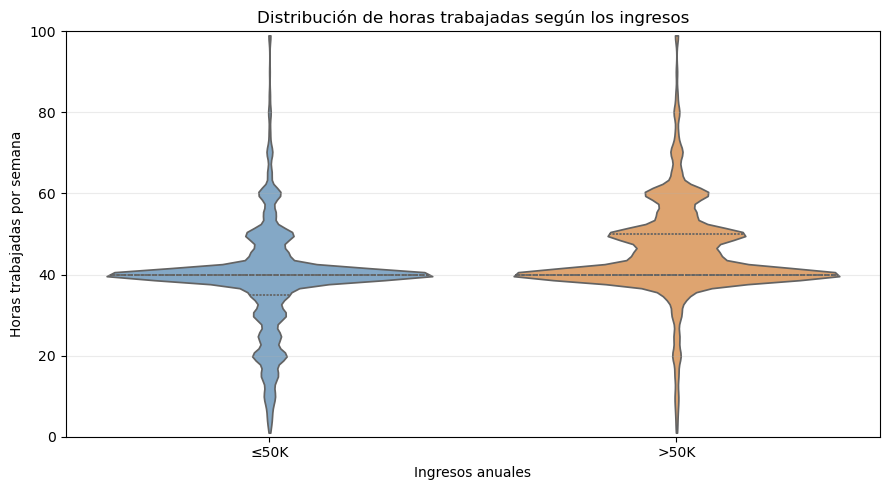

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar las variables
datos = df15.select("HorasSemana", "Ingresos").toPandas()

# Etiquetar las categorías de ingresos
datos["Ingresos"] = datos["Ingresos"].map({
    0: "≤50K",
    1: ">50K"
})

# Crear gráfico de violín
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=datos,
    x="Ingresos",
    y="HorasSemana",
    order=["≤50K", ">50K"],
    hue="Ingresos",
    palette=["#79A9D1", "#F0A35E"],
    inner="quartile",
    cut=0,
    legend=False
)

plt.title("Distribución de horas trabajadas según los ingresos")
plt.xlabel("Ingresos anuales")
plt.ylabel("Horas trabajadas por semana")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

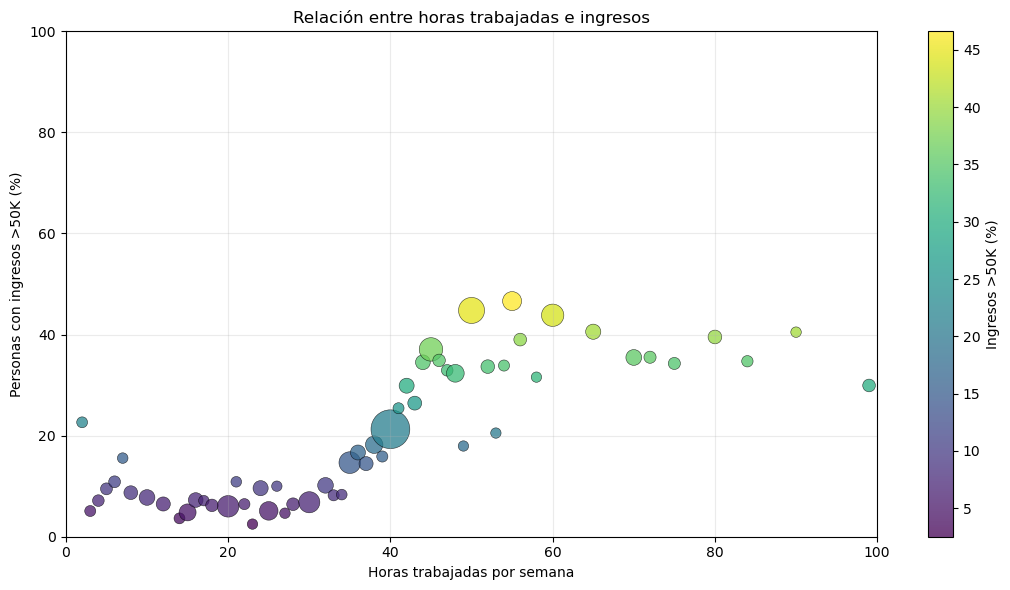

In [93]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Calcular porcentaje de ingresos altos por horas trabajadas
datos = (
    df15.groupBy("HorasSemana")
    .agg(
        F.count("*").alias("Total"),
        (F.avg("Ingresos") * 100).alias("Porcentaje")
    )
    .filter(F.col("Total") >= 30)
    .orderBy("HorasSemana")
    .toPandas()
)

# Crear gráfico de dispersión
plt.figure(figsize=(11, 6))

plt.scatter(
    datos["HorasSemana"],
    datos["Porcentaje"],
    s=25 + datos["Total"] ** 0.5 * 5,
    c=datos["Porcentaje"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(label="Ingresos >50K (%)")

plt.title("Relación entre horas trabajadas e ingresos")
plt.xlabel("Horas trabajadas por semana")
plt.ylabel("Personas con ingresos >50K (%)")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### **7.6. Relación entre estado civil e ingresos**

Las personas casadas con cónyuge civil presentan la mayor proporción de ingresos superiores a 50K (44,6 %), mientras que quienes nunca se han casado registran la menor (4,5 %). Las personas divorciadas, viudas y separadas presentan porcentajes cercanos al 10 % o inferiores. Estos resultados evidencian una asociación importante entre EstadoCivil e Ingresos, aunque no implican una relación causal.

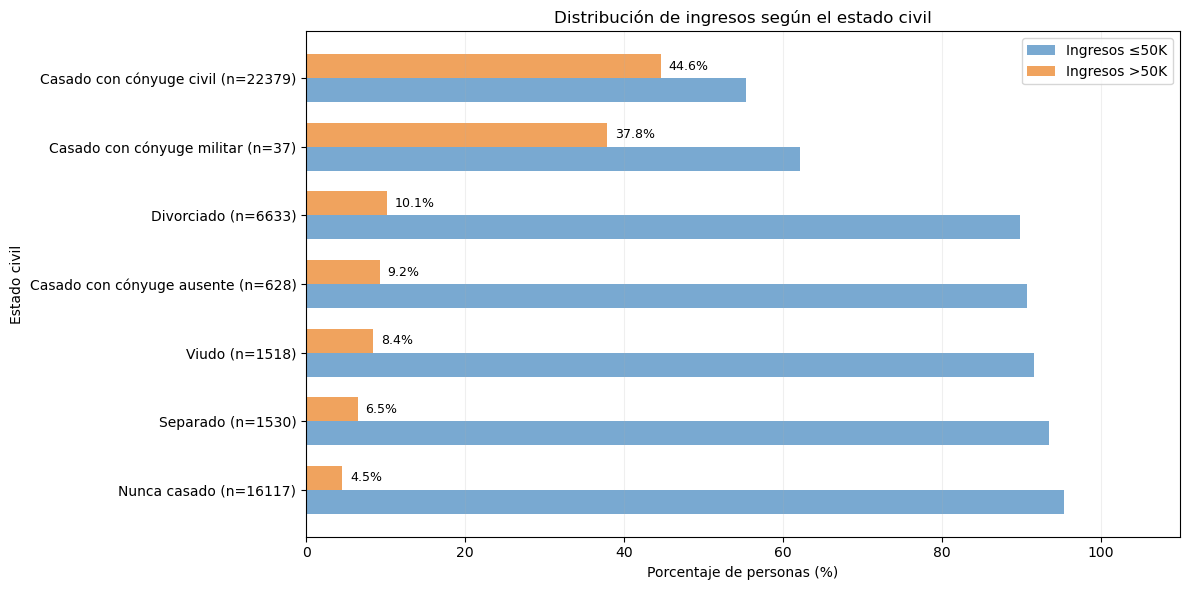

In [94]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import functions as F

# Calcular porcentajes por estado civil
datos = (
    df15.groupBy("EstadoCivil")
    .agg(
        F.count("*").alias("Total"),
        (F.avg("Ingresos") * 100).alias("IngresosAltos")
    )
    .toPandas()
)

datos["IngresosBajos"] = 100 - datos["IngresosAltos"]
datos = datos.sort_values("IngresosAltos", ascending=True)

# Crear gráfico de barras agrupadas
y = np.arange(len(datos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    y - ancho/2,
    datos["IngresosBajos"],
    height=ancho,
    color="#79A9D1",
    label="Ingresos ≤50K"
)

ax.barh(
    y + ancho/2,
    datos["IngresosAltos"],
    height=ancho,
    color="#F0A35E",
    label="Ingresos >50K"
)

# Mostrar porcentajes y tamaños de muestra
for i, fila in enumerate(datos.itertuples()):
    ax.text(
        fila.IngresosAltos + 1,
        i + ancho/2,
        f"{fila.IngresosAltos:.1f}%",
        va="center",
        fontsize=9
    )

ax.set_yticks(y)
ax.set_yticklabels([
    f"{estado} (n={total})"
    for estado, total in zip(datos["EstadoCivil"], datos["Total"])
])

ax.set_xlim(0, 110)
ax.set_xlabel("Porcentaje de personas (%)")
ax.set_ylabel("Estado civil")
ax.set_title("Distribución de ingresos según el estado civil")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

#### **7.7. Relación entre ganancias, pérdidas de capital e ingresos**

Las personas con ganancias de capital positivas presentan un 61,7 % de ingresos superiores a 50K, frente al 20,5 % de quienes no registran ganancias. De igual manera, quienes presentan pérdidas de capital positivas alcanzan un 50,1 %, frente al 22,6 % de quienes no registran pérdidas. Esto evidencia que ambas variables están asociadas con los ingresos altos y pueden aportar información relevante al modelo predictivo.

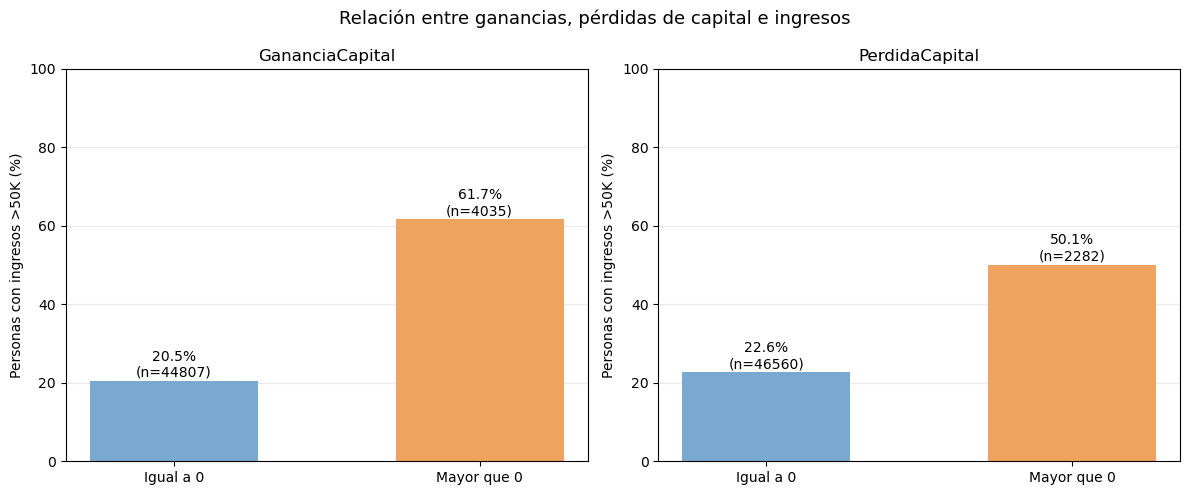

In [95]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

variables = ["GananciaCapital", "PerdidaCapital"]
colores = ["#79A9D1", "#F0A35E"]

for ax, variable in zip(axes, variables):

    datos = (
        df15.withColumn(
            "Categoria",
            F.when(F.col(variable) > 0, "Mayor que 0")
             .otherwise("Igual a 0")
        )
        .groupBy("Categoria")
        .agg(
            F.count("*").alias("Total"),
            (F.avg("Ingresos") * 100).alias("Porcentaje")
        )
        .toPandas()
    )

    datos["Categoria"] = datos["Categoria"].astype(
        "category"
    ).cat.set_categories(
        ["Igual a 0", "Mayor que 0"], ordered=True
    )
    datos = datos.sort_values("Categoria")

    barras = ax.bar(
        datos["Categoria"],
        datos["Porcentaje"],
        color=colores,
        width=0.55
    )

    for barra, fila in zip(barras, datos.itertuples()):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            f"{fila.Porcentaje:.1f}%\n(n={fila.Total})",
            ha="center",
            fontsize=10
        )

    ax.set_title(variable)
    ax.set_ylabel("Personas con ingresos >50K (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.suptitle(
    "Relación entre ganancias, pérdidas de capital e ingresos",
    fontsize=13
)

plt.tight_layout()
plt.show()

#### **7.8. Relación entre tipo de trabajo e ingresos**

Los trabajadores independientes constituidos presentan la mayor proporción de ingresos superiores a 50K (55,3 %), seguidos por los empleados del Gobierno federal (39,2 %), ambos por encima del promedio general de 23,9 %. En contraste, el sector privado registra un 21,8 %, mientras que la categoría Desconocido alcanza apenas el 9,5 %. Estos resultados muestran diferencias importantes entre los tipos de trabajo, aunque las categorías con pocas observaciones deben interpretarse con precaución.

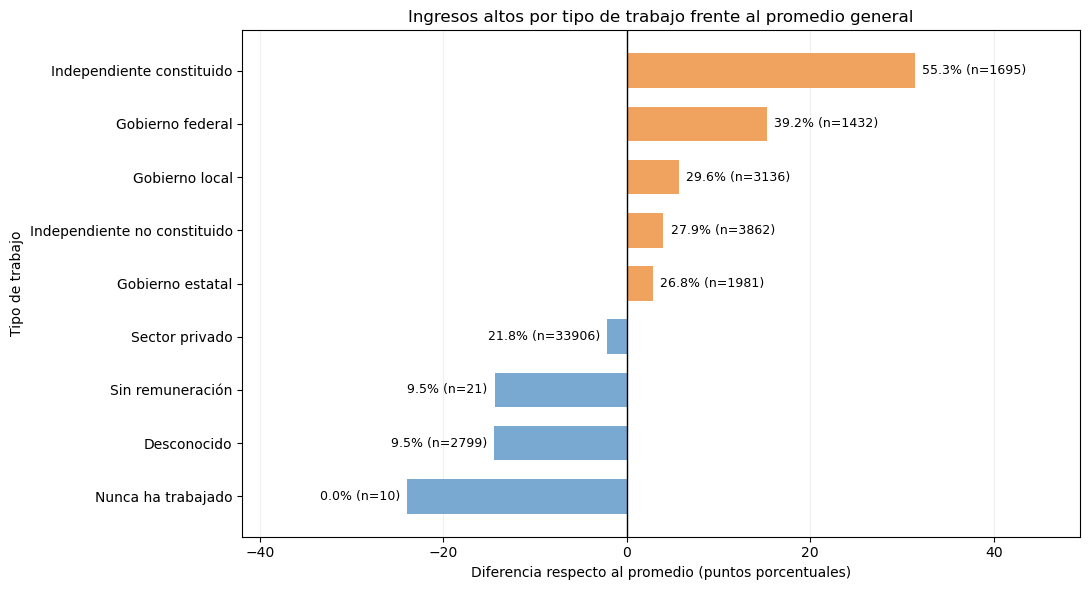

In [96]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import functions as F

# Calcular porcentaje de ingresos altos por tipo de trabajo
datos = (
    df15.groupBy("TipoTrabajo")
    .agg(
        F.count("*").alias("Total"),
        (F.avg("Ingresos") * 100).alias("Porcentaje")
    )
    .toPandas()
)

# Promedio general
promedio = df15.agg(
    (F.avg("Ingresos") * 100).alias("Promedio")
).first()["Promedio"]

# Diferencia frente al promedio general
datos["Diferencia"] = datos["Porcentaje"] - promedio
datos = datos.sort_values("Diferencia")

colores = np.where(
    datos["Diferencia"] >= 0,
    "#F0A35E",
    "#79A9D1"
)

# Crear gráfica
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    datos["TipoTrabajo"],
    datos["Diferencia"],
    color=colores,
    height=0.65
)

ax.axvline(0, color="black", linewidth=1)

# Etiquetas
for barra, fila in zip(barras, datos.itertuples()):
    valor = fila.Diferencia

    ax.text(
        valor + (0.8 if valor >= 0 else -0.8),
        barra.get_y() + barra.get_height()/2,
        f"{fila.Porcentaje:.1f}% (n={fila.Total})",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9
    )

ax.set_xlim(
    min(datos["Diferencia"]) - 18,
    max(datos["Diferencia"]) + 18
)

ax.set_title("Ingresos altos por tipo de trabajo frente al promedio general")
ax.set_xlabel("Diferencia respecto al promedio (puntos porcentuales)")
ax.set_ylabel("Tipo de trabajo")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### **7.9. Relación entre posición familiar e ingresos**

Las categorías Esposa y Esposo presentan las mayores proporciones de ingresos superiores a 50K, con 46,9 % y 44,9 %, respectivamente. En contraste, Hijo registra apenas 1,5 %, seguido de Otro familiar (3,5 %) y Sin pareja (6,0 %). Estos resultados muestran una asociación importante entre la posición familiar y los ingresos, similar a la observada con EstadoCivil.

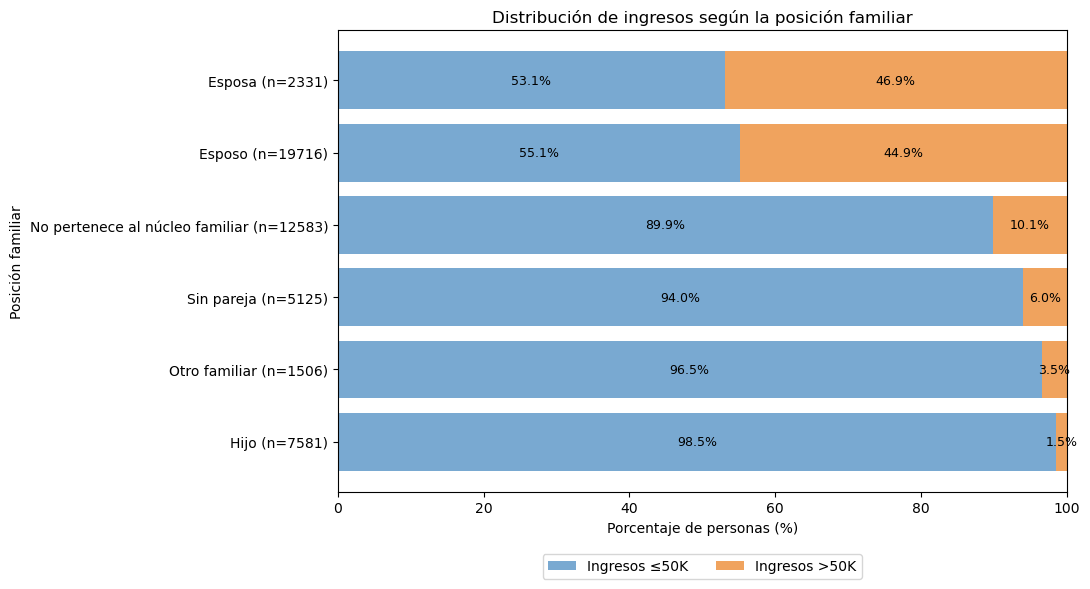

In [97]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import functions as F

# Calcular porcentajes por posición familiar
datos = (
    df15.groupBy("Relacion")
    .agg(
        F.count("*").alias("Total"),
        (F.avg("Ingresos") * 100).alias("IngresosAltos")
    )
    .toPandas()
)

datos["IngresosBajos"] = 100 - datos["IngresosAltos"]
datos = datos.sort_values("IngresosAltos", ascending=True)

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 6))

y = np.arange(len(datos))

ax.barh(
    y,
    datos["IngresosBajos"],
    color="#79A9D1",
    label="Ingresos ≤50K"
)

ax.barh(
    y,
    datos["IngresosAltos"],
    left=datos["IngresosBajos"],
    color="#F0A35E",
    label="Ingresos >50K"
)

# Mostrar porcentajes
for i, fila in enumerate(datos.itertuples()):
    ax.text(
        fila.IngresosBajos / 2,
        i,
        f"{fila.IngresosBajos:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )

    ax.text(
        fila.IngresosBajos + fila.IngresosAltos / 2,
        i,
        f"{fila.IngresosAltos:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )

# Etiquetas con cantidad de observaciones
ax.set_yticks(y)
ax.set_yticklabels([
    f"{relacion} (n={total})"
    for relacion, total in zip(datos["Relacion"], datos["Total"])
])

ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de personas (%)")
ax.set_ylabel("Posición familiar")
ax.set_title("Distribución de ingresos según la posición familiar")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

### **8. Preparación y codificación de variables**

Se eliminó la variable PesoCensal como predictor, debido a que representa el peso estadístico de cada observación y no una característica individual directamente relacionada con los ingresos. Se conservó por separado, obteniendo el conjunto df16 con 48.842 registros y 15 variables.

Posteriormente, se utilizó StringIndexer de PySpark para transformar las nueve variables categóricas en índices numéricos, identificados con IND. Se eliminaron las columnas categóricas originales y se creó df17, conservando 15 variables numéricas, incluida Ingresos como variable objetivo.


In [98]:
# Guardar el peso censal por separado
pesoCensal = df15.select("PesoCensal")

# Crear un nuevo DataFrame sin PesoCensal
df16 = df15.drop("PesoCensal")

# Verificar las variables restantes
print("Columnas:", len(df16.columns))
print("Registros:", df16.count())

df16.printSchema()

Columnas: 15
Registros: 48842
root
 |-- Edad: integer (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- NivelEducativo: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: double (nullable = true)
 |-- PerdidaCapital: double (nullable = true)
 |-- HorasSemana: double (nullable = true)
 |-- PaisOrigen: string (nullable = false)
 |-- Ingresos: integer (nullable = false)
 |-- PerfilSocioLaboral: string (nullable = false)
 |-- GrupoEducativo: string (nullable = false)



In [99]:
from pyspark.ml.feature import StringIndexer
from pyspark.ml import Pipeline

In [100]:
# Separar las variables categóricas
categoricas = [
    "TipoTrabajo",
    "EstadoCivil",
    "Ocupacion",
    "Relacion",
    "Raza",
    "Sexo",
    "PaisOrigen",
    "PerfilSocioLaboral",
    "GrupoEducativo"
]


In [101]:
# Separar las variables numéricas
noCategoricas = [
    "Edad",
    "NivelEducativo",
    "GananciaCapital",
    "PerdidaCapital",
    "HorasSemana",
    "Ingresos"
]


In [106]:
# Crear los indexadores
indices = [
    StringIndexer(
        inputCol=variable,
        outputCol=variable + "IND",
        handleInvalid="keep"
    )
    for variable in categoricas
]

# Crear la tubería de transformación
tuberia = Pipeline(stages=indices)

# Transformar las variables categóricas
df17 = tuberia.fit(df16).transform(df16)

# Eliminar las columnas categóricas originales
df17 = df17.drop(*categoricas)

# Inspeccionar el resultado
print("Columnas:", len(df17.columns))
print("Registros:", df17.count())

df17.printSchema()
df17.show(5, truncate=False)

Columnas: 15
Registros: 48842
root
 |-- Edad: integer (nullable = true)
 |-- NivelEducativo: integer (nullable = true)
 |-- GananciaCapital: double (nullable = true)
 |-- PerdidaCapital: double (nullable = true)
 |-- HorasSemana: double (nullable = true)
 |-- Ingresos: integer (nullable = false)
 |-- TipoTrabajoIND: double (nullable = false)
 |-- EstadoCivilIND: double (nullable = false)
 |-- OcupacionIND: double (nullable = false)
 |-- RelacionIND: double (nullable = false)
 |-- RazaIND: double (nullable = false)
 |-- SexoIND: double (nullable = false)
 |-- PaisOrigenIND: double (nullable = false)
 |-- PerfilSocioLaboralIND: double (nullable = false)
 |-- GrupoEducativoIND: double (nullable = false)

+----+--------------+---------------+--------------+-----------+--------+--------------+--------------+------------+-----------+-------+-------+-------------+---------------------+-----------------+
|Edad|NivelEducativo|GananciaCapital|PerdidaCapital|HorasSemana|Ingresos|TipoTrabajoIND|Es

### **9. Vectorización, división y ponderación de datos**

Se agruparon las 14 variables predictoras en el vector Independientes y se creó df18, conservando Ingresos como variable objetivo y PesoCensal por separado. Los datos se dividieron en 80 % para entrenamiento y 20 % para prueba.

Como aproximadamente el 76 % de las personas tiene ingresos ≤50K y el 24 % supera los 50K, se creó PesoClase para equilibrar la importancia de ambas categorías durante el entrenamiento, sin eliminar registros.

Así se obtuvo trainPonderado. PesoCensal se mantuvo aparte porque representa el peso estadístico de cada registro, mientras que PesoClase corrige el desbalance de la variable objetivo.

In [107]:
from pyspark.ml.feature import VectorAssembler

columnasModelo = df17.drop("Ingresos").columns

df17ConPeso = tuberia.fit(df16).transform(df15).drop(*categoricas)

varIndependientes = VectorAssembler(
    inputCols=columnasModelo,
    outputCol="Independientes"
)

df18 = varIndependientes.transform(df17ConPeso).select(
    "Independientes",
    "Ingresos",
    "PesoCensal"
)

df18.show(5, truncate=False)

+---------------------------------------------------------------+--------+----------+
|Independientes                                                 |Ingresos|PesoCensal|
+---------------------------------------------------------------+--------+----------+
|[39.0,13.0,2174.0,0.0,40.0,4.0,1.0,3.0,1.0,0.0,0.0,0.0,0.0,1.0]|0       |77516.0   |
|(14,[0,1,4,5,7,13],[50.0,13.0,13.0,1.0,2.0,1.0])               |0       |83311.0   |
|(14,[0,1,4,6,7,8],[38.0,9.0,40.0,2.0,9.0,1.0])                 |0       |215646.0  |
|(14,[0,1,4,7,9,13],[53.0,7.0,40.0,9.0,1.0,2.0])                |0       |234721.0  |
|(14,[0,1,4,8,9,10,11,13],[28.0,13.0,40.0,4.0,1.0,1.0,1.0,1.0]) |0       |338409.0  |
+---------------------------------------------------------------+--------+----------+
only showing top 5 rows



In [109]:
train, test = df18.randomSplit([0.8, 0.2], seed=1234)

train = train.cache()
test = test.cache()

print("Registros de entrenamiento:", train.count())
print("Registros de prueba:", test.count())

print("Porcentaje de entrenamiento:", round(train.count() / df18.count() * 100, 2), "%")
print("Porcentaje de prueba:", round(test.count() / df18.count() * 100, 2), "%")

Registros de entrenamiento: 39040
Registros de prueba: 9802
Porcentaje de entrenamiento: 79.93 %
Porcentaje de prueba: 20.07 %


In [111]:

total = train.count()

conIngresosAltos = train.filter(F.col("Ingresos") == 1).count()
sinIngresosAltos = train.filter(F.col("Ingresos") == 0).count()

porcentajeAltos = conIngresosAltos / total
porcentajeBajos = sinIngresosAltos / total

pesoIngresosAltos = sinIngresosAltos / conIngresosAltos

print(f"Ingresos >50K: {porcentajeAltos:.4f}")
print(f"Ingresos ≤50K: {porcentajeBajos:.4f}")
print(f"Peso para ingresos altos: {pesoIngresosAltos:.4f}")

Ingresos >50K: 0.2403
Ingresos ≤50K: 0.7597
Peso para ingresos altos: 3.1616


In [112]:
trainPonderado = train.withColumn(
    "PesoClase",
    F.when(F.col("Ingresos") == 1, pesoIngresosAltos)
     .otherwise(1.0)
)

trainPonderado.groupBy("Ingresos").agg(
    F.count("*").alias("Total"),
    F.first("PesoClase").alias("PesoClase"),
    F.round(F.sum("PesoClase"), 2).alias("PesoTotal")
).orderBy("Ingresos").show()

+--------+-----+------------------+---------+
|Ingresos|Total|         PesoClase|PesoTotal|
+--------+-----+------------------+---------+
|       0|29659|               1.0|  29659.0|
|       1| 9381|3.1616032405926875|  29659.0|
+--------+-----+------------------+---------+



In [113]:
from pyspark.ml.classification import LogisticRegression

train, test = df18.randomSplit([0.8, 0.2], seed=1234)

train = train.cache()
test = test.cache()

total = train.count()
conIngresosAltos = train.filter(F.col("Ingresos") == 1).count()
sinIngresosAltos = total - conIngresosAltos

pesoIngresosAltos = sinIngresosAltos / conIngresosAltos

trainPonderado = train.withColumn(
    "PesoClase",
    F.when(F.col("Ingresos") == 1, pesoIngresosAltos)
     .otherwise(1.0)
)

rLog = LogisticRegression(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0,
    standardization=True
)

modeloRLog = rLog.fit(trainPonderado)

predRLog = modeloRLog.transform(test)

print("Entrenamiento:", total)
print("Prueba:", test.count())
print("Peso de ingresos altos:", round(pesoIngresosAltos, 4))

predRLog.select(
    "Ingresos", "prediction", "probability"
).show(5, truncate=False)

26/11/24 21:57:34 WARN CacheManager: Asked to cache already cached data.
26/11/24 21:57:34 WARN CacheManager: Asked to cache already cached data.


Entrenamiento: 39040
Prueba: 9802
Peso de ingresos altos: 3.1616
+--------+----------+-----------------------------------------+
|Ingresos|prediction|probability                              |
+--------+----------+-----------------------------------------+
|1       |1.0       |[1.196536839215415E-5,0.9999880346316078]|
|1       |1.0       |[0.3733026670708248,0.6266973329291752]  |
|0       |1.0       |[0.16600688101785113,0.8339931189821489] |
|1       |1.0       |[0.12234351496586084,0.8776564850341392] |
|0       |1.0       |[0.1724235510469749,0.8275764489530251]  |
+--------+----------+-----------------------------------------+
only showing top 5 rows



### **10. Regresión logística**

Se entrenó un modelo de regresión logística utilizando PesoClase para compensar el desbalance de ingresos. En los 9.802 registros de prueba obtuvo un Accuracy de 77,88 %, una Precisión de 51,91 %, un Recall de 81,40 %, un F1-Score de 63,39 % y un AUC-ROC de 0,8726.

La matriz de confusión muestra que el modelo identificó correctamente 1.877 personas con ingresos superiores a 50K, pero no detectó 429 y clasificó incorrectamente a 1.739 personas con ingresos bajos como altos. Esto indica que el modelo logra identificar la mayoría de los casos de ingresos altos, aunque presenta una cantidad considerable de falsos positivos.

La curva ROC confirma una buena capacidad para distinguir entre ambas clases, por lo que este modelo servirá como referencia para comparar los siguientes algoritmos.

In [116]:
from pyspark.ml.classification import LogisticRegression

rLog = LogisticRegression(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0,
    standardization=True
)

modeloRLog = rLog.fit(trainPonderado)

predRLog = modeloRLog.transform(test)

predRLog.select(
    "Ingresos", "prediction", "probability"
).show(5, truncate=False)

+--------+----------+-----------------------------------------+
|Ingresos|prediction|probability                              |
+--------+----------+-----------------------------------------+
|1       |1.0       |[1.196536839215415E-5,0.9999880346316078]|
|1       |1.0       |[0.3733026670708248,0.6266973329291752]  |
|0       |1.0       |[0.16600688101785113,0.8339931189821489] |
|1       |1.0       |[0.12234351496586084,0.8776564850341392] |
|0       |1.0       |[0.1724235510469749,0.8275764489530251]  |
+--------+----------+-----------------------------------------+
only showing top 5 rows



In [117]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

datosEvaluacion = predRLog.select(
    "Ingresos", "prediction", "probability"
).toPandas()

y_real = datosEvaluacion["Ingresos"].astype(int)
y_pred = datosEvaluacion["prediction"].astype(int)
y_prob = datosEvaluacion["probability"].apply(lambda x: float(x[1]))

accuracyReg = accuracy_score(y_real, y_pred)
precisionReg = precision_score(y_real, y_pred, zero_division=0)
recallReg = recall_score(y_real, y_pred, zero_division=0)
f1Reg = f1_score(y_real, y_pred, zero_division=0)
aucReg = roc_auc_score(y_real, y_prob)

print("MÉTRICAS - REGRESIÓN LOGÍSTICA")
print(f"Accuracy:  {accuracyReg:.4f}")
print(f"Precisión: {precisionReg:.4f}")
print(f"Recall:    {recallReg:.4f}")
print(f"F1-Score:  {f1Reg:.4f}")
print(f"AUC-ROC:   {aucReg:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_real,
    y_pred,
    target_names=["Ingresos ≤50K", "Ingresos >50K"],
    zero_division=0
))

MÉTRICAS - REGRESIÓN LOGÍSTICA
Accuracy:  0.7788
Precisión: 0.5191
Recall:    0.8140
F1-Score:  0.6339
AUC-ROC:   0.8726

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Ingresos ≤50K       0.93      0.77      0.84      7496
Ingresos >50K       0.52      0.81      0.63      2306

     accuracy                           0.78      9802
    macro avg       0.72      0.79      0.74      9802
 weighted avg       0.83      0.78      0.79      9802



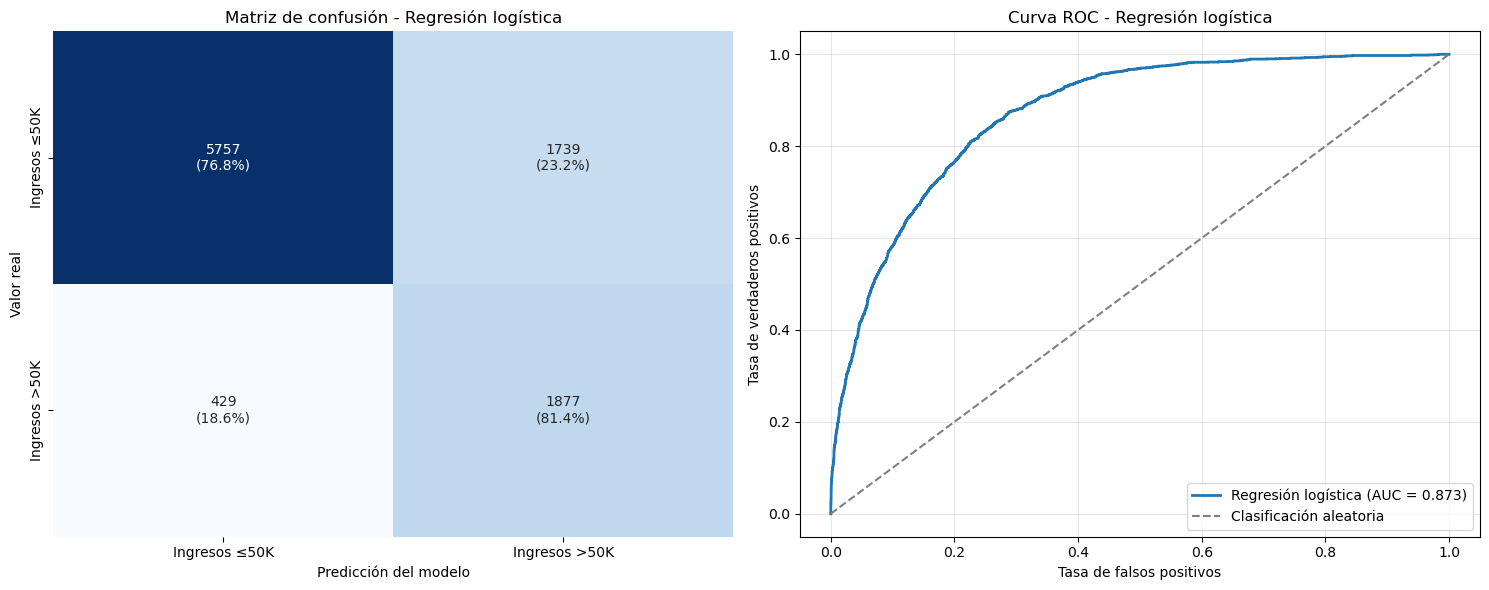

In [118]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

cmReg = confusion_matrix(y_real, y_pred, labels=[0, 1])

porcentajes = cmReg / cmReg.sum(axis=1, keepdims=True) * 100

etiquetas = np.array([
    f"{cmReg[i, j]}\n({porcentajes[i, j]:.1f}%)"
    for i in range(2)
    for j in range(2)
]).reshape(2, 2)

fprReg, tprReg, umbralesReg = roc_curve(y_real, y_prob)

fig, matrix = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cmReg,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    yticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    ax=matrix[0]
)

matrix[0].set_title("Matriz de confusión - Regresión logística")
matrix[0].set_xlabel("Predicción del modelo")
matrix[0].set_ylabel("Valor real")

matrix[1].plot(
    fprReg, tprReg,
    label=f"Regresión logística (AUC = {aucReg:.3f})",
    linewidth=2
)

matrix[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

matrix[1].set_title("Curva ROC - Regresión logística")
matrix[1].set_xlabel("Tasa de falsos positivos")
matrix[1].set_ylabel("Tasa de verdaderos positivos")
matrix[1].legend()
matrix[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **11. Árbol de decisión**

Se entrenó un árbol de decisión utilizando PesoClase para compensar el desbalance de ingresos. El modelo obtuvo un Accuracy de 79,21 %, una Precisión de 53,56 %, un Recall de 87,51 %, un F1-Score de 66,45 % y un AUC-ROC de 0,8907.

La matriz de confusión muestra que identificó correctamente 2.018 personas con ingresos superiores a 50K, aunque clasificó incorrectamente a 1.750 personas con ingresos bajos como altos. La precisión es moderada debido a estos falsos positivos, pero el Recall indica que detecta la mayoría de los casos de ingresos altos.

En comparación con la regresión logística, el árbol de decisión obtuvo mejores resultados en las cinco métricas evaluadas, por lo que es el mejor modelo hasta el momento.

In [120]:
from pyspark.ml.classification import DecisionTreeClassifier

arbol = DecisionTreeClassifier(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    maxDepth=8,
    maxBins=64,
    minInstancesPerNode=20,
    seed=1234
)

modeloArbol = arbol.fit(trainPonderado)

predArbol = modeloArbol.transform(test)

predArbol.select(
    "Ingresos", "prediction", "probability"
).show(5, truncate=False)

+--------+----------+-----------------------------------------+
|Ingresos|prediction|probability                              |
+--------+----------+-----------------------------------------+
|1       |1.0       |[0.005594331734482706,0.9944056682655172]|
|1       |1.0       |[0.14634045058861267,0.8536595494113873] |
|0       |1.0       |[0.14634045058861267,0.8536595494113873] |
|1       |1.0       |[0.14634045058861267,0.8536595494113873] |
|0       |0.0       |[1.0,0.0]                                |
+--------+----------+-----------------------------------------+
only showing top 5 rows



In [121]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

datosArbol = predArbol.select(
    "Ingresos", "prediction", "probability"
).toPandas()

y_realArbol = datosArbol["Ingresos"].astype(int)
y_predArbol = datosArbol["prediction"].astype(int)
y_probArbol = datosArbol["probability"].apply(lambda x: float(x[1]))

accuracyArbol = accuracy_score(y_realArbol, y_predArbol)
precisionArbol = precision_score(y_realArbol, y_predArbol, zero_division=0)
recallArbol = recall_score(y_realArbol, y_predArbol, zero_division=0)
f1Arbol = f1_score(y_realArbol, y_predArbol, zero_division=0)
aucArbol = roc_auc_score(y_realArbol, y_probArbol)

print("MÉTRICAS - ÁRBOL DE DECISIÓN")
print(f"Accuracy:  {accuracyArbol:.4f}")
print(f"Precisión: {precisionArbol:.4f}")
print(f"Recall:    {recallArbol:.4f}")
print(f"F1-Score:  {f1Arbol:.4f}")
print(f"AUC-ROC:   {aucArbol:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_realArbol,
    y_predArbol,
    target_names=["Ingresos ≤50K", "Ingresos >50K"],
    zero_division=0
))

MÉTRICAS - ÁRBOL DE DECISIÓN
Accuracy:  0.7921
Precisión: 0.5356
Recall:    0.8751
F1-Score:  0.6645
AUC-ROC:   0.8907

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Ingresos ≤50K       0.95      0.77      0.85      7496
Ingresos >50K       0.54      0.88      0.66      2306

     accuracy                           0.79      9802
    macro avg       0.74      0.82      0.76      9802
 weighted avg       0.85      0.79      0.81      9802



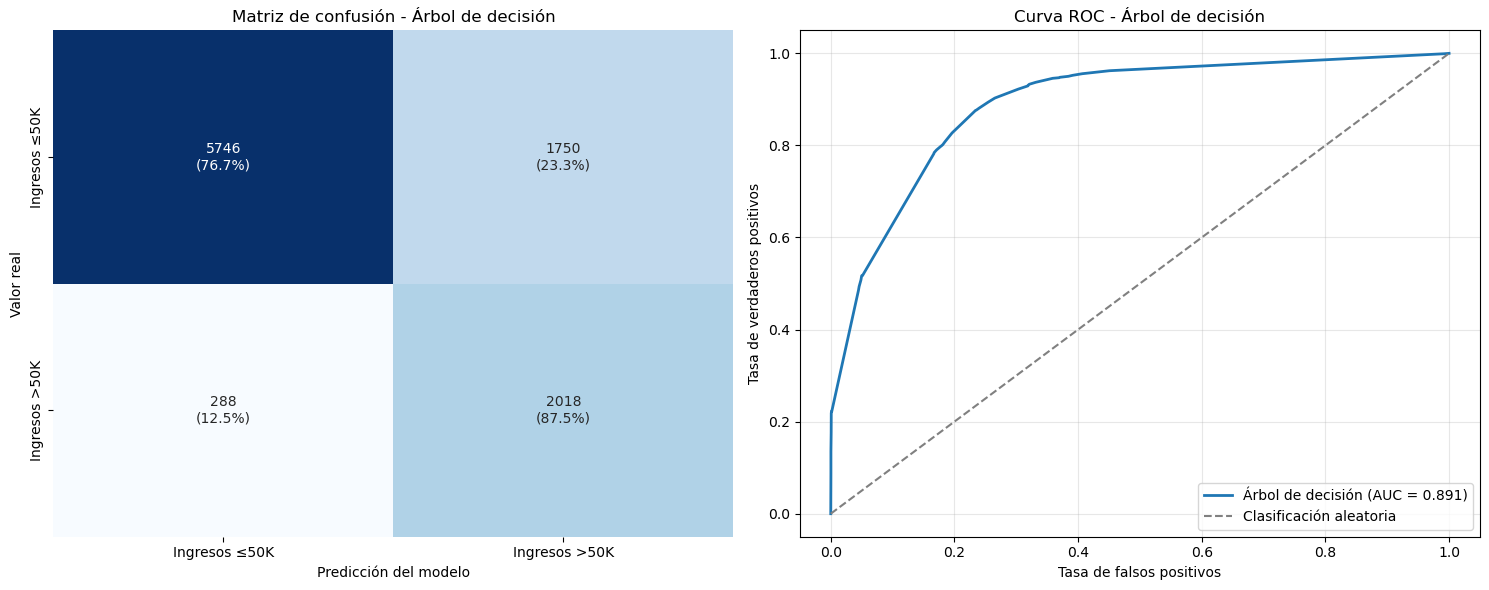

In [122]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

cmArbol = confusion_matrix(
    y_realArbol, y_predArbol, labels=[0, 1]
)

porcentajes = cmArbol / cmArbol.sum(axis=1, keepdims=True) * 100

etiquetas = np.array([
    f"{cmArbol[i, j]}\n({porcentajes[i, j]:.1f}%)"
    for i in range(2)
    for j in range(2)
]).reshape(2, 2)

fprArbol, tprArbol, umbralesArbol = roc_curve(
    y_realArbol, y_probArbol
)

fig, matrix = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cmArbol,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    yticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    ax=matrix[0]
)

matrix[0].set_title("Matriz de confusión - Árbol de decisión")
matrix[0].set_xlabel("Predicción del modelo")
matrix[0].set_ylabel("Valor real")

matrix[1].plot(
    fprArbol, tprArbol,
    label=f"Árbol de decisión (AUC = {aucArbol:.3f})",
    linewidth=2
)

matrix[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

matrix[1].set_title("Curva ROC - Árbol de decisión")
matrix[1].set_xlabel("Tasa de falsos positivos")
matrix[1].set_ylabel("Tasa de verdaderos positivos")
matrix[1].legend()
matrix[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **12. Random Forest**

Se entrenó un modelo Random Forest de 100 árboles utilizando PesoClase para compensar el desbalance de ingresos. Se obtuvo un Accuracy de 80,59 %, una Precisión de 55,76 %, un Recall de 84,65 %, un F1-Score de 67,23 % y un AUC-ROC de 0,9105.

La matriz de confusión muestra que el modelo identificó correctamente 1.952 personas con ingresos superiores a 50K, mientras que 354 no fueron detectadas y 1.549 personas con ingresos bajos fueron clasificadas incorrectamente como altos.

En comparación con el árbol de decisión, Random Forest mejoró el Accuracy, la Precisión, el F1-Score y el AUC-ROC, aunque su Recall disminuyó ligeramente. Por ahora, es el modelo con mejor desempeño general entre los tres evaluados.

In [123]:
from pyspark.ml.classification import RandomForestClassifier

bosque = RandomForestClassifier(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    numTrees=100,
    maxDepth=10,
    maxBins=64,
    minInstancesPerNode=10,
    featureSubsetStrategy="sqrt",
    seed=1234
)

modeloBosque = bosque.fit(trainPonderado)

predBosque = modeloBosque.transform(test)

predBosque.select(
    "Ingresos", "prediction", "probability"
).show(5, truncate=False)


26/11/24 22:10:29 WARN DAGScheduler: Broadcasting large task binary with size 1214.8 KiB
26/11/24 22:10:31 WARN DAGScheduler: Broadcasting large task binary with size 1925.9 KiB
26/11/24 22:10:32 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/11/24 22:10:34 WARN DAGScheduler: Broadcasting large task binary with size 4.4 MiB
26/11/24 22:10:36 WARN DAGScheduler: Broadcasting large task binary with size 6.3 MiB
                                                                                

+--------+----------+----------------------------------------+
|Ingresos|prediction|probability                             |
+--------+----------+----------------------------------------+
|1       |1.0       |[0.0789097406586166,0.9210902593413834] |
|1       |1.0       |[0.1589828828977898,0.8410171171022103] |
|0       |1.0       |[0.1662582865031942,0.8337417134968057] |
|1       |1.0       |[0.1460005549656416,0.8539994450343584] |
|0       |0.0       |[0.6333285663731053,0.36667143362689475]|
+--------+----------+----------------------------------------+
only showing top 5 rows



26/11/24 22:10:38 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


In [124]:
datosBosque = predBosque.select(
    "Ingresos", "prediction", "probability"
).toPandas()

y_realBosque = datosBosque["Ingresos"].astype(int)
y_predBosque = datosBosque["prediction"].astype(int)
y_probBosque = datosBosque["probability"].apply(lambda x: float(x[1]))

accuracyBosque = accuracy_score(y_realBosque, y_predBosque)
precisionBosque = precision_score(y_realBosque, y_predBosque, zero_division=0)
recallBosque = recall_score(y_realBosque, y_predBosque, zero_division=0)
f1Bosque = f1_score(y_realBosque, y_predBosque, zero_division=0)
aucBosque = roc_auc_score(y_realBosque, y_probBosque)

print("MÉTRICAS - RANDOM FOREST")
print(f"Accuracy:  {accuracyBosque:.4f}")
print(f"Precisión: {precisionBosque:.4f}")
print(f"Recall:    {recallBosque:.4f}")
print(f"F1-Score:  {f1Bosque:.4f}")
print(f"AUC-ROC:   {aucBosque:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_realBosque,
    y_predBosque,
    target_names=["Ingresos ≤50K", "Ingresos >50K"],
    zero_division=0
))

26/11/24 22:10:48 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


MÉTRICAS - RANDOM FOREST
Accuracy:  0.8059
Precisión: 0.5576
Recall:    0.8465
F1-Score:  0.6723
AUC-ROC:   0.9105

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Ingresos ≤50K       0.94      0.79      0.86      7496
Ingresos >50K       0.56      0.85      0.67      2306

     accuracy                           0.81      9802
    macro avg       0.75      0.82      0.77      9802
 weighted avg       0.85      0.81      0.82      9802



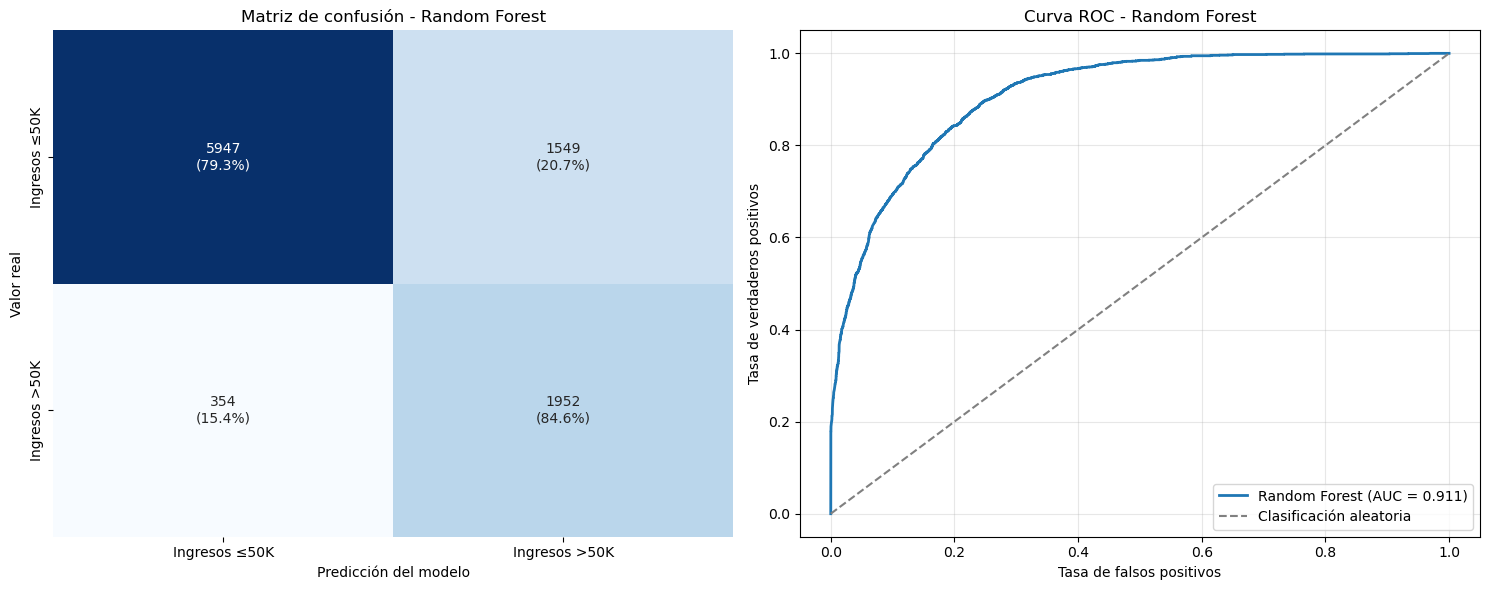

In [125]:
cmBosque = confusion_matrix(
    y_realBosque, y_predBosque, labels=[0, 1]
)

porcentajes = cmBosque / cmBosque.sum(axis=1, keepdims=True) * 100

etiquetas = np.array([
    f"{cmBosque[i, j]}\n({porcentajes[i, j]:.1f}%)"
    for i in range(2)
    for j in range(2)
]).reshape(2, 2)

fprBosque, tprBosque, umbralesBosque = roc_curve(
    y_realBosque, y_probBosque
)

fig, matrix = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cmBosque,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    yticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    ax=matrix[0]
)

matrix[0].set_title("Matriz de confusión - Random Forest")
matrix[0].set_xlabel("Predicción del modelo")
matrix[0].set_ylabel("Valor real")

matrix[1].plot(
    fprBosque, tprBosque,
    label=f"Random Forest (AUC = {aucBosque:.3f})",
    linewidth=2
)

matrix[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

matrix[1].set_title("Curva ROC - Random Forest")
matrix[1].set_xlabel("Tasa de falsos positivos")
matrix[1].set_ylabel("Tasa de verdaderos positivos")
matrix[1].legend()
matrix[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **13. Gradient Boosted Trees (GBT)**

Se entrenó un modelo GBT de 100 iteraciones utilizando PesoClase para compensar el desbalance de ingresos. Obtuvo un Accuracy de 81,70 %, una Precisión de 57,39 %, un Recall de 86,17 %, un F1-Score de 68,90 % y un AUC-ROC de 0,9197.

La matriz de confusión muestra que identificó correctamente 1.987 personas con ingresos superiores a 50K, mientras que 319 no fueron detectadas y 1.475 personas con ingresos bajos fueron clasificadas incorrectamente como altos.

GBT superó a Random Forest en las cinco métricas evaluadas, convirtiéndose en el modelo con mejor desempeño hasta el momento.

In [127]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    maxIter=100,
    maxDepth=5,
    maxBins=64,
    minInstancesPerNode=10,
    stepSize=0.1,
    seed=1234
)

modeloGBT = gbt.fit(trainPonderado)

predGBT = modeloGBT.transform(test)

predGBT.select(
    "Ingresos", "prediction", "probability"
).show(5, truncate=False)

26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1001.2 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1003.4 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1003.9 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1004.5 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1005.4 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1006.9 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1009.0 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1009.5 KiB
26/11/24 22:14:01 WARN DAGScheduler: Broadcasting large task binary with size 1010.1 KiB
26/11/24 22:14:02 WARN DAGScheduler: Broadcasting large task binary with size 1011.0 KiB
26/11/24 22:14:02 WARN DAGScheduler: Broadcasting large task binary with size 1012.6 KiB
26/11/24 22:14:02 WAR

+--------+----------+----------------------------------------+
|Ingresos|prediction|probability                             |
+--------+----------+----------------------------------------+
|1       |1.0       |[0.01748782143545952,0.9825121785645404]|
|1       |1.0       |[0.10324856843404522,0.8967514315659548]|
|0       |1.0       |[0.09850934240540239,0.9014906575945976]|
|1       |1.0       |[0.10039650150512529,0.8996034984948748]|
|0       |0.0       |[0.9560233548718841,0.04397664512811594]|
+--------+----------+----------------------------------------+
only showing top 5 rows



26/11/24 22:14:05 WARN DAGScheduler: Broadcasting large task binary with size 1033.8 KiB


In [128]:
datosGBT = predGBT.select(
    "Ingresos", "prediction", "probability"
).toPandas()

y_realGBT = datosGBT["Ingresos"].astype(int)
y_predGBT = datosGBT["prediction"].astype(int)
y_probGBT = datosGBT["probability"].apply(lambda x: float(x[1]))

accuracyGBT = accuracy_score(y_realGBT, y_predGBT)
precisionGBT = precision_score(y_realGBT, y_predGBT, zero_division=0)
recallGBT = recall_score(y_realGBT, y_predGBT, zero_division=0)
f1GBT = f1_score(y_realGBT, y_predGBT, zero_division=0)
aucGBT = roc_auc_score(y_realGBT, y_probGBT)

print("MÉTRICAS - GRADIENT BOOSTED TREES")
print(f"Accuracy:  {accuracyGBT:.4f}")
print(f"Precisión: {precisionGBT:.4f}")
print(f"Recall:    {recallGBT:.4f}")
print(f"F1-Score:  {f1GBT:.4f}")
print(f"AUC-ROC:   {aucGBT:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_realGBT,
    y_predGBT,
    target_names=["Ingresos ≤50K", "Ingresos >50K"],
    zero_division=0
))

26/11/24 22:14:05 WARN DAGScheduler: Broadcasting large task binary with size 1036.5 KiB


MÉTRICAS - GRADIENT BOOSTED TREES
Accuracy:  0.8170
Precisión: 0.5739
Recall:    0.8617
F1-Score:  0.6890
AUC-ROC:   0.9197

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Ingresos ≤50K       0.95      0.80      0.87      7496
Ingresos >50K       0.57      0.86      0.69      2306

     accuracy                           0.82      9802
    macro avg       0.76      0.83      0.78      9802
 weighted avg       0.86      0.82      0.83      9802



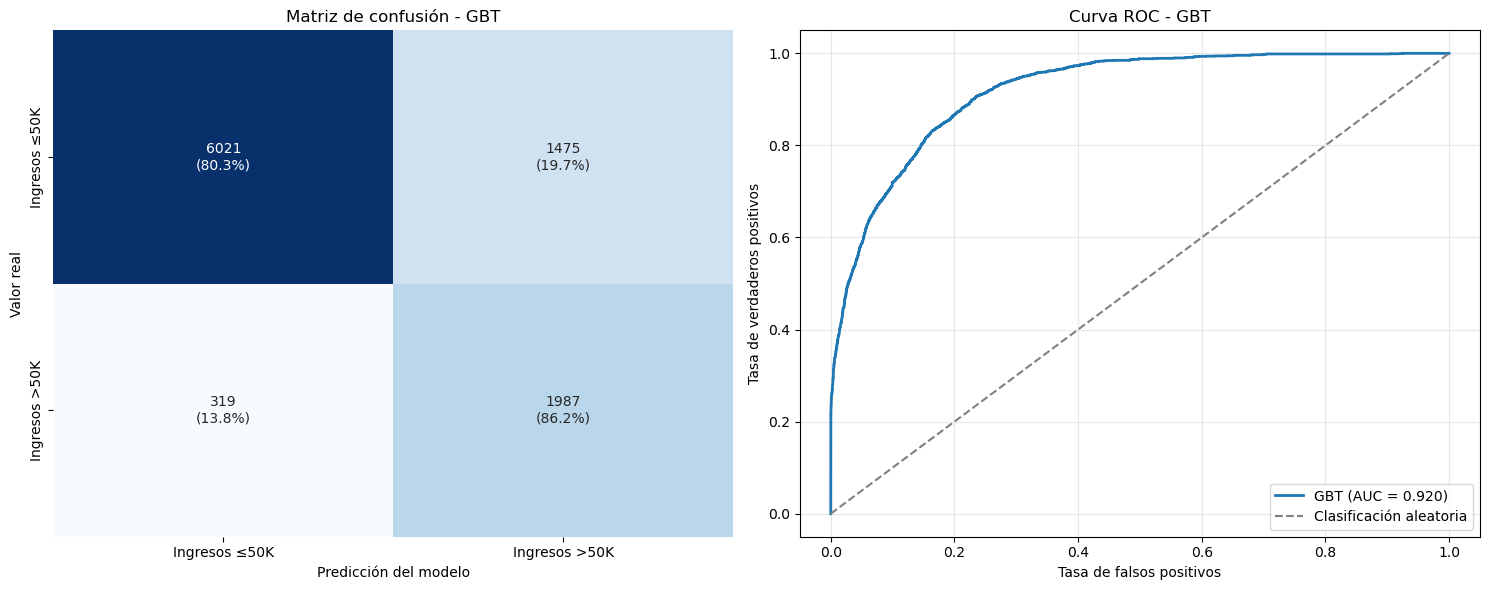

In [129]:
cmGBT = confusion_matrix(
    y_realGBT, y_predGBT, labels=[0, 1]
)

porcentajes = cmGBT / cmGBT.sum(axis=1, keepdims=True) * 100

etiquetas = np.array([
    f"{cmGBT[i, j]}\n({porcentajes[i, j]:.1f}%)"
    for i in range(2)
    for j in range(2)
]).reshape(2, 2)

fprGBT, tprGBT, umbralesGBT = roc_curve(
    y_realGBT, y_probGBT
)

fig, matrix = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cmGBT,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    yticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    ax=matrix[0]
)

matrix[0].set_title("Matriz de confusión - GBT")
matrix[0].set_xlabel("Predicción del modelo")
matrix[0].set_ylabel("Valor real")

matrix[1].plot(
    fprGBT, tprGBT,
    label=f"GBT (AUC = {aucGBT:.3f})",
    linewidth=2
)

matrix[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

matrix[1].set_title("Curva ROC - GBT")
matrix[1].set_xlabel("Tasa de falsos positivos")
matrix[1].set_ylabel("Tasa de verdaderos positivos")
matrix[1].legend()
matrix[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **14. Support Vector Machine (SVM)**

Se entrenó un modelo SVM lineal utilizando PesoClase para compensar el desbalance de ingresos. Obtuvo un Accuracy de 76,68 %, una Precisión de 50,26 %, un Recall de 85,17 %, un F1-Score de 63,21 % y un AUC-ROC de 0,8730.

La matriz de confusión muestra que identificó correctamente 1.964 personas con ingresos superiores a 50K, mientras que 342 no fueron detectadas y 1.944 personas con ingresos bajos fueron clasificadas incorrectamente como altos.

Aunque SVM presenta un Recall elevado, su precisión es la menor de los cinco modelos y su desempeño general es inferior al de GBT, que continúa siendo el mejor modelo evaluado.

In [130]:
from pyspark.ml.classification import LinearSVC

svm = LinearSVC(
    featuresCol="Independientes",
    labelCol="Ingresos",
    weightCol="PesoClase",
    maxIter=100,
    regParam=0.01,
    standardization=True,
    tol=1e-6
)

modeloSVM = svm.fit(trainPonderado)

predSVM = modeloSVM.transform(test)

predSVM.select(
    "Ingresos", "prediction", "rawPrediction"
).show(5, truncate=False)

+--------+----------+----------------------------------------+
|Ingresos|prediction|rawPrediction                           |
+--------+----------+----------------------------------------+
|1       |1.0       |[-11.30797293597404,11.30797293597404]  |
|1       |1.0       |[-0.7630982819713603,0.7630982819713603]|
|0       |1.0       |[-1.6596423834382925,1.6596423834382925]|
|1       |1.0       |[-1.931230560147144,1.931230560147144]  |
|0       |1.0       |[-1.6309027615692422,1.6309027615692422]|
+--------+----------+----------------------------------------+
only showing top 5 rows



In [131]:
datosSVM = predSVM.select(
    "Ingresos", "prediction", "rawPrediction"
).toPandas()

y_realSVM = datosSVM["Ingresos"].astype(int)
y_predSVM = datosSVM["prediction"].astype(int)
y_scoreSVM = datosSVM["rawPrediction"].apply(lambda x: float(x[1]))

accuracySVM = accuracy_score(y_realSVM, y_predSVM)
precisionSVM = precision_score(y_realSVM, y_predSVM, zero_division=0)
recallSVM = recall_score(y_realSVM, y_predSVM, zero_division=0)
f1SVM = f1_score(y_realSVM, y_predSVM, zero_division=0)
aucSVM = roc_auc_score(y_realSVM, y_scoreSVM)

print("MÉTRICAS - SVM")
print(f"Accuracy:  {accuracySVM:.4f}")
print(f"Precisión: {precisionSVM:.4f}")
print(f"Recall:    {recallSVM:.4f}")
print(f"F1-Score:  {f1SVM:.4f}")
print(f"AUC-ROC:   {aucSVM:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_realSVM,
    y_predSVM,
    target_names=["Ingresos ≤50K", "Ingresos >50K"],
    zero_division=0
))

MÉTRICAS - SVM
Accuracy:  0.7668
Precisión: 0.5026
Recall:    0.8517
F1-Score:  0.6321
AUC-ROC:   0.8730

REPORTE DE CLASIFICACIÓN
               precision    recall  f1-score   support

Ingresos ≤50K       0.94      0.74      0.83      7496
Ingresos >50K       0.50      0.85      0.63      2306

     accuracy                           0.77      9802
    macro avg       0.72      0.80      0.73      9802
 weighted avg       0.84      0.77      0.78      9802



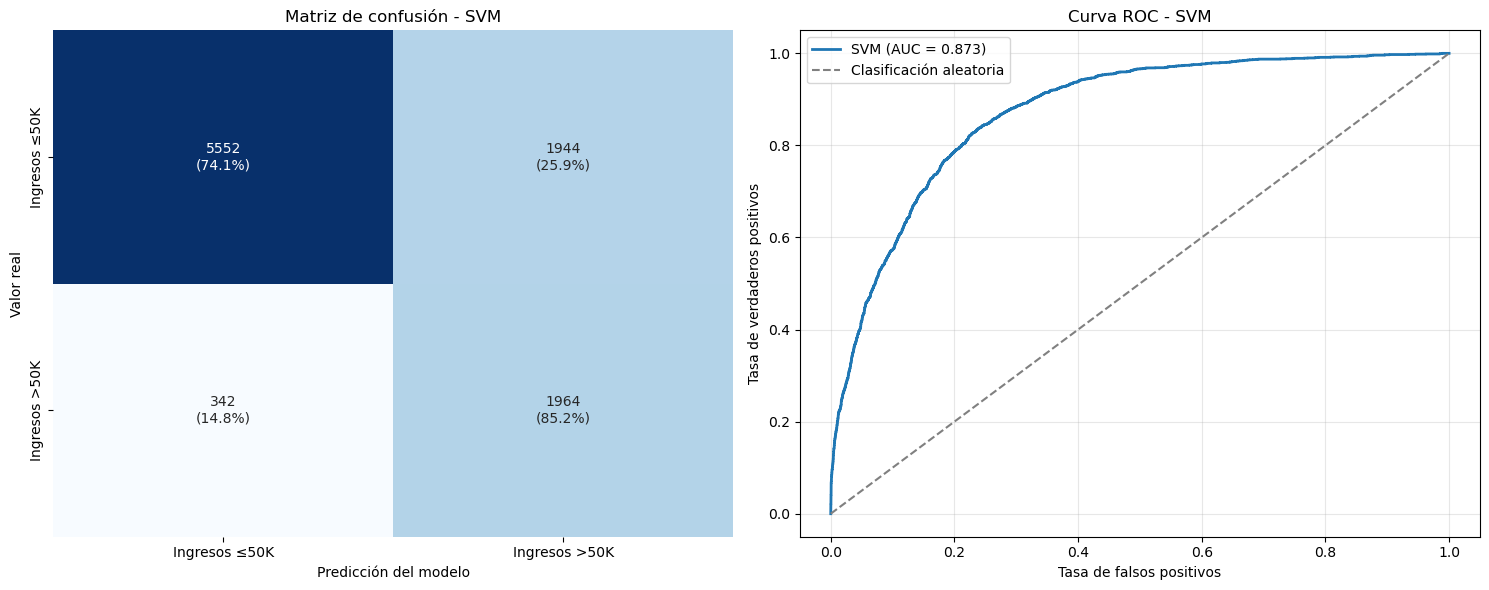

In [132]:
cmSVM = confusion_matrix(
    y_realSVM, y_predSVM, labels=[0, 1]
)

porcentajes = cmSVM / cmSVM.sum(axis=1, keepdims=True) * 100

etiquetas = np.array([
    f"{cmSVM[i, j]}\n({porcentajes[i, j]:.1f}%)"
    for i in range(2)
    for j in range(2)
]).reshape(2, 2)

fprSVM, tprSVM, umbralesSVM = roc_curve(
    y_realSVM, y_scoreSVM
)

fig, matrix = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cmSVM,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    yticklabels=["Ingresos ≤50K", "Ingresos >50K"],
    ax=matrix[0]
)

matrix[0].set_title("Matriz de confusión - SVM")
matrix[0].set_xlabel("Predicción del modelo")
matrix[0].set_ylabel("Valor real")

matrix[1].plot(
    fprSVM, tprSVM,
    label=f"SVM (AUC = {aucSVM:.3f})",
    linewidth=2
)

matrix[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

matrix[1].set_title("Curva ROC - SVM")
matrix[1].set_xlabel("Tasa de falsos positivos")
matrix[1].set_ylabel("Tasa de verdaderos positivos")
matrix[1].legend()
matrix[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **15. Comparación de los modelos**

Se compararon los cinco modelos mediante Accuracy, Precisión, Recall, F1-Score y AUC-ROC, utilizando el mismo conjunto de prueba. Considerando principalmente el F1-Score y el AUC-ROC, se estableció el siguiente ranking:

1. GBT: Obtuvo el mejor desempeño general, con Accuracy de 81,70 %, Precisión de 57,39 %, Recall de 86,17 %, F1-Score de 68,90 % y AUC-ROC de 0,9197. Presentó el mejor equilibrio entre las métricas y la mayor capacidad para diferenciar ambas clases.

2. Random Forest: Ocupó el segundo lugar, con Accuracy de 80,59 %, F1-Score de 67,23 % y AUC-ROC de 0,9105. Sus resultados fueron cercanos a GBT, aunque ligeramente inferiores en todas las métricas.

3. Árbol de decisión: Alcanzó un Accuracy de 79,21 %, F1-Score de 66,45 % y AUC-ROC de 0,8907. Se destacó por obtener el mayor Recall (87,51 %), identificando más personas con ingresos altos que los demás modelos, aunque con más falsos positivos que GBT.

4. Regresión logística: Registró un Accuracy de 77,88 %, F1-Score de 63,39 % y AUC-ROC de 0,8726. Presentó resultados aceptables, pero inferiores a los modelos basados en árboles.

5. SVM: Obtuvo un Accuracy de 76,68 %, F1-Score de 63,21 % y AUC-ROC de 0,8730. Aunque presentó un Recall elevado (85,17 %), obtuvo la menor precisión (50,26 %) y el menor F1-Score.

Las gráficas comparativas y las curvas ROC confirman que los modelos basados en árboles presentaron mejores resultados generales. GBT lideró cuatro de las cinco métricas, mientras que el árbol de decisión obtuvo el mayor Recall.

Por lo tanto, se seleccionó GBT como el mejor modelo de clasificación, seguido por Random Forest y el árbol de decisión.

In [133]:
import pandas as pd

tablaComparacion = pd.DataFrame({
    "Modelo": [
        "Regresión logística",
        "Árbol de decisión",
        "Random Forest",
        "GBT",
        "SVM"
    ],
    "Accuracy": [
        accuracyReg, accuracyArbol, accuracyBosque,
        accuracyGBT, accuracySVM
    ],
    "Precisión": [
        precisionReg, precisionArbol, precisionBosque,
        precisionGBT, precisionSVM
    ],
    "Recall": [
        recallReg, recallArbol, recallBosque,
        recallGBT, recallSVM
    ],
    "F1-Score": [
        f1Reg, f1Arbol, f1Bosque,
        f1GBT, f1SVM
    ],
    "AUC-ROC": [
        aucReg, aucArbol, aucBosque,
        aucGBT, aucSVM
    ]
})

tablaComparacion = tablaComparacion.sort_values(
    "F1-Score", ascending=False
).reset_index(drop=True)

display(tablaComparacion.round(4))

,Modelo,Accuracy,Precisión,Recall,F1-Score,AUC-ROC
0,GBT,0.8170,0.5739,0.8617,0.6890,0.9197
1,Random Forest,0.8059,0.5576,0.8465,0.6723,0.9105
2,Árbol de decisión,0.7921,0.5356,0.8751,0.6645,0.8907
3,Regresión logística,0.7788,0.5191,0.8140,0.6339,0.8726
4,SVM,0.7668,0.5026,0.8517,0.6321,0.8730


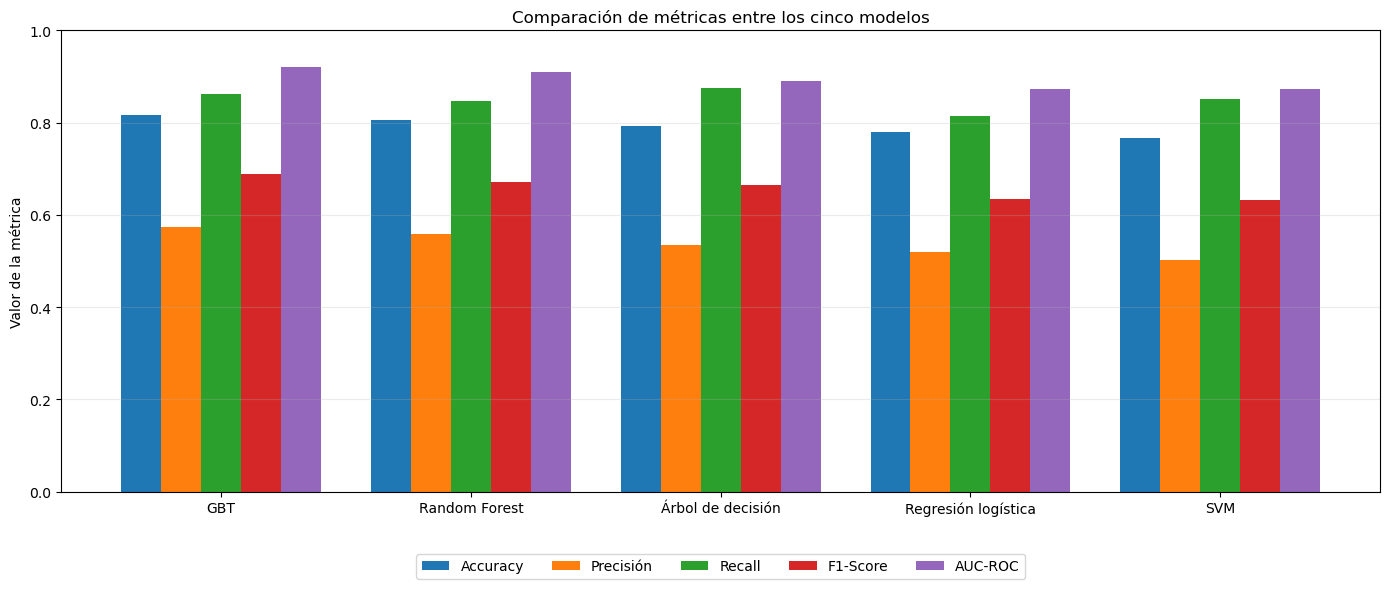

In [134]:
import numpy as np
import matplotlib.pyplot as plt

metricas = [
    "Accuracy", "Precisión", "Recall",
    "F1-Score", "AUC-ROC"
]

x = np.arange(len(tablaComparacion))
ancho = 0.16

fig, ax = plt.subplots(figsize=(14, 6))

for i, metrica in enumerate(metricas):
    ax.bar(
        x + (i - 2) * ancho,
        tablaComparacion[metrica],
        width=ancho,
        label=metrica
    )

ax.set_xticks(x)
ax.set_xticklabels(tablaComparacion["Modelo"])
ax.set_ylim(0, 1)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Comparación de métricas entre los cinco modelos")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

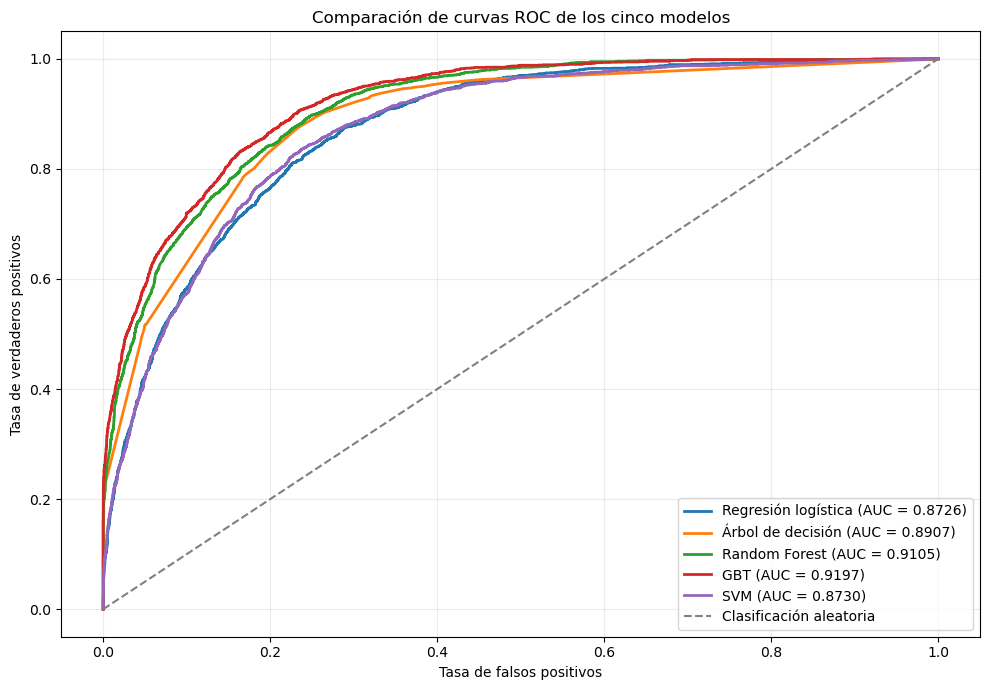

In [135]:
plt.figure(figsize=(10, 7))

curvas = [
    ("Regresión logística", fprReg, tprReg, aucReg),
    ("Árbol de decisión", fprArbol, tprArbol, aucArbol),
    ("Random Forest", fprBosque, tprBosque, aucBosque),
    ("GBT", fprGBT, tprGBT, aucGBT),
    ("SVM", fprSVM, tprSVM, aucSVM)
]

for nombre, fpr, tpr, aucValor in curvas:
    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {aucValor:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

plt.title("Comparación de curvas ROC de los cinco modelos")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### **16. Prueba del modelo seleccionado (GBT)**

Se probó el modelo GBT con una persona ficticia de 42 años, nivel educativo 13, ocupación profesional especializada y una jornada de 45 horas semanales. Se incluyeron las variables creadas anteriormente, GrupoEducativo y PerfilSocioLaboral, ambas clasificadas como Alto.

Los datos se codificaron utilizando los mismos índices del entrenamiento y se transformaron en el vector Independientes para realizar la predicción con el modelo seleccionado.

El modelo clasificó a la persona en la categoría de ingresos superiores a 50K, con un puntaje de 76,15 % para esta clase. Este resultado muestra cómo utilizar GBT con nuevos registros, aunque el puntaje no representa necesariamente una probabilidad calibrada.

In [137]:
persona = (
    42,                                   # Edad
    13,                                   # NivelEducativo
    45.0,                                 # HorasSemana
    0.0,                                  # GananciaCapital
    0.0,                                  # PerdidaCapital
    "Sector privado",                     # TipoTrabajo
    "Nunca casado",                       # EstadoCivil
    "Profesionales especializados",       # Ocupacion
    "No pertenece al núcleo familiar",    # Relacion
    "Blanco",                             # Raza
    "Hombre",                             # Sexo
    "Estados Unidos",                     # PaisOrigen
    "Alto",                               # PerfilSocioLaboral
    "Alto"                                # GrupoEducativo
)

columnasPersona = [
    "Edad", "NivelEducativo", "HorasSemana",
    "GananciaCapital", "PerdidaCapital",
    "TipoTrabajo", "EstadoCivil", "Ocupacion",
    "Relacion", "Raza", "Sexo", "PaisOrigen",
    "PerfilSocioLaboral", "GrupoEducativo"
]

nuevoCaso = sparkAragon.createDataFrame(
    [persona],
    schema=columnasPersona
)

nuevoCaso.show(truncate=False)

+----+--------------+-----------+---------------+--------------+--------------+------------+----------------------------+-------------------------------+------+------+--------------+------------------+--------------+
|Edad|NivelEducativo|HorasSemana|GananciaCapital|PerdidaCapital|TipoTrabajo   |EstadoCivil |Ocupacion                   |Relacion                       |Raza  |Sexo  |PaisOrigen    |PerfilSocioLaboral|GrupoEducativo|
+----+--------------+-----------+---------------+--------------+--------------+------------+----------------------------+-------------------------------+------+------+--------------+------------------+--------------+
|42  |13            |45.0       |0.0            |0.0           |Sector privado|Nunca casado|Profesionales especializados|No pertenece al núcleo familiar|Blanco|Hombre|Estados Unidos|Alto              |Alto          |
+----+--------------+-----------+---------------+--------------+--------------+------------+----------------------------+-----------

In [138]:
datosPersona = dict(zip(columnasPersona, persona))

for variable in categoricas:
    columnaIND = variable + "IND"

    categoriasOriginales = df17.schema[
        columnaIND
    ].metadata["ml_attr"]["vals"]

    valor = datosPersona[variable]

    datosPersona[columnaIND] = float(
        categoriasOriginales.index(valor)
        if valor in categoriasOriginales
        else len(categoriasOriginales)
    )

In [139]:
columnasModelo = varIndependientes.getInputCols()

nuevoCasoNumerico = sparkAragon.createDataFrame(
    [tuple(float(datosPersona[c]) for c in columnasModelo)],
    schema=columnasModelo
)

nuevoVector = varIndependientes.transform(nuevoCasoNumerico)

nuevoVector.select("Independientes").show(truncate=False)

+-------------------------------------------------------+
|Independientes                                         |
+-------------------------------------------------------+
|(14,[0,1,4,6,8,12,13],[42.0,13.0,45.0,1.0,1.0,2.0,1.0])|
+-------------------------------------------------------+



In [140]:
prediccionNueva = modeloGBT.transform(nuevoVector)

resultado = prediccionNueva.first()

prediccion = int(resultado["prediction"])
probabilidad = float(resultado["probability"][1])

print("RESULTADO DE LA PREDICCIÓN")
print("Edad:", datosPersona["Edad"])
print("Grupo educativo:", datosPersona["GrupoEducativo"])
print("Perfil sociolaboral:", datosPersona["PerfilSocioLaboral"])

print("\nIngreso anual predicho:")
print(">50K" if prediccion == 1 else "≤50K")

print(f"Puntaje para ingresos >50K: {probabilidad:.2%}")

RESULTADO DE LA PREDICCIÓN
Edad: 42
Grupo educativo: Alto
Perfil sociolaboral: Alto

Ingreso anual predicho:
>50K
Puntaje para ingresos >50K: 76.15%


### **17. Aprendizajes**

Durante esta actividad fortalecí mis conocimientos en Apache Spark y PySpark, aplicando herramientas que ya conocía para cargar, consultar, transformar y analizar una base de datos de 48.842 registros. También mejoré mi manejo de las funciones de PySpark y la organización de los datos durante las diferentes etapas del proyecto.

Profundicé en el análisis exploratorio de variables cuantitativas y cualitativas, utilizando estadísticas y diferentes visualizaciones para identificar patrones relacionados con los ingresos. Además, reforcé la importancia de revisar los valores desconocidos y extremos antes de tomar decisiones sobre su tratamiento.

Uno de los principales avances fue mejorar mi capacidad para crear nuevas variables a partir del análisis de los datos. Desarrollé tres versiones de PerfilSocioLaboral hasta encontrar una clasificación más útil y construí GrupoEducativo a partir de los cambios observados en las gráficas.

También consolidé mis conocimientos en la preparación de datos para Machine Learning mediante StringIndexer, VectorAssembler y la división entre entrenamiento y prueba. Profundicé en el manejo del desbalance de clases mediante pesos y comprendí mejor la diferencia entre PesoClase y PesoCensal.

Finalmente, reforcé mis habilidades para implementar, evaluar y comparar modelos de clasificación. Al trabajar con regresión logística, árbol de decisión, Random Forest, GBT y SVM, mejoré mi interpretación de las métricas, matrices de confusión y curvas ROC. Esto me permitió seleccionar GBT a partir de sus resultados y aplicar el modelo a una nueva observación, fortaleciendo mi criterio para tomar decisiones basadas en datos.

### **18. Principales hallazgos**

#### **Características generales de la población**

- Se analizaron 48.842 registros, con una edad promedio de 38,64 años y una jornada laboral media de 40,42 horas semanales.
- El 66,85 % de las personas eran hombres y el 33,15 % mujeres.
- El nivel educativo promedio fue de 10,08, en una escala de 1 a 16.
- El 89,74 % de las personas provenía de Estados Unidos, por lo que se agrupó PaisOrigen en tres categorías para simplificar su análisis.
- No se encontraron valores nulos, aunque existían categorías desconocidas en TipoTrabajo, Ocupacion y PaisOrigen, que se conservaron para evitar imputaciones sin suficiente información.
- Se excluyó PesoCensal de los predictores, ya que representa el peso estadístico de cada observación y no una característica individual.

#### **Hallazgos relacionados con los ingresos**

- El 76,07 % de las personas tenía ingresos anuales iguales o inferiores a 50K, mientras que el 23,93 % superaba este valor, evidenciando un desbalance de clases.
- La proporción de ingresos altos aumentó con la edad hasta alcanzar el 39,39 % entre los 45 y 54 años, disminuyendo en los grupos de mayor edad.
- El nivel educativo presentó una asociación importante con los ingresos. Los grupos educativos Bajo, Medio y Alto registraron porcentajes de ingresos superiores a 50K de 5,71 %, 17,71 % y 45,46 %, respectivamente.
- Las ocupaciones con mayores porcentajes de ingresos altos fueron Directivos y gerentes (47,78 %) y Profesionales especializados (45,11 %), mientras que Servicio doméstico registró apenas 1,24 %.
- Las personas casadas con cónyuge civil presentaron un 44,61 % de ingresos altos, frente al 4,55 % de quienes nunca se habían casado.
- Las jornadas de 40 a 60 horas semanales estuvieron asociadas con mayores proporciones de ingresos altos, aunque la relación no fue directamente proporcional.
- Las personas con ganancias de capital positivas presentaron un 61,7 % de ingresos altos, frente al 20,5 % de quienes no registraron ganancias.
- EstadoCivil y Relacion presentaron las mayores asociaciones con Ingresos (0,45), seguidas por Ocupacion (0,35) y NivelEducativo (0,33).
- Se creó PerfilSocioLaboral mediante tres versiones, seleccionando la tercera por presentar la mayor separación entre categorías: 5,56 % de ingresos altos en Bajo, 28,84 % en Medio y 69,18 % en Alto.

#### **Hallazgos de los modelos de Machine Learning**

- Se utilizó PesoClase para compensar el desbalance de ingresos y dar mayor importancia a la clase minoritaria durante el entrenamiento.
- Regresión logística: obtuvo un Accuracy de 77,88 %, Recall de 81,40 %, F1-Score de 63,39 % y AUC-ROC de 0,8726.
- Árbol de decisión: alcanzó el mayor Recall (87,51 %), con un Accuracy de 79,21 %, F1-Score de 66,45 % y AUC-ROC de 0,8907.
- Random Forest: mejoró los resultados generales del árbol de decisión, alcanzando un Accuracy de 80,59 %, F1-Score de 67,23 % y AUC-ROC de 0,9105.
- Gradient Boosted Trees (GBT): obtuvo el mejor desempeño general, con Accuracy de 81,70 %, Precisión de 57,39 %, Recall de 86,17 %, F1-Score de 68,90 % y AUC-ROC de 0,9197.
- SVM: registró un Accuracy de 76,68 %, Recall de 85,17 %, F1-Score de 63,21 % y AUC-ROC de 0,8730, presentando la menor precisión de los cinco modelos (50,26 %).
- La comparación evidenció que los modelos basados en árboles obtuvieron mejores resultados generales, especialmente GBT y Random Forest.
- Finalmente, se probó GBT con una persona ficticia de 42 años, nivel educativo y perfil sociolaboral altos. El modelo predijo ingresos superiores a 50K, con un puntaje de 76,15 % para esta categoría.

En general, GBT fue el modelo seleccionado por presentar el mejor equilibrio entre las métricas evaluadas y la mayor capacidad de discriminación

### **18. Principales hallazgos**

#### **Características generales de la población**

- Se analizaron 48.842 registros, con una edad promedio de 38,64 años y una jornada laboral media de 40,42 horas semanales.
- El 66,85 % de las personas eran hombres y el 33,15 % mujeres.
- El nivel educativo promedio fue de 10,08, en una escala de 1 a 16.
- El 89,74 % de las personas provenía de Estados Unidos, por lo que se agrupó PaisOrigen en tres categorías para simplificar su análisis.
- No se encontraron valores nulos, aunque existían categorías desconocidas en TipoTrabajo, Ocupacion y PaisOrigen, que se conservaron para evitar imputaciones sin suficiente información.
- Se excluyó PesoCensal de los predictores, ya que representa el peso estadístico de cada observación y no una característica individual.

#### **Hallazgos relacionados con los ingresos**

- El 76,07 % de las personas tenía ingresos anuales iguales o inferiores a 50K, mientras que el 23,93 % superaba este valor, evidenciando un desbalance de clases.
- La proporción de ingresos altos aumentó con la edad hasta alcanzar el 39,39 % entre los 45 y 54 años, disminuyendo en los grupos de mayor edad.
- El nivel educativo presentó una asociación importante con los ingresos. Los grupos educativos Bajo, Medio y Alto registraron porcentajes de ingresos superiores a 50K de 5,71 %, 17,71 % y 45,46 %, respectivamente.
- Las ocupaciones con mayores porcentajes de ingresos altos fueron Directivos y gerentes (47,78 %) y Profesionales especializados (45,11 %), mientras que Servicio doméstico registró apenas 1,24 %.
- Las personas casadas con cónyuge civil presentaron un 44,61 % de ingresos altos, frente al 4,55 % de quienes nunca se habían casado.
- Las jornadas de 40 a 60 horas semanales estuvieron asociadas con mayores proporciones de ingresos altos, aunque la relación no fue directamente proporcional.
- Las personas con ganancias de capital positivas presentaron un 61,7 % de ingresos altos, frente al 20,5 % de quienes no registraron ganancias.
- EstadoCivil y Relacion presentaron las mayores asociaciones con Ingresos (0,45), seguidas por Ocupacion (0,35) y NivelEducativo (0,33).
- Se creó PerfilSocioLaboral mediante tres versiones, seleccionando la tercera por presentar la mayor separación entre categorías: 5,56 % de ingresos altos en Bajo, 28,84 % en Medio y 69,18 % en Alto.

#### **Hallazgos de los modelos de Machine Learning**

- Se utilizó PesoClase para compensar el desbalance de ingresos y dar mayor importancia a la clase minoritaria durante el entrenamiento.
- Regresión logística: obtuvo un Accuracy de 77,88 %, Recall de 81,40 %, F1-Score de 63,39 % y AUC-ROC de 0,8726.
- Árbol de decisión: alcanzó el mayor Recall (87,51 %), con un Accuracy de 79,21 %, F1-Score de 66,45 % y AUC-ROC de 0,8907.
- Random Forest: mejoró los resultados generales del árbol de decisión, alcanzando un Accuracy de 80,59 %, F1-Score de 67,23 % y AUC-ROC de 0,9105.
- Gradient Boosted Trees (GBT): obtuvo el mejor desempeño general, con Accuracy de 81,70 %, Precisión de 57,39 %, Recall de 86,17 %, F1-Score de 68,90 % y AUC-ROC de 0,9197.
- SVM: registró un Accuracy de 76,68 %, Recall de 85,17 %, F1-Score de 63,21 % y AUC-ROC de 0,8730, presentando la menor precisión de los cinco modelos (50,26 %).
- La comparación evidenció que los modelos basados en árboles obtuvieron mejores resultados generales, especialmente GBT y Random Forest.
- Finalmente, se probó GBT con una persona ficticia de 42 años, nivel educativo y perfil sociolaboral altos. El modelo predijo ingresos superiores a 50K, con un puntaje de 76,15 % para esta categoría.

En general, GBT fue el modelo seleccionado por presentar el mejor equilibrio entre las métricas evaluadas y la mayor capacidad de discriminación

### **19. Conclusiones**

El análisis de los 48.842 registros permitió identificar patrones importantes entre las características personales, educativas y laborales de la población y sus ingresos anuales. Se encontró que el nivel educativo, la ocupación, la edad y la situación familiar presentan asociaciones relevantes con los ingresos superiores a 50K. En particular, las personas con mayores niveles educativos y ocupaciones profesionales o directivas registraron una mayor proporción de ingresos altos.

Uno de los hallazgos más interesantes fue que las variables pueden aportar información adicional cuando se analizan conjuntamente. La creación de PerfilSocioLaboral permitió diferenciar grupos con porcentajes de ingresos altos del 5,56 %, 28,84 % y 69,18 %, mientras que GrupoEducativo facilitó la identificación de cambios importantes entre los niveles de formación. Esto demuestra la utilidad de construir nuevas características a partir del análisis exploratorio.

En cuanto a los modelos de Machine Learning, GBT presentó el mejor desempeño general, alcanzando un Accuracy de 81,70 %, un F1-Score de 68,90 % y un AUC-ROC de 0,9197. Además, logró identificar correctamente 1.987 de las 2.306 personas con ingresos superiores a 50K del conjunto de prueba. Estos resultados indican que el modelo tiene una buena capacidad para diferenciar los perfiles de ingresos y que los algoritmos basados en árboles pueden resultar especialmente útiles cuando existen relaciones complejas entre las variables.

No obstante, la principal limitación del modelo seleccionado fue su precisión de 57,39 %, ya que clasificó incorrectamente a 1.475 personas con ingresos bajos como altos. En términos prácticos, esto significa que, de cada 100 personas que el modelo identifica con ingresos superiores a 50K, aproximadamente 57 realmente pertenecen a esa categoría dentro del conjunto evaluado. Esta situación puede representar un problema cuando las predicciones se utilizan para tomar decisiones económicas, por lo que no sería adecuado considerar el resultado del modelo como una estimación definitiva de la capacidad financiera de una persona.

Desde una perspectiva empresarial, los resultados podrían ser útiles para estudiar las características del mercado laboral, identificar diferencias salariales entre grupos ocupacionales y orientar investigaciones sobre formación y desarrollo profesional. Por ejemplo, una empresa podría analizar si existen diferencias importantes en los ingresos de trabajadores con niveles educativos y ocupaciones similares, con el propósito de revisar sus políticas de compensación. Sin embargo, sería necesario incorporar información adicional, como experiencia laboral, responsabilidades, antigüedad y ubicación, para realizar comparaciones más justas y evitar conclusiones equivocadas.

En el ámbito educativo y de las políticas públicas, los hallazgos podrían orientar estudios sobre las oportunidades económicas asociadas con diferentes trayectorias de formación. Las diferencias encontradas entre los grupos educativos sugieren que vale la pena investigar el acceso a educación superior, formación técnica y programas de actualización profesional. Asimismo, podrían servir como punto de partida para estudiar las barreras que enfrentan determinados grupos para acceder a ocupaciones mejor remuneradas. Estas aplicaciones deberían enfocarse en analizar tendencias colectivas y diseñar mejores oportunidades, no en clasificar a las personas como más o menos capaces según sus características personales.

Finalmente, considero que el principal aporte del proyecto fue comprobar cómo el análisis de datos y el Machine Learning pueden transformar información individual en conocimiento útil para comprender fenómenos económicos y laborales. El modelo desarrollado representa una herramienta con potencial para apoyar investigaciones, identificar patrones y orientar decisiones basadas en evidencia, pero todavía requiere mejoras antes de utilizarse en situaciones reales. Más allá de obtener una buena métrica, el objetivo debe ser construir modelos confiables, interpretables y responsables, cuyos resultados permitan comprender mejor la realidad y contribuir a decisiones que generen beneficios concretos para las personas y las organizaciones.